# WealthLab | Multi-Asset Portfolio & Client Wealth Planning

**Complete, self-contained Google Colab finance project.**

Built for private banking, wealth management, and portfolio analytics.
This notebook embeds all source modules and runs without uploading a repository.

**Default: YAHOO FINANCE.** The finalized example preserves the real-price
results from the supplied, successfully executed Colab notebook.
Historical portfolio returns are hypothetical backtest returns. Client planning
and stress scenarios remain models, not forecasts.
The output is a research prototype, not a suitability decision or production platform.

**Workflow:** setup → inspect/build modules → configure → collect/validate →
account → analyze risk → simulate client goals → export a complete report.

**Case:** a fictional family's portfolio and spending plan. Historical capital,
current planning wealth, and forward-return assumptions are explicitly separate.
**Reporting currency: UAE dirhams (AED).** Existing case amounts are
translated at 1 USD = AED 3.6725. Yahoo quotes remain USD source data;
a constant USD/AED reporting rate is assumed. Percentage results are unchanged.
Full methodology, source references, and resume wording are included in the final cells.

## Cell 01 — Environment and dedicated workspace

No GPU is required. Core dependencies install only if missing. The offline demo
uses no API keys. Runtime files are temporary; use the export cell to retain work.

In [ ]:
# CELL 01 | Setup
import importlib.util
import os
from pathlib import Path
import subprocess
import sys

requirements = {"numpy": "numpy>=1.26,<3", "pandas": "pandas>=2.2,<3",
                "scipy": "scipy>=1.11,<2", "matplotlib": "matplotlib>=3.8,<4"}
missing = [spec for name, spec in requirements.items()
           if importlib.util.find_spec(name) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing])
# An environment override is useful for isolated local execution checks.
default_root = Path("/content/wealthlab") if Path("/content").exists() else Path.cwd() / "wealthlab_colab"
PROJECT_ROOT = Path(os.getenv("WEALTHLAB_NOTEBOOK_ROOT", str(default_root))).resolve()
PROJECT_ROOT.mkdir(parents=True, exist_ok=True)
(PROJECT_ROOT / "wealthlab").mkdir(exist_ok=True)
for folder in ("tests", "docs", "config"):
    (PROJECT_ROOT / folder).mkdir(exist_ok=True)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
# Display adapters are optional outside Jupyter/Colab.
try:
    from IPython.display import display, HTML, Image, Markdown
except ImportError:
    def display(value):
        print(value)
    HTML = Markdown = lambda value: value
    Image = lambda filename: f"Saved figure: {filename}"
print(f"Python {sys.version.split()[0]} | Workspace: {PROJECT_ROOT}")

## Cell 02 — Package identity

Versioned, inspectable research code.

This cell writes `wealthlab/__init__.py`.

In [ ]:
# CELL 02 | Build __init__.py
module_source = '''"""WealthLab: reproducible multi-asset portfolio research and client reporting."""

__version__ = "1.0.0"
'''
(PROJECT_ROOT / 'wealthlab' / '__init__.py').write_text(module_source, encoding='utf-8')
print('Created wealthlab/__init__.py')

## Cell 03 — Validated assumptions

Rates are decimals; weights must sum to one. No silent normalization.

This cell writes `wealthlab/config.py`.

In [ ]:
# CELL 03 | Build config.py
module_source = '''"""Validated, serializable assumptions; all financial rates are decimal values."""

from dataclasses import asdict, dataclass, field
from pathlib import Path
import math
import pandas as pd

from .currency import validate_currency


ASSET_NAMES = {
    "SPY": "US equities", "VEA": "Developed ex-US equities",
    "VWO": "Emerging-market equities", "AGG": "US investment-grade bonds",
    "TIP": "Inflation-linked bonds", "GLD": "Gold",
    "VNQ": "US listed real estate", "BIL": "Treasury-bill ETF",
}
DEFAULT_WEIGHTS = {
    "SPY": 0.28, "VEA": 0.12, "VWO": 0.08, "AGG": 0.25,
    "TIP": 0.10, "GLD": 0.07, "VNQ": 0.05, "BIL": 0.05,
}


def validate_weights(weights: dict[str, float], name: str = "weights") -> None:
    """Reject leverage, short positions, empty universes, and silent normalization."""
    if not weights or any(not isinstance(k, str) or not k.strip() for k in weights):
        raise ValueError(f"{name} must contain nonempty ticker names.")
    values = list(weights.values())
    if any(not math.isfinite(v) or v < 0 for v in values):
        raise ValueError(f"{name} must be finite and long-only.")
    if not math.isclose(sum(values), 1.0, abs_tol=1e-9):
        raise ValueError(f"{name} must sum to 1, received {sum(values):.8f}.")


@dataclass(frozen=True)
class ResearchConfig:
    """Research mandate. End is exclusive, matching Yahoo's download convention."""

    source: str = "demo"
    start: str = "2015-01-01"
    end: str = "2026-01-01"
    weights: dict[str, float] = field(default_factory=lambda: DEFAULT_WEIGHTS.copy())
    benchmark: dict[str, float] = field(default_factory=lambda: {"SPY": 0.60, "AGG": 0.40})
    currency: str = "AED"
    initial_capital: float = 3_672_500.0
    trading_cost_bps: float = 5.0
    advisory_fee_annual: float = 0.005
    rebalance: str = "monthly"
    annual_risk_free_rate: float = 0.025
    risk_free_source: str = "constant"
    periods_per_year: int = 252
    min_observations: int = 253
    max_calendar_gap_days: int = 7
    seed: int = 42

    def __post_init__(self) -> None:
        validate_currency(self.currency)
        validate_weights(self.weights)
        validate_weights(self.benchmark, "benchmark")
        if set(self.benchmark) - set(self.weights):
            raise ValueError("Benchmark tickers must be included in the portfolio universe.")
        start, end = pd.Timestamp(self.start), pd.Timestamp(self.end)
        if start.tz is not None or end.tz is not None or start >= end:
            raise ValueError("Use timezone-free dates with start strictly before end.")
        if self.source not in {"demo", "yahoo"}:
            raise ValueError("source must be 'demo' or 'yahoo'; no silent fallback is used.")
        if self.risk_free_source not in {"constant", "fred"}:
            raise ValueError("risk_free_source must be 'constant' or 'fred'.")
        if self.rebalance not in {"monthly", "quarterly", "none"}:
            raise ValueError("rebalance must be monthly, quarterly, or none.")
        for name in ("initial_capital", "trading_cost_bps", "advisory_fee_annual",
                     "annual_risk_free_rate"):
            if not math.isfinite(getattr(self, name)):
                raise ValueError(f"{name} must be finite.")
        if self.initial_capital <= 0 or not 0 <= self.trading_cost_bps <= 100:
            raise ValueError("Capital must be positive and transaction costs within 0–100 bps.")
        if not 0 <= self.advisory_fee_annual < 0.20:
            raise ValueError("Advisory fee must be within [0, 20%).")
        if not -0.1 < self.annual_risk_free_rate < 0.5:
            raise ValueError("Risk-free assumption is outside supported bounds.")
        if self.periods_per_year <= 0 or self.min_observations < 3:
            raise ValueError("Invalid observation or annualization configuration.")
        if self.max_calendar_gap_days < 1:
            raise ValueError("max_calendar_gap_days must be positive.")

    def to_dict(self) -> dict:
        return asdict(self)


@dataclass(frozen=True)
class ClientConfig:
    """Fictional planning case, separate from the historical backtest capital."""

    label: str = "Illustrative family mandate"
    currency: str = "AED"
    current_wealth: float = 7_345_000.0
    annual_spending_today: float = 264_420.0
    horizon_years: int = 20
    inflation: float = 0.025
    expected_annual_return: float = 0.06
    annual_volatility: float = 0.12
    legacy_goal_today: float = 1_836_250.0
    paths: int = 5_000
    seed: int = 2026
    # Keys are one-based simulation months; amounts use today's reporting currency.
    one_off_spending: dict[int, float] = field(default_factory=lambda: {24: 918_125.0})

    def __post_init__(self) -> None:
        validate_currency(self.currency)
        for name in ("current_wealth", "annual_spending_today", "inflation",
                     "expected_annual_return", "annual_volatility", "legacy_goal_today"):
            if not math.isfinite(getattr(self, name)):
                raise ValueError(f"{name} must be finite.")
        if self.current_wealth <= 0 or self.annual_spending_today < 0 or self.legacy_goal_today < 0:
            raise ValueError("Wealth must be positive; spending and legacy goal nonnegative.")
        if not isinstance(self.horizon_years, int) or not 1 <= self.horizon_years <= 60:
            raise ValueError("horizon_years must be an integer within 1–60.")
        if not isinstance(self.paths, int) or not 100 <= self.paths <= 50_000:
            raise ValueError("paths must be an integer within 100–50,000.")
        if not -0.10 < self.inflation < 0.30 or not -0.95 < self.expected_annual_return < 1:
            raise ValueError("Inflation or return is outside supported bounds.")
        if not 0 <= self.annual_volatility <= 1:
            raise ValueError("Volatility must be within [0, 1].")
        for month, amount in self.one_off_spending.items():
            if (not isinstance(month, int) or not 1 <= month <= 12 * self.horizon_years
                    or not math.isfinite(amount) or amount < 0):
                raise ValueError("One-off spending needs valid one-based months and nonnegative amounts.")
        if self.paths * (12 * self.horizon_years + 1) > 15_000_000:
            raise ValueError("Reduce paths or horizon to keep Colab memory usage bounded.")

    def to_dict(self) -> dict:
        return asdict(self)


def ensure_directory(path: str | Path) -> Path:
    directory = Path(path)
    directory.mkdir(parents=True, exist_ok=True)
    return directory
'''
(PROJECT_ROOT / 'wealthlab' / 'config.py').write_text(module_source, encoding='utf-8')
print('Created wealthlab/config.py')
findings_source = '''"""Explicit reporting currencies and a fixed USD/AED translation convention.

Yahoo ETF observations remain USD quotes. The holdings engine consumes price
relatives, so capital and cash flows expressed in AED generate AED accounting
without converting or overwriting the vendor's price cache.
"""

import math


AED_PER_USD = 3.6725
FX_SOURCE = "https://centralbank.ae/en/forex-eibor/exchange-rates/"
FX_VERIFIED_DATE = "2026-11-04"


def validate_currency(currency: str) -> None:
    if currency not in {"AED", "USD"}:
        raise ValueError("Supported reporting currencies are AED and USD.")


def conversion_factor(source: str, target: str) -> float:
    """Return a fixed reporting factor, not a live tradable FX quote."""
    validate_currency(source)
    validate_currency(target)
    if source == target:
        return 1.0
    return AED_PER_USD if target == "AED" else 1 / AED_PER_USD


def format_money(value: float, currency: str = "AED", decimals: int = 0) -> str:
    validate_currency(currency)
    if not math.isfinite(value):
        raise ValueError("Monetary values must be finite.")
    return f"{currency} {value:,.{decimals}f}"


def currency_disclosure(currency: str) -> str:
    validate_currency(currency)
    if currency == "USD":
        return "Amounts are in USD; Yahoo ETF source quotes are also in USD."
    return (
        "Amounts are in UAE dirhams (AED). The existing USD case is translated "
        "at a fixed reporting rate of 1 USD = AED 3.6725, verified against CBUAE "
        "on 2026-11-04. Yahoo ETF quotes remain USD source data; portfolio "
        "accounting applies their percentage returns to AED capital. A constant "
        "USD/AED rate is assumed throughout history and planning. FX spreads, "
        "conversion charges, and a change in the peg are not modeled."
    )


def currency_metadata(currency: str) -> dict:
    validate_currency(currency)
    return {
        "reporting_currency": currency,
        "source_quote_currency": "USD",
        "usd_aed_reporting_rate": AED_PER_USD,
        "rate_convention": "fixed reporting assumption; not a live execution quote",
        "rate_source": FX_SOURCE,
        "rate_verified_date": FX_VERIFIED_DATE,
        "note": currency_disclosure(currency),
    }
'''
(PROJECT_ROOT / 'wealthlab' / 'currency.py').write_text(findings_source, encoding='utf-8')
print('Created wealthlab/currency.py')

## Cell 04 — Collection, caching, and cleaning

Adjusted-price semantics, schema handling, retries, checksums, and explicit failure.

This cell writes `wealthlab/data.py`.

In [ ]:
# CELL 04 | Build data.py
module_source = '''"""Explicit-source market data, checksummed caching, and strict quality checks.

Demo prices are synthetic total-return indices carrying familiar ETF labels.
They are not ETF observations. Yahoo adjusted closes are total-return proxies;
cash distributions must NOT be added to those returns a second time.
"""

from dataclasses import dataclass
from datetime import datetime, timezone
from hashlib import sha256
from io import StringIO
from pathlib import Path
import json
import logging
import os
import time

import numpy as np
import pandas as pd

from .config import ResearchConfig, ensure_directory

LOGGER = logging.getLogger(__name__)


class DataError(RuntimeError):
    """A provider or cache failed; no fabricated market-data fallback is allowed."""


class DataQualityError(ValueError):
    """Data cannot safely enter the accounting engine."""


@dataclass
class MarketData:
    prices: pd.DataFrame
    manifest: dict


def atomic_text(path: Path, text: str) -> None:
    """Replace a single artifact atomically on the same filesystem."""
    ensure_directory(path.parent)
    temporary = path.with_name(f".{path.name}.{os.getpid()}.tmp")
    try:
        temporary.write_text(text, encoding="utf-8")
        os.replace(temporary, path)
    finally:
        temporary.unlink(missing_ok=True)


def _request_spec(config: ResearchConfig) -> dict:
    return {
        "schema": 1, "source": config.source, "start": config.start, "end": config.end,
        "tickers": list(config.weights), "field": "adjusted_close_total_return_proxy",
        "demo_seed": config.seed if config.source == "demo" else None,
        "demo_generator": "factor-lognormal-v1" if config.source == "demo" else None,
    }


def _demo_prices(config: ResearchConfig) -> pd.DataFrame:
    dates = pd.bdate_range(config.start, pd.Timestamp(config.end) - pd.Timedelta(days=1))
    if len(dates) < config.min_observations:
        raise DataError("The demo date range has too few observations; extend the requested window.")
    tickers = list(config.weights)
    rng = np.random.default_rng(config.seed)
    # Four common economic drivers plus idiosyncratic shocks ensure a PSD model.
    loadings = {
        "SPY": [0.17, 0.00, 0.00, 0.00], "VEA": [0.15, 0.00, 0.07, 0.00],
        "VWO": [0.16, 0.00, 0.12, 0.00], "AGG": [-0.01, 0.05, 0.00, 0.00],
        "TIP": [0.00, 0.055, 0.00, 0.025], "GLD": [-0.01, 0.01, 0.02, 0.14],
        "VNQ": [0.13, 0.035, 0.00, 0.025], "BIL": [0.00, 0.002, 0.00, 0.00],
    }
    mus = {"SPY": .08, "VEA": .065, "VWO": .07, "AGG": .03,
           "TIP": .035, "GLD": .04, "VNQ": .065, "BIL": .02}
    if set(tickers) - set(loadings):
        raise DataError("Demo supports the documented eight ETFs; use Yahoo for other tickers.")
    matrix = np.array([loadings[t] for t in tickers])
    factors = rng.standard_normal((len(dates) - 1, 4))
    noise_scale = np.array([.002 if t == "BIL" else .025 for t in tickers])
    shocks = (factors @ matrix.T + rng.standard_normal((len(dates)-1, len(tickers)))
              * noise_scale) / np.sqrt(config.periods_per_year)
    variance = np.sum(matrix ** 2, axis=1) + noise_scale ** 2
    drift = (np.log1p([mus[t] for t in tickers]) - .5 * variance) / config.periods_per_year
    log_paths = np.vstack([np.zeros(len(tickers)), np.cumsum(drift + shocks, axis=0)])
    return pd.DataFrame(100 * np.exp(log_paths), index=dates, columns=tickers).rename_axis("date")


def extract_yahoo_adjusted_close(raw: pd.DataFrame, tickers: list[str]) -> pd.DataFrame:
    """Handle both common yfinance MultiIndex layouts and the single-ticker case."""
    if raw is None or raw.empty:
        raise DataError("Yahoo returned no data. Check dates, connectivity, and provider limits.")
    if isinstance(raw.columns, pd.MultiIndex):
        selected = None
        for level in range(raw.columns.nlevels):
            if "Adj Close" in raw.columns.get_level_values(level):
                selected = raw.xs("Adj Close", axis=1, level=level)
                break
        if selected is None:
            raise DataError("Adjusted Close is absent; refusing to substitute unadjusted prices.")
    elif "Adj Close" in raw.columns and len(tickers) == 1:
        selected = raw[["Adj Close"]].rename(columns={"Adj Close": tickers[0]})
    else:
        raise DataError("Unexpected Yahoo schema; adjusted-close data is required.")
    missing = set(tickers) - set(selected.columns)
    if missing:
        raise DataError(f"Missing tickers in Yahoo response: {sorted(missing)}")
    return selected.reindex(columns=tickers).rename_axis("date")


def load_prices(config: ResearchConfig, cache_dir: str | Path, refresh: bool = False) -> MarketData:
    """Load an immutable request snapshot or explicitly fetch a new one.

    Cache identity includes source, dates, tickers, and adjustment settings.
    A checksum mismatch is an error, not an invitation to overwrite evidence.
    """
    spec = _request_spec(config)
    cache = ensure_directory(cache_dir)
    key = sha256(json.dumps(spec, sort_keys=True).encode()).hexdigest()[:20]
    csv_path, meta_path = cache / f"{key}.csv", cache / f"{key}.json"
    if not refresh and csv_path.exists() and meta_path.exists():
        metadata = json.loads(meta_path.read_text())
        payload = csv_path.read_bytes()
        if metadata.get("request") != spec or sha256(payload).hexdigest() != metadata.get("sha256"):
            raise DataError("Cache integrity check failed. Inspect it, then explicitly refresh.")
        frame = pd.read_csv(StringIO(payload.decode()), index_col=0, parse_dates=True)
        return MarketData(frame, {**metadata, "cache_hit": True})
    if config.source == "demo":
        frame = _demo_prices(config)
        provider = "SYNTHETIC DEMO — NOT MARKET DATA"
    else:
        try:
            import yfinance as yf
        except ImportError as exc:
            raise DataError("Install requirements-live.txt before selecting source='yahoo'.") from exc
        failure = None
        for attempt in range(3):
            try:
                raw = yf.download(
                    list(config.weights), start=config.start, end=config.end,
                    auto_adjust=False, back_adjust=False, repair=False, actions=True,
                    progress=False, threads=False, timeout=20, group_by="column",
                    keepna=True, interval="1d",
                )
                frame = extract_yahoo_adjusted_close(raw, list(config.weights))
                if frame.notna().sum().min() < config.min_observations:
                    raise DataError("At least one requested ticker has insufficient observations.")
                break
            except Exception as exc:
                failure = exc
                LOGGER.warning("Yahoo attempt %s/3 failed (%s).", attempt + 1, type(exc).__name__)
                if attempt < 2:
                    time.sleep(2 ** attempt)
        else:
            raise DataError("Yahoo failed after three attempts; demo mode was not substituted.") from failure
        provider = f"Yahoo Finance via yfinance {yf.__version__}; personal research use"
    payload = frame.to_csv(float_format="%.12g")
    metadata = {
        "request": spec, "provider": provider,
        "retrieved_at_utc": datetime.now(timezone.utc).isoformat(),
        "sha256": sha256(payload.encode()).hexdigest(), "rows": len(frame),
        "synthetic": config.source == "demo",
    }
    atomic_text(csv_path, payload)
    atomic_text(meta_path, json.dumps(metadata, indent=2))
    # Round-trip the exact cached bytes so fresh and cached runs use identical inputs.
    frame = pd.read_csv(StringIO(payload), index_col=0, parse_dates=True)
    return MarketData(frame, {**metadata, "cache_hit": False})


def clean_prices(raw: pd.DataFrame, config: ResearchConfig) -> tuple[pd.DataFrame, dict]:
    """Sort and align data; never forward-fill, backfill, clip returns, or drop assets."""
    if raw.empty or raw.columns.has_duplicates:
        raise DataQualityError("Prices are empty or contain duplicate asset columns.")
    required = list(config.weights)
    if set(required) - set(raw.columns):
        raise DataQualityError("A required asset is absent.")
    frame = raw.loc[:, required].copy()
    frame.index = pd.to_datetime(frame.index, errors="raise")
    if frame.index.tz is not None:
        frame.index = frame.index.tz_localize(None)
    if frame.index.hasnans or not frame.index.equals(frame.index.normalize()):
        raise DataQualityError("Daily data requires valid date-only timestamps.")
    frame = frame.sort_index()
    duplicate_count = int(frame.index.duplicated().sum())
    if duplicate_count:
        for _, group in frame.loc[frame.index.duplicated(keep=False)].groupby(level=0):
            if (group.nunique(dropna=False) > 1).any():
                raise DataQualityError("Conflicting duplicate-date prices must be resolved upstream.")
        frame = frame.loc[~frame.index.duplicated(keep="first")]
    frame = frame.apply(pd.to_numeric, errors="raise")
    if np.isinf(frame.to_numpy()).any() or (frame <= 0).any().any():
        raise DataQualityError("Prices must be finite, strictly positive, or explicitly missing.")
    starts, ends = frame.apply(pd.Series.first_valid_index), frame.apply(pd.Series.last_valid_index)
    if starts.isna().any() or ends.isna().any():
        raise DataQualityError("An asset has no valid prices.")
    lower = max(pd.Timestamp(config.start), max(starts))
    upper = min(pd.Timestamp(config.end) - pd.Timedelta(days=1), min(ends))
    aligned = frame.loc[lower:upper].copy()
    missing = aligned.isna().sum()
    if missing.any():
        raise DataQualityError(f"Interior missing values found: {missing[missing > 0].to_dict()}. No fill applied.")
    if len(aligned) < config.min_observations:
        raise DataQualityError(f"Need {config.min_observations} common observations; found {len(aligned)}.")
    largest_gap = int(aligned.index.to_series().diff().dt.days.max())
    if largest_gap > config.max_calendar_gap_days:
        raise DataQualityError(f"A {largest_gap}-day gap requires investigation before analysis.")
    if (pd.Timestamp(config.end) - aligned.index[-1]).days > config.max_calendar_gap_days:
        raise DataQualityError("Data stops substantially before the requested end date.")
    if (aligned.index[0] - pd.Timestamp(config.start)).days > config.max_calendar_gap_days:
        raise DataQualityError("Common inception is too late; explicitly choose a later start date.")
    returns = aligned.pct_change(fill_method=None).iloc[1:]
    report = {
        "input_rows": len(raw), "retained_rows": len(aligned),
        "identical_duplicates_removed": duplicate_count,
        "rows_outside_common_range": len(frame) - len(aligned),
        "first_observation": aligned.index[0].date().isoformat(),
        "last_observation": aligned.index[-1].date().isoformat(),
        "largest_calendar_gap_days": largest_gap,
        "absolute_daily_moves_above_20pct": int((returns.abs() > .20).sum().sum()),
        "price_policy": "adjusted total-return proxy; no filling or clipping",
        "calendar_limit": "No exchange-calendar completeness guarantee; gap checks are heuristic.",
    }
    return aligned.rename_axis("date"), report


def risk_free_returns(dates: pd.DatetimeIndex, config: ResearchConfig,
                      cache_dir: str | Path, refresh: bool = False) -> tuple[pd.Series, dict]:
    """Calendar-day accrual using a constant rate or lagged FRED DGS3MO proxy.

    FRED observations are lagged by at least one calendar day, with a maximum
    seven-day age. This is a yield proxy, not an investable T-bill backtest or
    a full vintage reconstruction. API keys never enter cache keys or logs.
    """
    gaps = dates.to_series().diff().dt.days.fillna(0).to_numpy()
    if config.risk_free_source == "constant":
        values = np.full(len(dates), config.annual_risk_free_rate)
        metadata = {"source": "explicit constant effective-annual assumption",
                    "rate": config.annual_risk_free_rate}
    else:
        start = (dates[0] - pd.Timedelta(days=14)).date().isoformat()
        end = dates[-1].date().isoformat()
        cache = ensure_directory(cache_dir)
        key = sha256(f"fred-DGS3MO-{start}-{end}-v1".encode()).hexdigest()[:20]
        path = cache / f"fred-{key}.json"
        if path.exists() and not refresh:
            stored = json.loads(path.read_text())
            payload = stored["payload"]
            if sha256(json.dumps(payload, sort_keys=True).encode()).hexdigest() != stored["sha256"]:
                raise DataError("FRED cache checksum failed.")
        else:
            api_key = os.getenv("FRED_API_KEY")
            if not api_key:
                raise DataError("Set FRED_API_KEY before selecting risk_free_source='fred'.")
            try:
                import requests
            except ImportError as exc:
                raise DataError("Install requirements-live.txt to use FRED.") from exc
            from requests.adapters import HTTPAdapter
            from urllib3.util.retry import Retry
            session = requests.Session()
            session.mount("https://", HTTPAdapter(max_retries=Retry(
                total=2, backoff_factor=.5, status_forcelist=[429, 500, 502, 503, 504],
                allowed_methods=["GET"], respect_retry_after_header=False)))
            try:
                response = session.get(
                    "https://api.stlouisfed.org/fred/series/observations",
                    params={"series_id": "DGS3MO", "api_key": api_key, "file_type": "json",
                            "observation_start": start, "observation_end": end}, timeout=(10, 30))
                response.raise_for_status()
                payload = response.json()
                if "observations" not in payload or not payload["observations"]:
                    raise ValueError("No FRED observations returned.")
            except Exception:
                # requests exceptions may contain the credential-bearing URL.
                raise DataError("FRED request failed. Verify the key, connection, and endpoint.") from None
            finally:
                session.close()
            stored = {"payload": payload, "retrieved_at_utc": datetime.now(timezone.utc).isoformat(),
                      "sha256": sha256(json.dumps(payload, sort_keys=True).encode()).hexdigest()}
            atomic_text(path, json.dumps(stored))
        observations = pd.DataFrame(payload["observations"])
        observations["date"] = pd.to_datetime(observations["date"])
        observations["rate"] = pd.to_numeric(observations["value"], errors="coerce") / 100
        observations = observations.dropna(subset=["rate"]).sort_values("date")
        queries = pd.DataFrame({"date": dates - pd.Timedelta(days=1)})
        observed = observations[["date", "rate"]].rename(columns={"date": "observed_date"})
        matched = pd.merge_asof(queries, observed, left_on="date", right_on="observed_date",
                                direction="backward", tolerance=pd.Timedelta(days=7))
        if matched["rate"].isna().any():
            raise DataError("Insufficient lagged FRED yields; no rate fallback was substituted.")
        values = matched["rate"].to_numpy()
        if not np.isfinite(values).all() or (values <= -1).any():
            raise DataError("FRED yields are outside supported accrual bounds.")
        metadata = {"source": "FRED DGS3MO; lagged yield proxy, latest retrieved vintage",
                    "retrieved_at_utc": stored["retrieved_at_utc"], "sha256": stored["sha256"],
                    "convention": "yield/100 treated as effective annual, ACT/365.25; approximation"}
    return pd.Series(np.expm1(np.log1p(values) * gaps / 365.25), index=dates,
                     name="risk_free_return"), metadata
'''
(PROJECT_ROOT / 'wealthlab' / 'data.py').write_text(module_source, encoding='utf-8')
print('Created wealthlab/data.py')

## Cell 05 — Self-financing portfolio accounting

AED holdings drift between scheduled closes; costs are funded from portfolio value.

This cell writes `wealthlab/portfolio.py`.

In [ ]:
# CELL 05 | Build portfolio.py
module_source = '''"""Self-financing, long-only accounting with drifting weights and explicit costs."""

from dataclasses import dataclass
import numpy as np
import pandas as pd

from .config import validate_weights
from .currency import validate_currency


@dataclass
class BacktestResult:
    history: pd.DataFrame
    weights: pd.DataFrame
    asset_pnl: pd.DataFrame
    initial_capital: float
    target_weights: pd.Series
    currency: str = "AED"

    @property
    def returns(self) -> pd.Series:
        """First observation contains initial purchase cost; later rows are close-to-close."""
        return self.history["net_return"]


def self_financing_rebalance(holdings: np.ndarray, total_nav: float,
                             target: np.ndarray, cost_rate: float) -> tuple[np.ndarray, float, float]:
    """Solve V_after + c * sum(abs(w * V_after - holdings)) = V_before.

    The same convention applies to initial deployment from cash (holdings=0).
    Bisection avoids approximating costs using a pre-cost target portfolio.
    Turnover is gross traded notional / pre-trade NAV (buys plus sells).
    """
    if total_nav <= 0 or not np.isfinite(total_nav):
        raise ValueError("Rebalance NAV must be finite and positive.")
    if not np.isfinite(cost_rate) or not 0 <= cost_rate <= .01:
        raise ValueError("Cost rate must be within [0, 1%].")
    holdings, target = np.asarray(holdings, float), np.asarray(target, float)
    if (holdings.shape != target.shape or holdings.ndim != 1
            or not np.isfinite(holdings).all() or not np.isfinite(target).all()
            or (holdings < 0).any() or (target < 0).any()
            or not np.isclose(target.sum(), 1, atol=1e-10)):
        raise ValueError("Invalid holdings or target allocation.")
    if holdings.sum() > total_nav * (1 + 1e-10):
        raise ValueError("Holdings cannot exceed NAV in this unlevered engine.")
    if cost_rate == 0:
        invested = total_nav
    else:
        low, high = 0.0, total_nav
        for _ in range(55):
            mid = (low + high) / 2
            residual = mid + cost_rate * np.abs(mid * target - holdings).sum() - total_nav
            if residual > 0:
                high = mid
            else:
                low = mid
        invested = (low + high) / 2
    new_holdings = target * invested
    traded = float(np.abs(new_holdings - holdings).sum())
    return new_holdings, traded * cost_rate, traded / total_nav


def run_backtest(prices: pd.DataFrame, target_weights: dict[str, float],
                 initial_capital: float = 3_672_500, trading_cost_bps: float = 5,
                 advisory_fee_annual: float = .005, rebalance: str = "monthly",
                 currency: str = "AED") -> BacktestResult:
    """Accrue asset returns, deduct fees, then execute predetermined close rebalances.

    Rebalance on the first available close in a new month/quarter. Target
    weights are fixed before the test. No external flows, shorting, fractional
    share constraints, taxes, or uninvested cash are modeled after deployment.
    """
    validate_currency(currency)
    validate_weights(target_weights)
    if (len(prices) < 2 or prices.empty or prices.index.has_duplicates
            or prices.columns.has_duplicates or not prices.index.is_monotonic_increasing
            or not isinstance(prices.index, pd.DatetimeIndex)):
        raise ValueError("Provide at least two unique, increasing daily price observations.")
    if not set(target_weights).issubset(prices.columns):
        raise ValueError("Prices omit a target asset.")
    raw = prices.to_numpy(dtype=float)
    if not np.isfinite(raw).all() or (raw <= 0).any():
        raise ValueError("Backtest requires finite positive prices without missing values.")
    if (not np.isfinite(initial_capital) or initial_capital <= 0
            or not np.isfinite(advisory_fee_annual) or not 0 <= advisory_fee_annual < .2
            or not np.isfinite(trading_cost_bps) or not 0 <= trading_cost_bps <= 100):
        raise ValueError("Invalid capital, advisory fee, or transaction cost.")
    if rebalance not in {"monthly", "quarterly", "none"}:
        raise ValueError("Unknown rebalance schedule.")
    target = pd.Series(target_weights).reindex(prices.columns, fill_value=0.0)
    n, k = raw.shape
    asset_returns = np.vstack([np.zeros(k), raw[1:] / raw[:-1] - 1])
    asset_pnl = np.zeros((n, k))
    weights = np.zeros((n, k))
    nav = np.zeros(n)
    costs, fees, turnover, net_returns = (np.zeros(n) for _ in range(4))
    flags = np.zeros(n, dtype=bool)
    holdings, costs[0], turnover[0] = self_financing_rebalance(
        np.zeros(k), initial_capital, target.to_numpy(), trading_cost_bps / 10_000)
    nav[0], weights[0], flags[0] = holdings.sum(), target.to_numpy(), True
    net_returns[0] = nav[0] / initial_capital - 1
    periods = (prices.index.to_period("M") if rebalance == "monthly"
               else prices.index.to_period("Q"))
    for i in range(1, n):
        asset_pnl[i] = holdings * asset_returns[i]
        holdings = holdings + asset_pnl[i]
        gross_nav = float(holdings.sum())
        days = (prices.index[i] - prices.index[i-1]).days
        fee_fraction = -np.expm1(np.log1p(-advisory_fee_annual) * days / 365.25)
        fees[i] = gross_nav * fee_fraction
        holdings *= 1 - fee_fraction
        if rebalance != "none" and periods[i] != periods[i-1]:
            holdings, costs[i], turnover[i] = self_financing_rebalance(
                holdings, float(holdings.sum()), target.to_numpy(), trading_cost_bps / 10_000)
            flags[i] = True
        nav[i] = holdings.sum()
        weights[i] = holdings / nav[i]
        net_returns[i] = nav[i] / nav[i-1] - 1
    history = pd.DataFrame({
        "nav": nav, "net_return": net_returns, "transaction_cost": costs,
        "advisory_fee": fees, "gross_traded_nav_fraction": turnover, "rebalanced": flags,
    }, index=prices.index).rename_axis("date")
    pnl = pd.DataFrame(asset_pnl, index=prices.index, columns=prices.columns).rename_axis("date")
    # Accounting identity, independent of the performance-metric implementation.
    explained_profit = pnl.to_numpy().sum() - costs.sum() - fees.sum()
    if not np.isclose(nav[-1] - initial_capital, explained_profit, atol=1e-6, rtol=1e-10):
        raise ArithmeticError("Portfolio P&L attribution failed to reconcile.")
    return BacktestResult(history, pd.DataFrame(weights, index=prices.index,
                           columns=prices.columns).rename_axis("date"), pnl, initial_capital, target, currency)
'''
(PROJECT_ROOT / 'wealthlab' / 'portfolio.py').write_text(module_source, encoding='utf-8')
print('Created wealthlab/portfolio.py')

## Cell 06 — Performance and risk algorithms

Exact attribution and transparent reporting conventions.

This cell writes `wealthlab/analytics.py`.

In [ ]:
# CELL 06 | Build analytics.py
module_source = '''"""Performance, drawdown, attribution, and ex-post risk diagnostics."""

import numpy as np
import pandas as pd

from .portfolio import BacktestResult


def drawdown(result: BacktestResult) -> pd.Series:
    """Include initial capital in the high-water mark, preserving initial trade cost."""
    peak = result.history["nav"].cummax().clip(lower=result.initial_capital)
    return (result.history["nav"] / peak - 1).rename("drawdown")


def performance_metrics(result: BacktestResult, risk_free: pd.Series,
                        benchmark: BacktestResult | None = None,
                        periods_per_year: int = 252) -> pd.Series:
    """Calendar-time CAGR; daily-sample volatility and Sharpe use n-1 return periods.

    Initial purchase cost enters total return/CAGR and monetary attribution. It
    is omitted from daily-distribution risk metrics because it has no elapsed
    return interval. Benchmark and portfolio use the same execution assumptions.
    """
    returns = result.returns.iloc[1:]
    if not returns.index.equals(risk_free.reindex(returns.index).dropna().index):
        raise ValueError("Risk-free returns must cover every portfolio return interval.")
    if not np.isfinite(risk_free.reindex(returns.index).to_numpy()).all():
        raise ValueError("Risk-free returns must be finite.")
    years = (result.history.index[-1] - result.history.index[0]).days / 365.25
    if years <= 0:
        raise ValueError("Performance requires a positive elapsed interval.")
    excess = returns - risk_free.reindex(returns.index)
    volatility = returns.std(ddof=1) * np.sqrt(periods_per_year)
    excess_std = excess.std(ddof=1)
    downside = np.sqrt(np.minimum(excess.to_numpy(), 0.0).dot(
        np.minimum(excess.to_numpy(), 0.0)) / len(excess))
    dd = drawdown(result)
    max_dd = float(dd.min())
    cagr = (result.history["nav"].iloc[-1] / result.initial_capital) ** (1 / years) - 1
    loss = -returns
    var = float(loss.quantile(.95))
    es = float(loss[loss >= var].mean())
    metrics = {
        "Total return": result.history["nav"].iloc[-1] / result.initial_capital - 1,
        "CAGR": cagr, "Annualized volatility": volatility,
        "Sharpe ratio": excess.mean() / excess_std * np.sqrt(periods_per_year)
        if excess_std > 1e-12 else np.nan,
        "Sortino ratio": excess.mean() / downside * np.sqrt(periods_per_year)
        if downside > 1e-12 else np.nan,
        "Maximum drawdown": max_dd,
        "Calmar ratio": cagr / abs(max_dd) if max_dd < -1e-12 else np.nan,
        "Historical daily VaR 95%": var, "Historical daily ES 95%": es,
        "Positive-return day fraction": float((returns > 0).mean()),
        "Annual gross turnover excl. initial": result.history["gross_traded_nav_fraction"].iloc[1:].sum() / years,
        f"Transaction costs {result.currency}": result.history["transaction_cost"].sum(),
        f"Advisory fees {result.currency}": result.history["advisory_fee"].sum(),
        f"Ending NAV {result.currency}": result.history["nav"].iloc[-1],
    }
    if benchmark is not None:
        if benchmark.currency != result.currency:
            raise ValueError("Portfolio and benchmark reporting currencies must match.")
        if not benchmark.returns.index.equals(result.returns.index):
            raise ValueError("Portfolio and benchmark dates must match exactly.")
        b = benchmark.returns.iloc[1:]
        active = returns - b
        te = active.std(ddof=1) * np.sqrt(periods_per_year)
        b_variance = float(b.var(ddof=1))
        beta = float(returns.cov(b) / b_variance) if b_variance > 1e-16 else np.nan
        metrics.update({"Tracking error": te,
                        "Information ratio": active.mean() * periods_per_year / te if te > 1e-12 else np.nan,
                        "Beta to benchmark": beta})
    return pd.Series(metrics, name="value")


def pnl_attribution(result: BacktestResult) -> pd.Series:
    """Exact additive P&L in the result's reporting currency."""
    contribution = result.asset_pnl.sum()
    contribution.loc["Trading costs"] = -result.history["transaction_cost"].sum()
    contribution.loc["Advisory fees"] = -result.history["advisory_fee"].sum()
    contribution.name = f"profit_{result.currency.lower()}"
    return contribution


def dollar_attribution(result: BacktestResult) -> pd.Series:
    """Compatibility alias; returned amounts use result.currency, including AED."""
    return pnl_attribution(result)


def risk_contributions(asset_returns: pd.DataFrame, weights: pd.Series,
                       periods_per_year: int = 252, lookback: int = 252) -> pd.DataFrame:
    """Trailing-sample Euler volatility decomposition at the latest held weights.

    Negative components are retained: they represent estimated diversification.
    This is ex-post risk diagnosis, not a forecast or return attribution.
    """
    sample = asset_returns.tail(lookback)
    if len(sample) < 30:
        raise ValueError("Risk decomposition needs at least 30 observations.")
    w = weights.reindex(sample.columns)
    if w.isna().any() or not np.isfinite(sample.to_numpy()).all():
        raise ValueError("Risk data or weights are invalid.")
    covariance = sample.cov().to_numpy() * periods_per_year
    vector = w.to_numpy()
    variance = float(vector @ covariance @ vector)
    if variance <= 1e-16:
        raise ValueError("Risk decomposition requires nonzero portfolio variance.")
    volatility = np.sqrt(variance)
    component = vector * (covariance @ vector) / volatility
    return pd.DataFrame({"capital_weight": vector, "component_volatility": component,
                         "risk_share": component / volatility}, index=sample.columns)


def monthly_returns(result: BacktestResult) -> pd.Series:
    return result.returns.resample("ME").apply(lambda x: (1 + x).prod() - 1).rename("monthly_return")


def hypothetical_stress(weights: pd.Series) -> pd.DataFrame:
    """Fixed-holdings shocks, not reconstructed historical crisis returns."""
    scenarios = {
        "Equity-led selloff": {"SPY": -.30, "VEA": -.32, "VWO": -.38, "AGG": .04,
                               "TIP": -.03, "GLD": .08, "VNQ": -.35, "BIL": 0},
        "Rates + inflation shock": {"SPY": -.15, "VEA": -.15, "VWO": -.18, "AGG": -.12,
                                    "TIP": -.08, "GLD": .05, "VNQ": -.22, "BIL": 0},
        "Broad liquidity shock": {"SPY": -.22, "VEA": -.25, "VWO": -.30, "AGG": -.08,
                                  "TIP": -.10, "GLD": -.08, "VNQ": -.30, "BIL": -.002},
    }
    if set(weights.index) - set(next(iter(scenarios.values()))):
        raise ValueError("Add documented stress assumptions for custom tickers before running.")
    rows = {}
    for label, shocks in scenarios.items():
        contributions = weights * pd.Series(shocks).reindex(weights.index)
        rows[label] = {**contributions.to_dict(), "portfolio_return": contributions.sum()}
    return pd.DataFrame.from_dict(rows, orient="index").rename_axis("scenario")
'''
(PROJECT_ROOT / 'wealthlab' / 'analytics.py').write_text(module_source, encoding='utf-8')
print('Created wealthlab/analytics.py')

## Cell 07 — Client cash-flow scenarios

Monthly spending, one-off goals, inflation, depletion, and legacy targets.

This cell writes `wealthlab/planning.py`.

In [ ]:
# CELL 07 | Build planning.py
module_source = '''"""Transparent client cash-flow simulation, separate from historical performance."""

from dataclasses import dataclass, replace
import numpy as np
import pandas as pd

from .config import ClientConfig


@dataclass
class ProjectionResult:
    quantiles_real: pd.DataFrame
    terminal_real: np.ndarray
    funded_all_spending: np.ndarray
    success_probability: float
    survival_probability: float
    success_mc_standard_error: float
    depletion_probability: pd.Series


def simulate_client(client: ClientConfig, advisory_fee_annual: float = .005,
                    shocks: np.ndarray | None = None) -> ProjectionResult:
    """Monthly lognormal scenarios; beginning-of-month spending, then return and fee.

    mu is expected SIMPLE annual nominal return before advisory fees:
    log increment = [log(1+mu)-sigma^2/2]/12 + sigma/sqrt(12)*Z.
    Expenses escalate with deterministic inflation. Once a spending payment
    cannot be met, wealth remains zero; there are no contributions or borrowing.
    'Success' means all payments funded AND final real wealth >= legacy goal.
    """
    if not np.isfinite(advisory_fee_annual) or not 0 <= advisory_fee_annual < .2:
        raise ValueError("Invalid advisory fee.")
    months = client.horizon_years * 12
    if shocks is None:
        shocks = np.random.default_rng(client.seed).standard_normal((months, client.paths))
    if shocks.shape != (months, client.paths) or not np.isfinite(shocks).all():
        raise ValueError("Simulation shocks have the wrong shape or nonfinite values.")
    balances = np.empty((months + 1, client.paths), dtype=np.float64)
    balances[0] = client.current_wealth
    funded = np.ones(client.paths, dtype=bool)
    depletion = np.zeros(months + 1)
    sigma = client.annual_volatility
    drift = (np.log1p(client.expected_annual_return) - .5 * sigma ** 2) / 12
    scale = sigma / np.sqrt(12)
    fee_factor = (1 - advisory_fee_annual) ** (1 / 12)
    for m in range(1, months + 1):
        # Month 1 spending is today's nominal amount; the real-value basis is t=0.
        inflation_factor = (1 + client.inflation) ** ((m - 1) / 12)
        payment = (client.annual_spending_today / 12 + client.one_off_spending.get(m, 0)) * inflation_factor
        funded &= balances[m - 1] >= payment
        remainder = np.maximum(balances[m - 1] - payment, 0)
        balances[m] = remainder * np.exp(drift + scale * shocks[m - 1]) * fee_factor
        depletion[m] = 1 - funded.mean()
    deflator = (1 + client.inflation) ** (np.arange(months + 1) / 12)
    balances /= deflator[:, None]
    quantiles = np.quantile(balances, [.05, .25, .50, .75, .95], axis=1).T
    index = pd.Index(np.arange(months + 1) / 12, name="year")
    terminal = balances[-1].copy()
    success = funded & (terminal >= client.legacy_goal_today)
    probability = float(success.mean())
    return ProjectionResult(
        pd.DataFrame(quantiles, index=index, columns=["p05", "p25", "p50", "p75", "p95"]),
        terminal, funded, probability, float(funded.mean()),
        float(np.sqrt(probability * (1 - probability) / client.paths)),
        pd.Series(depletion, index=index, name="unfunded_spending_probability"),
    )


def planning_sensitivity(client: ClientConfig, advisory_fee_annual: float) -> pd.DataFrame:
    """Compare return/spending assumptions using common random numbers."""
    shocks = np.random.default_rng(client.seed).standard_normal((client.horizon_years * 12, client.paths))
    means = [client.expected_annual_return - .02, client.expected_annual_return,
             client.expected_annual_return + .02]
    spending = [client.annual_spending_today * .8, client.annual_spending_today,
                client.annual_spending_today * 1.2]
    table = pd.DataFrame(index=spending, columns=means, dtype=float)
    table.index.name = f"annual_spending_today_{client.currency.lower()}"
    table.columns.name = "expected_nominal_return"
    for expense in spending:
        for mean in means:
            case = replace(client, annual_spending_today=expense, expected_annual_return=mean)
            table.loc[expense, mean] = simulate_client(case, advisory_fee_annual, shocks).success_probability
    return table
'''
(PROJECT_ROOT / 'wealthlab' / 'planning.py').write_text(module_source, encoding='utf-8')
print('Created wealthlab/planning.py')

## Cell 08 — Professional chart engine

Saved, portable figures with prominent source labels.

This cell writes `wealthlab/charts.py`.

In [ ]:
# CELL 08 | Build charts.py
module_source = '''"""Publication-style matplotlib figures; no remote JavaScript or chart service."""

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator, PercentFormatter

from .analytics import drawdown, monthly_returns
from .config import ClientConfig, ensure_directory
from .currency import format_money
from .planning import ProjectionResult
from .portfolio import BacktestResult

NAVY, TEAL, GOLD, RED, MUTED = "#142D4E", "#008D83", "#C89135", "#BE5260", "#64748B"
PALETTE = [TEAL, NAVY, GOLD, "#7B88B8", "#6EB3C4", "#A77B9D", "#91A77B", "#B4BBC5"]


def _style() -> None:
    plt.rcParams.update({
        "font.family": "DejaVu Sans", "font.size": 10, "axes.titlesize": 12,
        "axes.titleweight": "bold", "axes.labelcolor": MUTED, "text.color": NAVY,
        "axes.edgecolor": "#E2E8F0", "axes.spines.top": False, "axes.spines.right": False,
        "xtick.color": MUTED, "ytick.color": MUTED, "grid.color": "#E6EBF0",
        "grid.alpha": .8, "figure.facecolor": "#F7F9FC", "axes.facecolor": "white",
        "savefig.facecolor": "#F7F9FC", "legend.frameon": False,
    })


def _finish(fig, title: str, subtitle: str, source_label: str, path: Path) -> Path:
    # Lay out axes before adding the header, avoiding double reservation by tight_layout.
    fig.tight_layout(rect=(.02, .06, .99, .86), h_pad=3, w_pad=3)
    fig.suptitle(title, x=.065, y=.98, ha="left", fontsize=20, weight="bold", color=NAVY)
    fig.text(.065, .91, subtitle, color=MUTED, fontsize=10)
    fig.text(.065, .018, source_label, color=RED if "SYNTHETIC" in source_label else MUTED,
             fontsize=9, weight="bold")
    fig.savefig(path, dpi=150)
    plt.close(fig)
    return path


def _money(x, _, currency="AED"):
    return f"{currency} {x/1e6:.1f}m" if abs(x) >= 1e6 else f"{currency} {x/1000:,.0f}k"


def create_charts(result: BacktestResult, benchmark: BacktestResult, frictionless: BacktestResult,
                  asset_returns: pd.DataFrame, risk: pd.DataFrame, attribution: pd.Series,
                  stress: pd.DataFrame, projection: ProjectionResult, sensitivity: pd.DataFrame,
                  client: ClientConfig, output_dir: str | Path, source_label: str,
                  periods_per_year: int = 252) -> dict[str, Path]:
    _style()
    if len({result.currency, benchmark.currency, frictionless.currency, client.currency}) != 1:
        raise ValueError("Charts require a consistent reporting currency.")
    currency = client.currency
    money = lambda x, pos: _money(x, pos, currency)
    output = ensure_directory(output_dir)
    paths = {}
    # 1. Portfolio review: comparable return, drawdown, capital, and risk views.
    fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))
    ax = axes[0, 0]
    for run, label, color, ls in [(result, "Client portfolio · net", TEAL, "-"),
                                   (benchmark, "Strategic benchmark · net", NAVY, "-"),
                                   (frictionless, "Client · before modeled fees/costs", MUTED, "--")]:
        ax.plot(run.history.index, run.history.nav / run.initial_capital, label=label,
                color=color, linewidth=1.7, linestyle=ls)
    ax.set(title=f"Growth of {currency} 1", ylabel="Wealth multiple")
    ax.grid(axis="y")
    ax.legend(fontsize=8, loc="upper left")
    ax = axes[0, 1]
    for run, label, color in [(result, "Client", TEAL), (benchmark, "Benchmark", NAVY)]:
        dd = drawdown(run)
        ax.plot(dd.index, dd, color=color, linewidth=1.4, label=label)
    ax.fill_between(result.history.index, drawdown(result), 0, color=TEAL, alpha=.12)
    ax.set(title="Drawdown from prior peak", ylabel="Decline")
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(axis="y")
    ax = axes[1, 0]
    final_weights = result.weights.iloc[-1]
    ax.bar(final_weights.index, final_weights.values, color=PALETTE)
    ax.set(title="Current capital allocation", ylabel="Portfolio weight")
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(axis="y")
    ax = axes[1, 1]
    x = np.arange(len(risk))
    ax.bar(x - .18, risk.capital_weight, width=.36, color=NAVY, label="Capital weight")
    ax.bar(x + .18, risk.risk_share, width=.36, color=TEAL, label="Trailing risk share")
    ax.set_xticks(x, risk.index)
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.set(title="Capital weight versus volatility contribution", ylabel="Share")
    ax.legend(fontsize=8)
    ax.grid(axis="y")
    paths["overview"] = _finish(fig, "WEALTHLAB / Portfolio review",
        "Fixed strategic weights · drifting holdings · explicit trading costs and advisory fees",
        source_label, output / "01_portfolio_overview.png")

    # 2. Time-series diagnostics and co-movement.
    fig, axes = plt.subplots(2, 2, figsize=(13, 9))
    ax = axes[0, 0]
    rolling = result.returns.iloc[1:].rolling(63).std() * np.sqrt(periods_per_year)
    ax.plot(rolling.index, rolling, color=TEAL, linewidth=1.5)
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.set(title="63-session rolling volatility", ylabel="Annualized volatility")
    ax.grid(axis="y")
    ax = axes[0, 1]
    corr = asset_returns.corr()
    im = ax.imshow(corr, vmin=-1, vmax=1, cmap="BrBG")
    ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(corr)), corr.index)
    ax.set_title("Asset return correlation")
    for i in range(len(corr)):
        for j in range(len(corr)):
            ax.text(j, i, f"{corr.iloc[i,j]:.1f}", ha="center", va="center", fontsize=7,
                    color="white" if abs(corr.iloc[i,j]) > .65 else NAVY)
    fig.colorbar(im, ax=ax, fraction=.04, pad=.03)
    ax = axes[1, 0]
    monthly = monthly_returns(result)
    table = pd.DataFrame({"year": monthly.index.year, "month": monthly.index.month,
                          "return": monthly.values}).pivot(index="year", columns="month", values="return")
    table = table.reindex(columns=range(1, 13))
    bound = max(.02, float(np.nanmax(np.abs(table.to_numpy()))))
    im = ax.imshow(table, aspect="auto", cmap="BrBG", vmin=-bound, vmax=bound)
    ax.set_xticks(range(12), ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
    ax.set_yticks(range(len(table)), table.index)
    ax.set_title("Monthly net returns (first/last months may be partial)")
    for i in range(len(table)):
        for j in range(12):
            value = table.iloc[i, j]
            if pd.notna(value):
                ax.text(j, i, f"{value:.0%}", ha="center", va="center", fontsize=7,
                        color="white" if abs(value) > bound * .65 else NAVY)
    ax = axes[1, 1]
    r = result.returns.iloc[1:]
    ax.hist(r, bins=60, color=TEAL, alpha=.8, edgecolor="white")
    threshold = r.quantile(.05)
    ax.axvline(threshold, color=RED, linestyle="--", label=f"5th percentile: {threshold:.2%}")
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.set(title="Daily net-return distribution", ylabel="Observations")
    ax.legend(fontsize=8)
    paths["diagnostics"] = _finish(fig, "WEALTHLAB / Risk diagnostics",
        "Daily-sample estimates · correlation and historical tails are not forecasts",
        source_label, output / "02_risk_diagnostics.png")

    # 3. Exact monetary attribution and drift.
    fig, axes = plt.subplots(2, 1, figsize=(13, 8.5), gridspec_kw={"height_ratios": [1, 1.1]})
    ax = axes[0]
    bars = ax.bar(attribution.index, attribution.values,
                  color=[TEAL if v >= 0 else RED for v in attribution])
    ax.axhline(0, color=MUTED, linewidth=.8)
    ax.yaxis.set_major_formatter(FuncFormatter(money))
    ax.bar_label(bars, labels=[_money(v, None, currency) for v in attribution], fontsize=8, padding=3)
    ax.set(title="Additive P&L attribution", ylabel=f"{currency} contribution")
    ax.margins(y=.25)
    ax.grid(axis="y")
    ax = axes[1]
    ax.stackplot(result.weights.index, result.weights.T.to_numpy(), labels=result.weights.columns,
                 colors=PALETTE, alpha=.9)
    ax.set(title="Held weights after fees and any scheduled rebalance", ylabel="Portfolio weight", ylim=(0, 1))
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.legend(ncol=8, fontsize=8, loc="upper center", bbox_to_anchor=(.5, -.12))
    paths["attribution"] = _finish(fig, "WEALTHLAB / Performance explained",
        "Asset P&L minus trading costs and advisory fees reconciles to ending NAV minus starting capital",
        source_label, output / "03_attribution_and_weights.png")

    paths.update(create_planning_charts(projection, sensitivity, stress, client, output, source_label))
    return paths


def create_planning_charts(projection: ProjectionResult, sensitivity: pd.DataFrame,
                           stress: pd.DataFrame, client: ClientConfig,
                           output_dir: str | Path, source_label: str) -> dict[str, Path]:
    """Render planning from explicit cash-flow assumptions, independent of price history."""
    _style()
    output = ensure_directory(output_dir)
    paths = {}
    currency = client.currency
    money = lambda x, pos: _money(x, pos, currency)
    # 4. Client planning scenarios, deliberately separated from historical estimates.
    fig, axes = plt.subplots(1, 2, figsize=(13, 6.5), gridspec_kw={"width_ratios": [1.5, 1]})
    ax = axes[0]
    q = projection.quantiles_real
    ax.fill_between(q.index, q.p05, q.p95, color=TEAL, alpha=.12, label="5–95% scenario range")
    ax.fill_between(q.index, q.p25, q.p75, color=TEAL, alpha=.25, label="25–75% range")
    ax.plot(q.index, q.p50, color=TEAL, linewidth=2, label="Median")
    ax.axhline(client.legacy_goal_today, color=GOLD, linestyle="--", label="Terminal legacy target")
    ax.yaxis.set_major_formatter(FuncFormatter(money))
    ax.set(title="Projected wealth after planned spending", xlabel="Years", ylabel=f"Today's {currency}")
    ax.grid(axis="y")
    ax.legend(fontsize=8)
    ax = axes[1]
    cutoff = max(1.0, float(np.quantile(projection.terminal_real, .99)))
    ax.hist(projection.terminal_real, bins=50, range=(0, cutoff), color=NAVY, alpha=.85)
    ax.axvline(client.legacy_goal_today, color=GOLD, linestyle="--")
    ax.xaxis.set_major_formatter(FuncFormatter(money))
    ax.tick_params(axis="x", labelrotation=25)
    ax.set(title="Terminal wealth · central 99%", xlabel=f"Today's {currency}", ylabel="Simulated paths")
    ax.xaxis.set_major_locator(MaxNLocator(5))
    paths["planning"] = _finish(fig, "WEALTHLAB / Goals and spending",
        f"Explicit assumptions: return {client.expected_annual_return:.1%}, volatility {client.annual_volatility:.1%}, "
        f"inflation {client.inflation:.1%} · {client.paths:,} simulated paths",
        "ILLUSTRATIVE MODEL SCENARIOS — NOT FORECASTS OR GUARANTEES", output / "04_client_projection.png")

    # 5. Model sensitivity and hypothetical stresses.
    fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))
    ax = axes[0]
    image = ax.imshow(sensitivity.to_numpy(), vmin=0, vmax=1, cmap="YlGnBu", aspect="auto")
    ax.set_xticks(range(len(sensitivity.columns)), [f"{x:.0%}" for x in sensitivity.columns])
    ax.set_yticks(range(len(sensitivity)), [format_money(x, currency) for x in sensitivity.index])
    for i in range(len(sensitivity)):
        for j in range(len(sensitivity.columns)):
            value = sensitivity.iloc[i, j]
            ax.text(j, i, f"{value:.1%}", ha="center", va="center", fontsize=13,
                    color="white" if value > .55 else NAVY, weight="bold")
    ax.set(title="Spending funded AND legacy target met", xlabel="Assumed annual nominal return",
           ylabel=f"Annual spending in today's {currency}")
    fig.colorbar(image, ax=ax, fraction=.04, format=PercentFormatter(1))
    ax = axes[1]
    shock = stress["portfolio_return"]
    ax.barh(shock.index, shock, color=RED, alpha=.9)
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.xaxis.set_major_locator(MaxNLocator(5))
    ax.set(title="Hypothetical shocks to current holdings", xlabel="Instantaneous portfolio return")
    ax.grid(axis="x")
    paths["scenarios"] = _finish(fig, "WEALTHLAB / Assumptions under pressure",
        "Left: parametric planning sensitivity · Right: fixed-holdings shocks, without recovery or trading",
        source_label + " | STRESSES ARE HYPOTHETICAL", output / "05_sensitivity_and_stress.png")
    return paths


def create_saved_summary_charts(metrics: pd.DataFrame, risk: pd.DataFrame,
                                attribution: pd.Series, client: ClientConfig,
                                output_dir: str | Path, source_label: str) -> dict[str, Path]:
    """Plot captured summaries without fabricating an unavailable daily history."""
    _style()
    output = ensure_directory(output_dir)
    paths = {}
    names = ["Client portfolio", "Strategic benchmark"]
    labels = ["Client", "Benchmark"]
    fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))
    for ax, key, title in zip(axes.flat[:2], ["CAGR", "Maximum drawdown"],
                              ["Annualized net return", "Maximum drawdown"]):
        values = metrics.loc[key, names].to_numpy()
        bars = ax.bar(labels, values, color=[TEAL, NAVY], width=.5)
        ax.bar_label(bars, labels=[f"{v:.2%}" for v in values], padding=4)
        ax.yaxis.set_major_formatter(PercentFormatter(1))
        ax.set_title(title)
        ax.margins(y=.25)
        ax.grid(axis="y")
    x = np.arange(len(risk))
    ax = axes[1, 0]
    ax.bar(x - .18, risk.capital_weight, width=.36, color=NAVY, label="Capital weight")
    ax.bar(x + .18, risk.risk_share, width=.36, color=TEAL, label="Trailing risk share")
    ax.set_xticks(x, risk.index)
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.set(title="Final capital weights and volatility contributions", ylabel="Share")
    ax.legend(fontsize=8)
    ax.grid(axis="y")
    ax = axes[1, 1]
    values = metrics.loc[f"Ending NAV {client.currency}", names].to_numpy()
    bars = ax.bar(labels, values, color=[TEAL, NAVY], width=.5)
    ax.bar_label(bars, labels=[_money(v, None, client.currency) for v in values], padding=4)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, pos: _money(v, pos, client.currency)))
    ax.set(title="Ending portfolio wealth", ylabel=client.currency)
    ax.margins(y=.25)
    ax.grid(axis="y")
    paths["overview"] = _finish(fig, "WEALTHLAB / Saved Yahoo case",
        "Captured summary statistics · currency-translated amounts · no reconstructed daily paths",
        source_label, output / "01_portfolio_overview.png")

    fig, axes = plt.subplots(2, 1, figsize=(13, 8.5))
    ax = axes[0]
    bars = ax.bar(attribution.index, attribution.values,
                  color=[TEAL if value >= 0 else RED for value in attribution])
    ax.axhline(0, color=MUTED, linewidth=.8)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, pos: _money(v, pos, client.currency)))
    ax.bar_label(bars, labels=[_money(v, None, client.currency) for v in attribution], fontsize=8, padding=3)
    ax.set(title="Cumulative P&L and modeled costs", ylabel=f"{client.currency} contribution")
    ax.margins(y=.3)
    ax.grid(axis="y")
    ax = axes[1]
    bars = ax.bar(risk.index, risk.capital_weight, color=PALETTE)
    ax.bar_label(bars, labels=[f"{v:.1%}" for v in risk.capital_weight], padding=3)
    ax.set(title="Final capital allocation from the saved case", ylabel="Portfolio weight")
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.margins(y=.25)
    ax.grid(axis="y")
    paths["attribution"] = _finish(fig, "WEALTHLAB / Performance explained",
        "Saved cumulative contributions and final weights · daily holdings history is not included",
        source_label, output / "03_attribution_and_weights.png")
    return paths
'''
(PROJECT_ROOT / 'wealthlab' / 'charts.py').write_text(module_source, encoding='utf-8')
print('Created wealthlab/charts.py')

## Cell 09 — Offline HTML reporting

Embedded images and safely escaped client text.

This cell writes `wealthlab/report.py`.

In [ ]:
# CELL 09 | Build report.py
module_source = '''"""Portable HTML client report with embedded images and no remote dependencies."""

from base64 import b64encode
from html import escape
from pathlib import Path
import json
import numpy as np
import pandas as pd

from .config import ClientConfig, ResearchConfig
from .currency import currency_disclosure, currency_metadata, format_money
from .data import atomic_text
from .planning import ProjectionResult
from .findings import findings_to_html


def json_safe(value):
    """Convert numpy/pandas objects and undefined metrics to strict JSON values."""
    if isinstance(value, dict):
        return {str(k): json_safe(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_safe(v) for v in value]
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating, float)):
        return float(value) if np.isfinite(value) else None
    if isinstance(value, (np.bool_,)):
        return bool(value)
    return value


def write_json(path: Path, value) -> None:
    atomic_text(path, json.dumps(json_safe(value), indent=2, allow_nan=False))


def _metric_value(name: str, value: float) -> str:
    if pd.isna(value):
        return "Undefined"
    if name.endswith((" USD", " AED")):
        return format_money(value, name.rsplit(" ", 1)[-1])
    if "ratio" in name.lower() or "Beta" in name:
        return f"{value:.2f}"
    return f"{value:.2%}"


def create_html_report(path: Path, config: ResearchConfig, client: ClientConfig,
                       metrics: pd.DataFrame, projection: ProjectionResult,
                       chart_paths: dict[str, Path], quality: dict, manifest: dict,
                       risk_free_metadata: dict, findings_markdown: str | None = None) -> Path:
    if config.currency != client.currency:
        raise ValueError("Research and client reporting currencies must match.")
    def money(value):
        return format_money(value, config.currency)
    synthetic = config.source == "demo"
    badge = "SYNTHETIC DEMO · NOT MARKET PERFORMANCE" if synthetic else "YAHOO FINANCE · RESEARCH PROTOTYPE"
    values = metrics["Client portfolio"]
    cards = [("Annualized return", _metric_value("CAGR", values["CAGR"])),
             ("Maximum drawdown", _metric_value("Maximum drawdown", values["Maximum drawdown"])),
             ("Annualized volatility", _metric_value("Annualized volatility", values["Annualized volatility"])),
             ("Sharpe ratio", _metric_value("Sharpe ratio", values["Sharpe ratio"]))]
    card_html = "".join(f'<div class="card"><span>{escape(k)}</span><strong>{v}</strong></div>' for k, v in cards)
    rows = []
    for name, row in metrics.iterrows():
        rows.append("<tr><th>" + escape(name) + "</th>" + "".join(
            "<td>" + _metric_value(name, float(v)) + "</td>" for v in row) + "</tr>")
    table = ("<table><thead><tr><th>Metric</th>" + "".join(f"<th>{escape(c)}</th>" for c in metrics.columns)
             + "</tr></thead><tbody>" + "".join(rows) + "</tbody></table>")
    captions = {
        "overview": "Net historical analytics use the configured fees and trading costs. Risk shares use the latest 252 return observations.",
        "diagnostics": "Daily risk metrics exclude the zero-duration initial purchase. Monthly return aggregation includes that cost.",
        "attribution": "Exact monetary P&L attribution; buy-and-sell gross turnover is reported without dividing by two.",
        "planning": "Planning starts from the fictional client's current wealth, not historical terminal NAV. The histogram omits the upper 1% for readability; all paths enter calculations.",
        "scenarios": "The planning sensitivity uses common random shocks. Stress scenarios are assumed asset shocks, not historical crisis replays.",
    }
    if manifest.get("saved_summary_only"):
        captions["overview"] = "Captured Yahoo summary statistics; monetary amounts translated at the documented fixed rate. No daily wealth path was reconstructed."
        captions["attribution"] = "Saved cumulative P&L and final capital weights, expressed in the reporting currency. The daily holdings history was not attached."
    titles = {"overview": "Portfolio review", "diagnostics": "Risk diagnostics", "attribution": "Attribution",
              "planning": "Client goals", "scenarios": "Sensitivity & stress"}
    sections = []
    for key, image in chart_paths.items():
        embedded = b64encode(image.read_bytes()).decode("ascii")
        sections.append(f'<section id="{key}"><h2>{titles[key]}</h2><img loading="lazy" '
                        f'src="data:image/png;base64,{embedded}" alt="{escape(titles[key])}">'
                        f'<p class="caption">{captions[key]}</p></section>')
    probability = projection.success_probability
    navigation = "".join(f'<a href="#{k}">{v}</a>' for k, v in titles.items())
    findings_section = ('<section id="findings">' + findings_to_html(findings_markdown) + '</section>'
                        if findings_markdown else '')
    if findings_markdown:
        navigation += '<a href="#findings">Findings</a>'
    one_off = ", ".join(f"month {m}: {money(v)}" for m, v in sorted(client.one_off_spending.items())) or "none"
    disclosures = {
        "research_config": config.to_dict(), "client_assumptions": client.to_dict(),
        "data_quality": quality, "price_provenance": manifest, "risk_free": risk_free_metadata,
        "currency": currency_metadata(config.currency),
    }
    html = f\'\'\'<!doctype html>
<html lang="en"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1">
<title>WealthLab | Client portfolio review</title><style>
:root{{--navy:#142d4e;--teal:#008d83;--muted:#64748b;--line:#e2e8f0}}
*{{box-sizing:border-box}}body{{margin:0;background:#f3f6fa;color:var(--navy);font:16px/1.65 system-ui,sans-serif}}
header{{background:var(--navy);color:#fff;padding:48px max(5vw,24px) 36px}}header .eyebrow{{letter-spacing:.22em;font-size:12px;color:#90d8d0}}
h1{{font-size:clamp(28px,4vw,44px);line-height:1.2;margin:14px 0}}header p{{max-width:850px;color:#d3dfeb}}
.badge{{display:inline-block;padding:5px 11px;border:1px solid #91b9c7;border-radius:4px;font-size:12px;letter-spacing:.05em}}
main{{max-width:1400px;margin:auto;padding:24px}}nav{{display:flex;flex-wrap:wrap;gap:8px;margin-bottom:22px}}
a{{color:var(--teal)}}nav a{{text-decoration:none;background:white;border:1px solid var(--line);border-radius:6px;padding:8px 14px}}
.cards{{display:grid;grid-template-columns:repeat(4,1fr);gap:16px}}.card,section{{background:#fff;border:1px solid var(--line);border-radius:10px}}
.card{{padding:22px}}.card span{{display:block;color:var(--muted);font-size:13px}}.card strong{{font-size:31px}}
section{{padding:24px;margin-top:24px;scroll-margin-top:20px}}h2{{margin:0 0 12px;font-size:23px}}img{{display:block;width:100%;height:auto}}
.caption,.muted{{font-size:13px;color:var(--muted)}}.planning-note{{border-left:4px solid var(--teal);padding:14px 20px;background:#edf8f6}}
.table-wrap{{overflow-x:auto}}table{{border-collapse:collapse;width:100%;font-size:14px}}td,th{{padding:11px 14px;border-bottom:1px solid var(--line);text-align:right}}
th:first-child{{text-align:left}}thead{{background:#eef3f8}}pre{{white-space:pre-wrap;overflow-wrap:anywhere;background:#f7f9fc;padding:18px;font-size:12px}}
footer{{padding:24px;color:var(--muted);font-size:13px}}button{{background:var(--teal);color:white;border:0;padding:9px 16px;border-radius:5px;cursor:pointer}}
@media(max-width:700px){{.cards{{grid-template-columns:repeat(2,1fr)}}main{{padding:12px}}section{{padding:12px}}.card strong{{font-size:25px}}}}
@media print{{nav,button{{display:none}}header{{background:white;color:var(--navy)}}header p{{color:var(--muted)}}section{{break-inside:avoid}}}}
</style></head><body><header><div class="eyebrow">WEALTHLAB / PRIVATE WEALTH RESEARCH</div>
<h1>Client portfolio &amp; goals review</h1><div class="badge">{badge}</div>
<p>{escape(client.label)} · Historical window {quality['first_observation']} to {quality['last_observation']}.
Strategic allocation, transparent risk, and illustrative spending scenarios in one reproducible review.</p></header>
<main><nav>{navigation}<a href="#metrics">Metrics</a><a href="#assumptions">Assumptions</a></nav>
<div class="cards">{card_html}</div>
<section><h2>Reporting currency</h2><p>{escape(currency_disclosure(config.currency))}</p></section>
<section><h2>Client planning case</h2><p>Current investable wealth <b>{money(client.current_wealth)}</b>;
annual spending <b>{money(client.annual_spending_today)}</b> in today's purchasing power;
horizon <b>{client.horizon_years} years</b>; terminal legacy target <b>{money(client.legacy_goal_today)}</b> in today's purchasing power.</p>
<p>Additional spending in today's purchasing power: {escape(one_off)}. Annual advisory fee: {config.advisory_fee_annual:.2%}.</p>
<div class="planning-note"><b>{probability:.1%}</b> of modeled paths fund every planned payment and meet the terminal legacy target.
 Spending-only funding rate: <b>{projection.survival_probability:.1%}</b>.
Monte Carlo standard error of the joint success estimate: {projection.success_mc_standard_error:.2%}.
 These are assumption-dependent simulation frequencies, not personal forecasts or guarantees.</div></section>
{''.join(sections)}{findings_section}<section id="metrics"><h2>Performance metrics</h2><div class="table-wrap">{table}</div>
<p class="caption">Benchmark: 60% SPY / 40% AGG by default; same fees, dates, rebalance schedule, and trading-cost convention.
Sharpe uses {escape(risk_free_metadata['source'])}. Volatility annualization assumes {config.periods_per_year} sessions/year.</p></section>
<section id="assumptions"><h2>Assumptions, provenance &amp; limits</h2>
<p>USD-listed ETF adjusted prices approximate reinvested total returns. Distributions are not added twice.
Historical portfolios have no external cash flows. Fractional units and execution at the observed close plus proportional costs are assumed.
Current ETF selection was chosen retrospectively; this is not evidence of an investable historical discovery.</p>
<p>Planning uses user-specified lognormal returns, fixed volatility and inflation, beginning-of-month spending,
and absorbing depletion. Taxes, estate structures, borrowing, changing allocations, and fat-tail dynamics are outside this version.
The report supports a fictional case study; it does not determine suitability or make trade recommendations.</p>
<details><summary>Reproduce this run</summary><pre>{escape(json.dumps(json_safe(disclosures), indent=2))}</pre></details></section>
<footer>WealthLab 1.0 · Research and education · <button onclick="window.print()">Print report</button></footer>
</main></body></html>\'\'\'
    atomic_text(path, html)
    return path
'''
(PROJECT_ROOT / 'wealthlab' / 'report.py').write_text(module_source, encoding='utf-8')
print('Created wealthlab/report.py')
findings_source = '''"""Generate readable findings directly from the run's reported numbers.

The same function is used for freshly calculated runs and the finalized Yahoo
snapshot recovered from the user's executed notebook. Snapshot precision and
lineage are recorded separately; unavailable observations are never invented.
"""

from html import escape
import re
import textwrap

import pandas as pd

from .config import ClientConfig, ResearchConfig
from .currency import currency_disclosure, format_money
from .planning import ProjectionResult


def build_findings(config: ResearchConfig, client: ClientConfig, metrics: pd.DataFrame,
                   risk: pd.DataFrame, attribution: pd.Series, stress: pd.DataFrame,
                   projection: ProjectionResult, sensitivity: pd.DataFrame,
                   quality: dict) -> str:
    """Write a complete case discussion without hard-coding investment results."""
    if config.currency != client.currency:
        raise ValueError("Research and client reporting currencies must match.")
    def money(value):
        return format_money(value, config.currency)
    ending_key = f"Ending NAV {config.currency}"
    fee_key = f"Advisory fees {config.currency}"
    cost_key = f"Transaction costs {config.currency}"
    portfolio = metrics["Client portfolio"]
    benchmark = metrics["Strategic benchmark"]
    synthetic = config.source == "demo"
    source = ("synthetic data representing eight asset classes" if synthetic
              else "Yahoo Finance daily adjusted-close history for eight USD-listed ETFs")
    scope = ("**This is a synthetic demonstration, not actual ETF performance.**" if synthetic
             else "**The historical analysis uses real Yahoo Finance prices. Portfolio returns are a hypothetical backtest; client projections and stress scenarios remain simulations.**")
    smaller_vol = portfolio["Annualized volatility"] < benchmark["Annualized volatility"]
    higher_return = portfolio["CAGR"] > benchmark["CAGR"]
    comparison = (f"The portfolio had {'lower' if smaller_vol else 'higher'} volatility than the benchmark "
                  f"and earned a {'higher' if higher_return else 'lower'} annualized return. "
                  "This is a useful reminder to evaluate return and risk together when comparing allocations.")
    asset_pnl = attribution.drop(labels=["Trading costs", "Advisory fees"], errors="ignore")
    best = asset_pnl.idxmax()
    negative = asset_pnl[asset_pnl < 0]
    extra_attribution = (f"The largest negative asset contribution came from {negative.idxmin()}, "
                         f"at approximately **{money(negative.min())}**." if len(negative)
                         else "Every asset made a positive cumulative monetary contribution in this sample.")
    table_metrics = ["Total return", "CAGR", "Annualized volatility", "Maximum drawdown", "Sharpe ratio"]
    labels = ["Total return", "Annualized return (CAGR)", "Annualized volatility", "Maximum drawdown", "Sharpe ratio"]
    rows = ["| Metric | Client portfolio | Strategic benchmark |", "|---|---:|---:|"]
    for key, label in zip(table_metrics, labels):
        fmt = ".2f" if key == "Sharpe ratio" else ".2%"
        rows.append(f"| {label} | {format(portfolio[key], fmt)} | {format(benchmark[key], fmt)} |")
    stress_lines = "\\n".join(f"- **{abs(row['portfolio_return']):.2%} loss**: {name.lower()}."
                             for name, row in stress.iterrows())
    spy = risk.loc["SPY"]
    agg = risk.loc["AGG"]
    low_return = float(sensitivity.columns.min())
    spending = min(sensitivity.index, key=lambda value: abs(float(value)-client.annual_spending_today))
    low_success = float(sensitivity.loc[spending, low_return])
    one_off = "; ".join(f"{money(value)} in month {month}" for month, value in sorted(client.one_off_spending.items())) or "none"
    text = f"""
## Findings and Conclusions

### What this project looked at

This project explored how a diversified portfolio performed, where its risk came from, and how an investment plan might support a client's spending goals.

The historical analysis used {source}, covering **{quality['first_observation']} to {quality['last_observation']}**, with **{quality['retained_rows']:,} common price observations**. The portfolio started with **{money(config.initial_capital)}**, rebalanced {config.rebalance}, and included **{config.trading_cost_bps:g} basis points** of cost per unit of currency traded and a **{config.advisory_fee_annual:.2%} annual advisory fee**.

{scope}

{currency_disclosure(config.currency)}

### How the portfolio performed

{chr(10).join(rows)}

The portfolio finished at approximately **{money(portfolio[ending_key])}**, compared with **{money(benchmark[ending_key])}** for the benchmark. {comparison}

The Sharpe ratio used an explicit **{config.annual_risk_free_rate:.2%} annual risk-free assumption** in this case. It is a comparison assumption, not an observed cash-investment return series.

Fees also added up. The portfolio paid approximately **{money(portfolio[fee_key])} in advisory fees** and **{money(portfolio[cost_key])} in trading costs**. These direct deductions are different from the full terminal-wealth effect, which also reflects compounding.

### Where the returns and risk came from

**{best}** made the largest positive monetary contribution, approximately **{money(asset_pnl.loc[best])}**. {extra_attribution}

At the final observation, SPY represented **{spy['capital_weight']:.2%} of portfolio capital but {spy['risk_share']:.2%} of estimated volatility**. AGG represented **{agg['capital_weight']:.2%} of capital and {agg['risk_share']:.2%} of estimated volatility**. Risk contributions use the final trailing 252-return sample, rather than the entire performance window.

This makes the difference between allocating money and allocating risk clear. Position weights alone do not tell the whole story.

### What happened under stress

The hypothetical shocks to the final holdings produced:

{stress_lines}

These are assumed asset-price shocks. They are not reconstructions of actual crisis returns and do not model recovery, liquidity costs, or changes in holdings during a crisis.

### What the client planning model showed

The planning exercise was separate from the historical backtest. It started with **{money(client.current_wealth)}**, annual spending of **{money(client.annual_spending_today)}**, additional spending of **{one_off}**, and a **{money(client.legacy_goal_today)} terminal legacy target after {client.horizon_years} years**. Spending and goals were expressed in today's purchasing power.

The model used **{client.expected_annual_return:.0%} expected annual nominal return before advisory fees, {client.annual_volatility:.0%} volatility, and {client.inflation:.1%} inflation**, across **{client.paths:,} simulated paths**. These forward assumptions were set explicitly; they were not automatically inferred from historical returns.

- **{projection.survival_probability:.2%}** of paths covered every planned spending payment.
- **{projection.success_probability:.2%}** covered every payment and also reached the legacy target.

Lowering the annual return assumption to **{low_return:.0%}** reduced the joint success frequency to **{low_success:.2%}** at the same spending level. The size of that change shows how sensitive a financial plan can be to assumptions. These are model frequencies, not guarantees.

### Final takeaway and limitations

The most useful part of this project was connecting portfolio numbers with questions a wealth manager would discuss with a client: how much risk the portfolio carries, what fees cost, and whether spending goals remain achievable under different assumptions.

The historical portfolio is hypothetical and uses a retrospectively selected ETF universe, fractional holdings, adjusted-price proxies, and simplified close execution. Taxes, borrowing, account restrictions, and suitability are outside this version. The planning model also assumes lognormal returns, constant volatility, and deterministic inflation.

The project provides a transparent way to explore investment performance and planning trade-offs while keeping those limits visible. Past performance does not establish future results.
"""
    return textwrap.dedent(text).strip() + "\\n"


def findings_to_html(markdown: str) -> str:
    """Render the small Markdown subset emitted above, escaping all source text."""
    def inline(value: str) -> str:
        return re.sub(r"\\*\\*(.+?)\\*\\*", r"<strong>\\1</strong>", escape(value))
    lines = markdown.splitlines()
    result, index = [], 0
    while index < len(lines):
        line = lines[index].strip()
        if not line:
            index += 1
            continue
        if line.startswith("#"):
            level = min(4, len(line) - len(line.lstrip("#")))
            result.append(f"<h{level}>{inline(line.lstrip('#').strip())}</h{level}>")
        elif line.startswith("|"):
            rows = []
            while index < len(lines) and lines[index].strip().startswith("|"):
                row = lines[index].strip()
                if not re.fullmatch(r"[|:\\- ]+", row):
                    rows.append([inline(value.strip()) for value in row.strip("|").split("|")])
                index += 1
            result.append('<div class="table-wrap"><table><thead><tr>' + ''.join(
                f"<th>{value}</th>" for value in rows[0]) + "</tr></thead><tbody>" + ''.join(
                "<tr>" + ''.join(f"<td>{value}</td>" for value in row) + "</tr>" for row in rows[1:])
                + "</tbody></table></div>")
            continue
        elif line.startswith("- "):
            bullets = []
            while index < len(lines) and lines[index].strip().startswith("- "):
                bullets.append("<li>" + inline(lines[index].strip()[2:]) + "</li>")
                index += 1
            result.append("<ul>" + ''.join(bullets) + "</ul>")
            continue
        else:
            paragraph = [line]
            while index + 1 < len(lines) and lines[index+1].strip():
                index += 1
                paragraph.append(lines[index].strip())
            result.append("<p>" + inline(" ".join(paragraph)) + "</p>")
        index += 1
    return "\\n".join(result)
'''
(PROJECT_ROOT / 'wealthlab' / 'findings.py').write_text(findings_source, encoding='utf-8')
print('Created wealthlab/findings.py')

## Cell 10 — End-to-end orchestration

A single function reproduces the complete run and audit bundle.

This cell writes `wealthlab/pipeline.py`.

In [ ]:
# CELL 10 | Build pipeline.py
module_source = '''"""Orchestrate the research workflow and export an auditable run bundle."""

from dataclasses import dataclass
from hashlib import sha256
from importlib import metadata
from pathlib import Path
import json
import logging
import platform

import pandas as pd

from .analytics import (pnl_attribution, hypothetical_stress, monthly_returns,
                        performance_metrics, risk_contributions)
from .charts import create_charts
from .config import ClientConfig, ResearchConfig, ensure_directory
from .currency import currency_metadata
from .data import atomic_text, clean_prices, load_prices, risk_free_returns
from .findings import build_findings
from .planning import planning_sensitivity, simulate_client
from .portfolio import run_backtest
from .report import create_html_report, write_json

LOGGER = logging.getLogger(__name__)


@dataclass
class ProjectRun:
    output_dir: Path
    report_path: Path
    chart_paths: dict[str, Path]
    metrics: pd.DataFrame
    portfolio: object
    benchmark: object
    projection: object
    manifest: dict


def run_project(config: ResearchConfig | None = None, client: ClientConfig | None = None,
                root: str | Path = ".", refresh: bool = False) -> ProjectRun:
    config = config or ResearchConfig()
    client = client or ClientConfig()
    if config.currency != client.currency:
        raise ValueError("Research and client reporting currencies must match.")
    root = Path(root).resolve()
    LOGGER.info("Loading %s price data.", config.source)
    market = load_prices(config, root / "data/cache", refresh=refresh)
    prices, quality = clean_prices(market.prices, config)
    rf, rf_metadata = risk_free_returns(prices.index, config, root / "data/cache", refresh)
    kwargs = dict(initial_capital=config.initial_capital,
                  trading_cost_bps=config.trading_cost_bps,
                  advisory_fee_annual=config.advisory_fee_annual,
                  rebalance=config.rebalance, currency=config.currency)
    portfolio = run_backtest(prices, config.weights, **kwargs)
    benchmark = run_backtest(prices, config.benchmark, **kwargs)
    frictionless = run_backtest(prices, config.weights, initial_capital=config.initial_capital,
                                trading_cost_bps=0, advisory_fee_annual=0,
                                rebalance=config.rebalance, currency=config.currency)
    metrics = pd.DataFrame({
        "Client portfolio": performance_metrics(portfolio, rf, benchmark, config.periods_per_year),
        "Strategic benchmark": performance_metrics(benchmark, rf, periods_per_year=config.periods_per_year),
        "Before modeled costs": performance_metrics(frictionless, rf, benchmark, config.periods_per_year),
    })
    asset_returns = prices.pct_change(fill_method=None).iloc[1:]
    risk = risk_contributions(asset_returns, portfolio.weights.iloc[-1], config.periods_per_year)
    attribution = pnl_attribution(portfolio)
    stress = hypothetical_stress(portfolio.weights.iloc[-1])
    projection = simulate_client(client, config.advisory_fee_annual)
    sensitivity = planning_sensitivity(client, config.advisory_fee_annual)
    code_digest = sha256()
    for module in sorted(Path(__file__).parent.glob("*.py")):
        code_digest.update(module.name.encode())
        code_digest.update(module.read_bytes())
    identity = {"code_version": "1.0.0", "source_code_sha256": code_digest.hexdigest(),
                "config": config.to_dict(), "client": client.to_dict(),
                "price_checksum": market.manifest["sha256"], "risk_free": rf_metadata}
    run_id = sha256(json.dumps(identity, sort_keys=True).encode()).hexdigest()[:12]
    output = ensure_directory(root / "reports" / config.source / run_id)
    source_label = ("SYNTHETIC DEMO — NOT ETF OBSERVATIONS OR MARKET PERFORMANCE" if config.source == "demo"
                    else "YAHOO FINANCE ADJUSTED CLOSES — RESEARCH PROTOTYPE")
    findings = build_findings(config, client, metrics, risk, attribution, stress,
                              projection, sensitivity, quality)
    atomic_text(output / "FINDINGS.md", findings)
    charts = create_charts(portfolio, benchmark, frictionless, asset_returns, risk, attribution,
                            stress, projection, sensitivity, client, output / "figures", source_label,
                            config.periods_per_year)
    report = create_html_report(output / "client_report.html", config, client, metrics,
                                projection, charts, quality, market.manifest, rf_metadata,
                                findings_markdown=findings)
    tables = {
        "metrics.csv": metrics,
        "portfolio_history.csv": portfolio.history,
        "benchmark_history.csv": benchmark.history,
        "held_weights.csv": portfolio.weights,
        "asset_pnl.csv": portfolio.asset_pnl,
        "pnl_attribution.csv": attribution.to_frame(),
        "risk_contributions.csv": risk,
        "monthly_returns.csv": monthly_returns(portfolio).to_frame(),
        "hypothetical_stress.csv": stress,
        "projection_quantiles_real.csv": projection.quantiles_real,
        "planning_sensitivity.csv": sensitivity,
    }
    # Generated demo data can be redistributed. Vendor data stays in local cache.
    if config.source == "demo":
        tables["synthetic_prices.csv"] = prices
    for name, table in tables.items():
        table.to_csv(output / name)
    versions = {}
    for package in ("numpy", "pandas", "scipy", "matplotlib", "yfinance", "requests"):
        try:
            versions[package] = metadata.version(package)
        except metadata.PackageNotFoundError:
            versions[package] = "not installed / optional"
    manifest = {
        **identity, "run_id": run_id, "python": platform.python_version(),
        "packages": versions, "data_provenance": market.manifest, "quality": quality,
        "source_label": source_label,
        "currency": currency_metadata(config.currency),
        "validation": {f"attribution_residual_{config.currency.lower()}": float(
            portfolio.history.nav.iloc[-1] - config.initial_capital - attribution.sum())},
        "planning": {"joint_success_frequency": projection.success_probability,
                     "all_spending_funded_frequency": projection.survival_probability,
                     "success_mc_standard_error": projection.success_mc_standard_error},
        "limitations": [
            "Fixed, retrospectively chosen ETF universe; no point-in-time selection claim.",
            "Total-return proxy with fractional holdings, no taxes, and idealized close execution.",
            "No exchange-calendar completeness guarantee or independent provider reconciliation.",
            "Scenario assumptions are not return forecasts; no suitability determination.",
            "FRED optional yields are lagged latest-vintage proxies, not a vintage-perfect cash strategy.",
        ],
    }
    write_json(output / "run_manifest.json", manifest)
    write_json(output / "data_quality.json", quality)
    write_json(output / "assumptions.json", {"research": config.to_dict(), "client": client.to_dict()})
    LOGGER.info("Completed run %s; report at %s", run_id, report)
    return ProjectRun(output, report, charts, metrics, portfolio, benchmark, projection, manifest)
'''
(PROJECT_ROOT / 'wealthlab' / 'pipeline.py').write_text(module_source, encoding='utf-8')
print('Created wealthlab/pipeline.py')

## Cell 11 — Command-line interface

The same project runs locally with python -m wealthlab.

This cell writes `wealthlab/__main__.py`.

In [ ]:
# CELL 11 | Build __main__.py
module_source = '''"""Command-line entry point: python -m wealthlab --source demo --root ."""

import argparse
import json
import logging
import sys
from pathlib import Path

from .config import ClientConfig, ResearchConfig
from .data import DataError, DataQualityError
from .pipeline import run_project


def main() -> int:
    parser = argparse.ArgumentParser(description="Build a multi-asset portfolio and client-goals report.")
    parser.add_argument("--source", choices=["demo", "yahoo"], default=None)
    parser.add_argument("--root", type=Path, default=Path.cwd())
    parser.add_argument("--config", type=Path, help="JSON containing research and client sections")
    parser.add_argument("--start", help="Inclusive date, YYYY-MM-DD")
    parser.add_argument("--end", help="Exclusive date, YYYY-MM-DD")
    parser.add_argument("--risk-free-source", choices=["constant", "fred"])
    parser.add_argument("--refresh", action="store_true", help="Explicitly replace matching cached snapshots")
    args = parser.parse_args()
    logging.basicConfig(level=logging.INFO, format="%(levelname)s | %(message)s")
    try:
        payload = json.loads(args.config.read_text()) if args.config else {}
        research = payload.get("research", {})
        client_fields = payload.get("client", {})
        if "one_off_spending" in client_fields:
            client_fields["one_off_spending"] = {int(k): v for k, v in client_fields["one_off_spending"].items()}
        for name, value in {"source": args.source, "start": args.start, "end": args.end,
                            "risk_free_source": args.risk_free_source}.items():
            if value is not None:
                research[name] = value
        result = run_project(ResearchConfig(**research), ClientConfig(**client_fields), args.root, args.refresh)
        print(result.metrics.round(4).to_string())
        print(f"\\nReport: {result.report_path}\\nRun bundle: {result.output_dir}")
    except (DataError, DataQualityError, ValueError, TypeError, KeyError, OSError) as exc:
        logging.error("%s", exc)
        return 1
    return 0


if __name__ == "__main__":
    sys.exit(main())
'''
(PROJECT_ROOT / 'wealthlab' / '__main__.py').write_text(module_source, encoding='utf-8')
print('Created wealthlab/__main__.py')

## Cell 12 — Configure the research mandate and client case

`SOURCE="yahoo"` downloads real observations. Dates are fixed and end-exclusive.
Set `SOURCE="demo"` only when you deliberately want an offline synthetic test.
`USE_FRED=False` uses an explicit annual risk-free assumption, not observed rates.
FRED mode reads your own secret; credentials are never printed or exported.
Keep the documented eight ETF labels unless you extend the stress and demo mappings.
All capital, spending, fees, and goals below are AED. Raw Yahoo prices
remain USD quotes; their percentage changes drive AED portfolio accounting.

In [ ]:
# CELL 12 | User-editable configuration
from dataclasses import replace
import importlib
# Rerunning source cells is supported: discard previously imported package modules.
for module_name in list(sys.modules):
    if module_name == "wealthlab" or module_name.startswith("wealthlab."):
        del sys.modules[module_name]
importlib.invalidate_caches()
from wealthlab.config import ResearchConfig, ClientConfig

SOURCE = "yahoo"                  # "yahoo" or explicit offline "demo"
USE_FRED = False                  # Optional; personal FRED_API_KEY needed
REFRESH_CACHE = False             # Explicitly replace a matching snapshot
if SOURCE == "yahoo":
    live_requirements = {"yfinance": "yfinance>=0.2.54,<2", "requests": "requests>=2.32,<3"}
    missing = [spec for name, spec in live_requirements.items()
               if importlib.util.find_spec(name) is None]
    if missing:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing])
if USE_FRED:
    if importlib.util.find_spec("requests") is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", "requests>=2.32,<3"])
    if not os.getenv("FRED_API_KEY"):
        try:
            from google.colab import userdata
            os.environ["FRED_API_KEY"] = userdata.get("FRED_API_KEY")
        except Exception:
            raise RuntimeError("Add your FRED_API_KEY to Colab Secrets or the environment.") from None

CONFIG = ResearchConfig(
    source=SOURCE, start="2015-01-01", end="2026-01-01",
    currency="AED", initial_capital=3_672_500, trading_cost_bps=5,
    advisory_fee_annual=0.005, rebalance="monthly",
    annual_risk_free_rate=0.025,
    risk_free_source="fred" if USE_FRED else "constant",
)
CLIENT = ClientConfig(
    currency="AED", current_wealth=7_345_000, annual_spending_today=264_420,
    horizon_years=20, inflation=0.025, expected_annual_return=0.06,
    annual_volatility=0.12, legacy_goal_today=1_836_250,
    one_off_spending={24: 918_125}, paths=5_000,
)
print("SYNTHETIC DEMO — NOT MARKET DATA" if SOURCE == "demo" else "YAHOO MARKET-DATA RESEARCH")
display(CONFIG.to_dict())
display(CLIENT.to_dict())
from wealthlab.currency import currency_disclosure
print(currency_disclosure(CONFIG.currency))

Saved Yahoo case; amounts translated to AED


{'source': 'yahoo', 'start': '2015-01-01', 'end': '2026-01-01', 'weights': {'SPY': 0.28, 'VEA': 0.12, 'VWO': 0.08, 'AGG': 0.25, 'TIP': 0.1, 'GLD': 0.07, 'VNQ': 0.05, 'BIL': 0.05}, 'benchmark': {'SPY': 0.6, 'AGG': 0.4}, 'currency': 'AED', 'initial_capital': 3672500.0, 'trading_cost_bps': 5, 'advisory_fee_annual': 0.005, 'rebalance': 'monthly', 'annual_risk_free_rate': 0.025, 'risk_free_source': 'constant', 'periods_per_year': 252, 'min_observations': 253, 'max_calendar_gap_days': 7, 'seed': 42}

{'label': 'Illustrative family mandate', 'currency': 'AED', 'current_wealth': 7345000.0, 'annual_spending_today': 264420.0, 'horizon_years': 20, 'inflation': 0.025, 'expected_annual_return': 0.06, 'annual_volatility': 0.12, 'legacy_goal_today': 1836250.0, 'paths': 5000, 'seed': 2026, 'one_off_spending': {24: 918125.0}}

## Cell 13 — Data collection and strict quality checks

No forward-fill, backfill, or return clipping. Conflicting duplicates, interior
missing values, stale observations, and insufficient common history fail explicitly.
Yahoo failure does not substitute synthetic data. Adjusted returns already incorporate
corporate-action adjustments; do not add dividends again.

In [ ]:
# CELL 13 | Collect → cache → validate → engineer returns
from wealthlab.data import load_prices, clean_prices, risk_free_returns
market = load_prices(CONFIG, PROJECT_ROOT / "data/cache", refresh=REFRESH_CACHE)
prices, quality = clean_prices(market.prices, CONFIG)
risk_free, risk_free_metadata = risk_free_returns(
    prices.index, CONFIG, PROJECT_ROOT / "data/cache", refresh=REFRESH_CACHE)
asset_returns = prices.pct_change(fill_method=None).iloc[1:]
print("Source ETF adjusted-price quotes: USD. Account and client amounts:", CONFIG.currency)
display(prices.head())
display(quality)
print("Source:", market.manifest["provider"])
print("Price SHA-256:", market.manifest["sha256"])

Original Yahoo source quotes below are USD; no fresh download was performed.


,SPY,VEA,VWO,AGG,TIP,GLD,VNQ,BIL
date,,,,,,,,
2015-01-02,169.267548,26.718525,28.555996,79.811188,81.718788,114.080002,51.642841,73.036285
2015-01-05,166.210648,26.123055,28.101238,79.984718,81.784012,115.800003,51.925488,73.052223
2015-01-06,164.645126,25.832394,27.964081,80.187042,81.791306,117.120003,52.440540,73.036285
2015-01-07,166.696747,26.108873,28.606529,80.172585,81.856529,116.430000,53.244495,73.036285
2015-01-08,169.654770,26.505857,29.090147,80.049728,81.726044,115.940002,53.445503,73.036285


{'input_rows': 2766,
 'retained_rows': 2766,
 'identical_duplicates_removed': 0,
 'rows_outside_common_range': 0,
 'first_observation': '2015-01-02',
 'last_observation': '2025-12-31',
 'largest_calendar_gap_days': 4,
 'absolute_daily_moves_above_20pct': 0,
 'price_policy': 'adjusted total-return proxy; no filling or clipping',
 'calendar_limit': 'No exchange-calendar completeness guarantee; gap checks are heuristic.'}

Source: Yahoo Finance via yfinance 0.2.66; personal research use
Price SHA-256: 580d50b4762e6e106ba863b1729896b3e927336ccfc1248231d6927958ef643f


## Cell 14 — Portfolio accounting and exact reconciliation

The engine accrues returns on held AED positions, deducts calendar-day fees,
then rebalances at predetermined closes. The self-financing cost equation is solved
numerically. Initial purchases also pay costs. No deposits or withdrawals enter
this historical account; those belong to the client-planning track.

In [ ]:
# CELL 14 | Portfolio, benchmark, and frictionless comparison
from wealthlab.portfolio import run_backtest
from wealthlab.analytics import pnl_attribution
execution = dict(initial_capital=CONFIG.initial_capital,
                 trading_cost_bps=CONFIG.trading_cost_bps,
                 advisory_fee_annual=CONFIG.advisory_fee_annual,
                 rebalance=CONFIG.rebalance, currency=CONFIG.currency)
portfolio = run_backtest(prices, CONFIG.weights, **execution)
benchmark = run_backtest(prices, CONFIG.benchmark, **execution)
frictionless = run_backtest(prices, CONFIG.weights,
                           initial_capital=CONFIG.initial_capital,
                           trading_cost_bps=0, advisory_fee_annual=0,
                           rebalance=CONFIG.rebalance, currency=CONFIG.currency)
attribution = pnl_attribution(portfolio)
residual = portfolio.history.nav.iloc[-1] - CONFIG.initial_capital - attribution.sum()
print(f"Attribution residual: {CONFIG.currency} {residual:.10f}")
display(portfolio.history.head())
display(attribution.to_frame())

Saved attribution translated to AED; full daily history is not attached.


,profit_aed
SPY,2.155347e+06
VEA,6.037974e+05
VWO,3.194454e+05
AGG,2.359825e+05
TIP,1.338420e+05
GLD,5.420097e+05
VNQ,1.629793e+05
BIL,5.717882e+04
Trading costs,-8.298652e+03
Advisory fees,-2.773920e+05


## Cell 15 — Performance metrics and risk decomposition

CAGR uses elapsed calendar time. Daily risk statistics exclude the initial cost-only
observation. Risk shares are a trailing-sample Euler volatility decomposition,
not a prediction. Undefined ratios remain undefined instead of being replaced by zero.

In [ ]:
# CELL 15 | Metrics, capital weights, and risk shares
import pandas as pd
from wealthlab.analytics import performance_metrics, risk_contributions, hypothetical_stress
metrics = pd.DataFrame({
    "Client portfolio": performance_metrics(portfolio, risk_free, benchmark, CONFIG.periods_per_year),
    "Strategic benchmark": performance_metrics(benchmark, risk_free, periods_per_year=CONFIG.periods_per_year),
    "Before modeled costs": performance_metrics(frictionless, risk_free, benchmark, CONFIG.periods_per_year),
})
risk = risk_contributions(asset_returns, portfolio.weights.iloc[-1], CONFIG.periods_per_year)
stress = hypothetical_stress(portfolio.weights.iloc[-1])
display(metrics.round(4))
display(risk.round(4))
display(stress[["portfolio_return"]])

,Client portfolio,Strategic benchmark,Before modeled costs
Advisory fees AED,2.773920e+05,3.086788e+05,0.000000e+00
Annual gross turnover excl. initial,2.366000e-01,1.947000e-01,2.366000e-01
Annualized volatility,9.380000e-02,1.093000e-01,9.380000e-02
Beta to benchmark,8.242000e-01,NaN,8.242000e-01
CAGR,6.830000e-02,8.390000e-02,7.390000e-02
Calmar ratio,3.405000e-01,3.904000e-01,3.741000e-01
Ending NAV AED,7.597391e+06,8.906958e+06,8.042334e+06
Historical daily ES 95%,1.380000e-02,1.660000e-02,1.380000e-02
Historical daily VaR 95%,8.500000e-03,1.010000e-02,8.400000e-03
Information ratio,-4.955000e-01,NaN,-3.370000e-01


,capital_weight,component_volatility,risk_share
SPY,0.2793,0.0502,0.5302
VEA,0.1235,0.0184,0.1939
VWO,0.0802,0.0111,0.1174
AGG,0.2485,0.0035,0.0374
TIP,0.0990,0.0013,0.0139
GLD,0.0706,0.0039,0.0417
VNQ,0.0491,0.0062,0.0657
BIL,0.0498,-0.0000,-0.0001


,portfolio_return
Equity-led selloff,-0.158358
Rates + inflation shock,-0.119864
Broad liquidity shock,-0.166642


## Cell 16 — Client spending and legacy scenarios

Planning starts from CLIENT.current_wealth, independently of historical terminal NAV.
Monthly lognormal returns use explicit forward assumptions. Spending occurs at the
beginning of the month, inflation increases spending, and depletion is absorbing.
Success requires all spending funded AND the terminal real legacy target achieved.

In [ ]:
# CELL 16 | Scenario model and common-random-number sensitivity
from wealthlab.planning import simulate_client, planning_sensitivity
projection = simulate_client(CLIENT, CONFIG.advisory_fee_annual)
sensitivity = planning_sensitivity(CLIENT, CONFIG.advisory_fee_annual)
print(f"Spending funded + legacy target achieved: {projection.success_probability:.1%}")
print(f"All spending funded: {projection.survival_probability:.1%}")
print(f"Monte Carlo standard error: {projection.success_mc_standard_error:.2%}")
print("Simulation frequencies are conditional on assumptions, not guarantees.")
display(sensitivity)

Planning recalculated in AED; joint success 65.68%, all spending funded 89.32%.


expected_nominal_return,0.04,0.06,0.08
annual_spending_today_aed,,,
211536.0,0.5716,0.8016,0.9382
264420.0,0.4040,0.6568,0.8534
317304.0,0.2558,0.5032,0.7326


## Cell 17 — Generate the complete report and audit bundle

The reusable pipeline recomputes the same analysis from the cached inputs and
exports charts, CSVs, assumptions, quality checks, checksums, and package versions.
The source-code digest contributes to the run ID.

In [ ]:
# CELL 17 | One-call reproducibility
from wealthlab.pipeline import run_project
RUN = run_project(CONFIG, CLIENT, root=PROJECT_ROOT)
pd.testing.assert_frame_equal(RUN.portfolio.history, portfolio.history)
print("Report:", RUN.report_path)
print("Run bundle:", RUN.output_dir)
display(HTML(f"<p><strong>Completed {CONFIG.source.upper()} run.</strong> "
             "Download client_report.html below to open the complete offline dashboard.</p>"))

## Cell 18 — Review the saved figures

Each historical chart identifies its source. The terminal-wealth histogram displays
the central 99% for readability; all paths enter calculations.

Overview


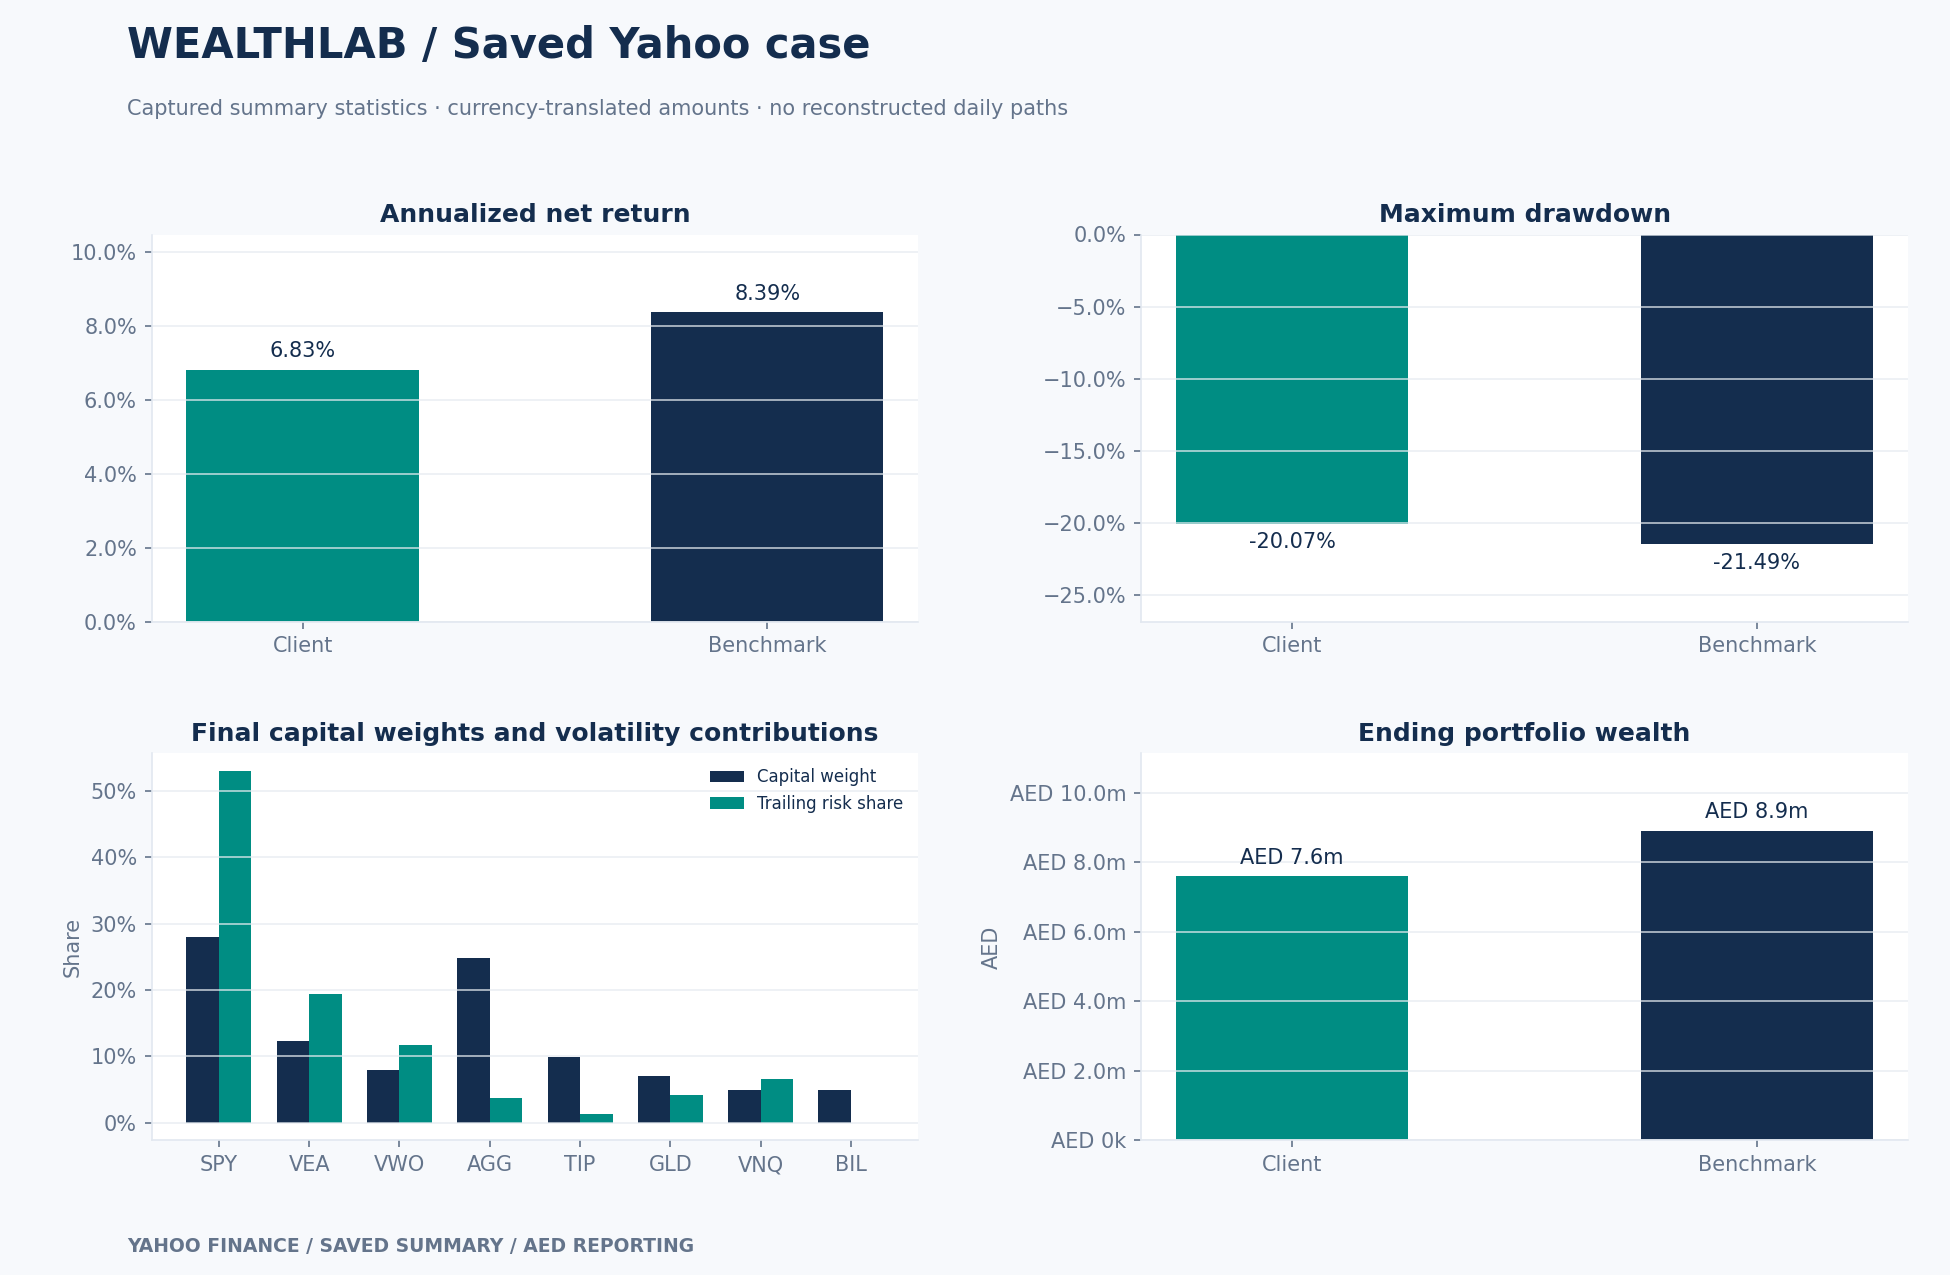

Diagnostics


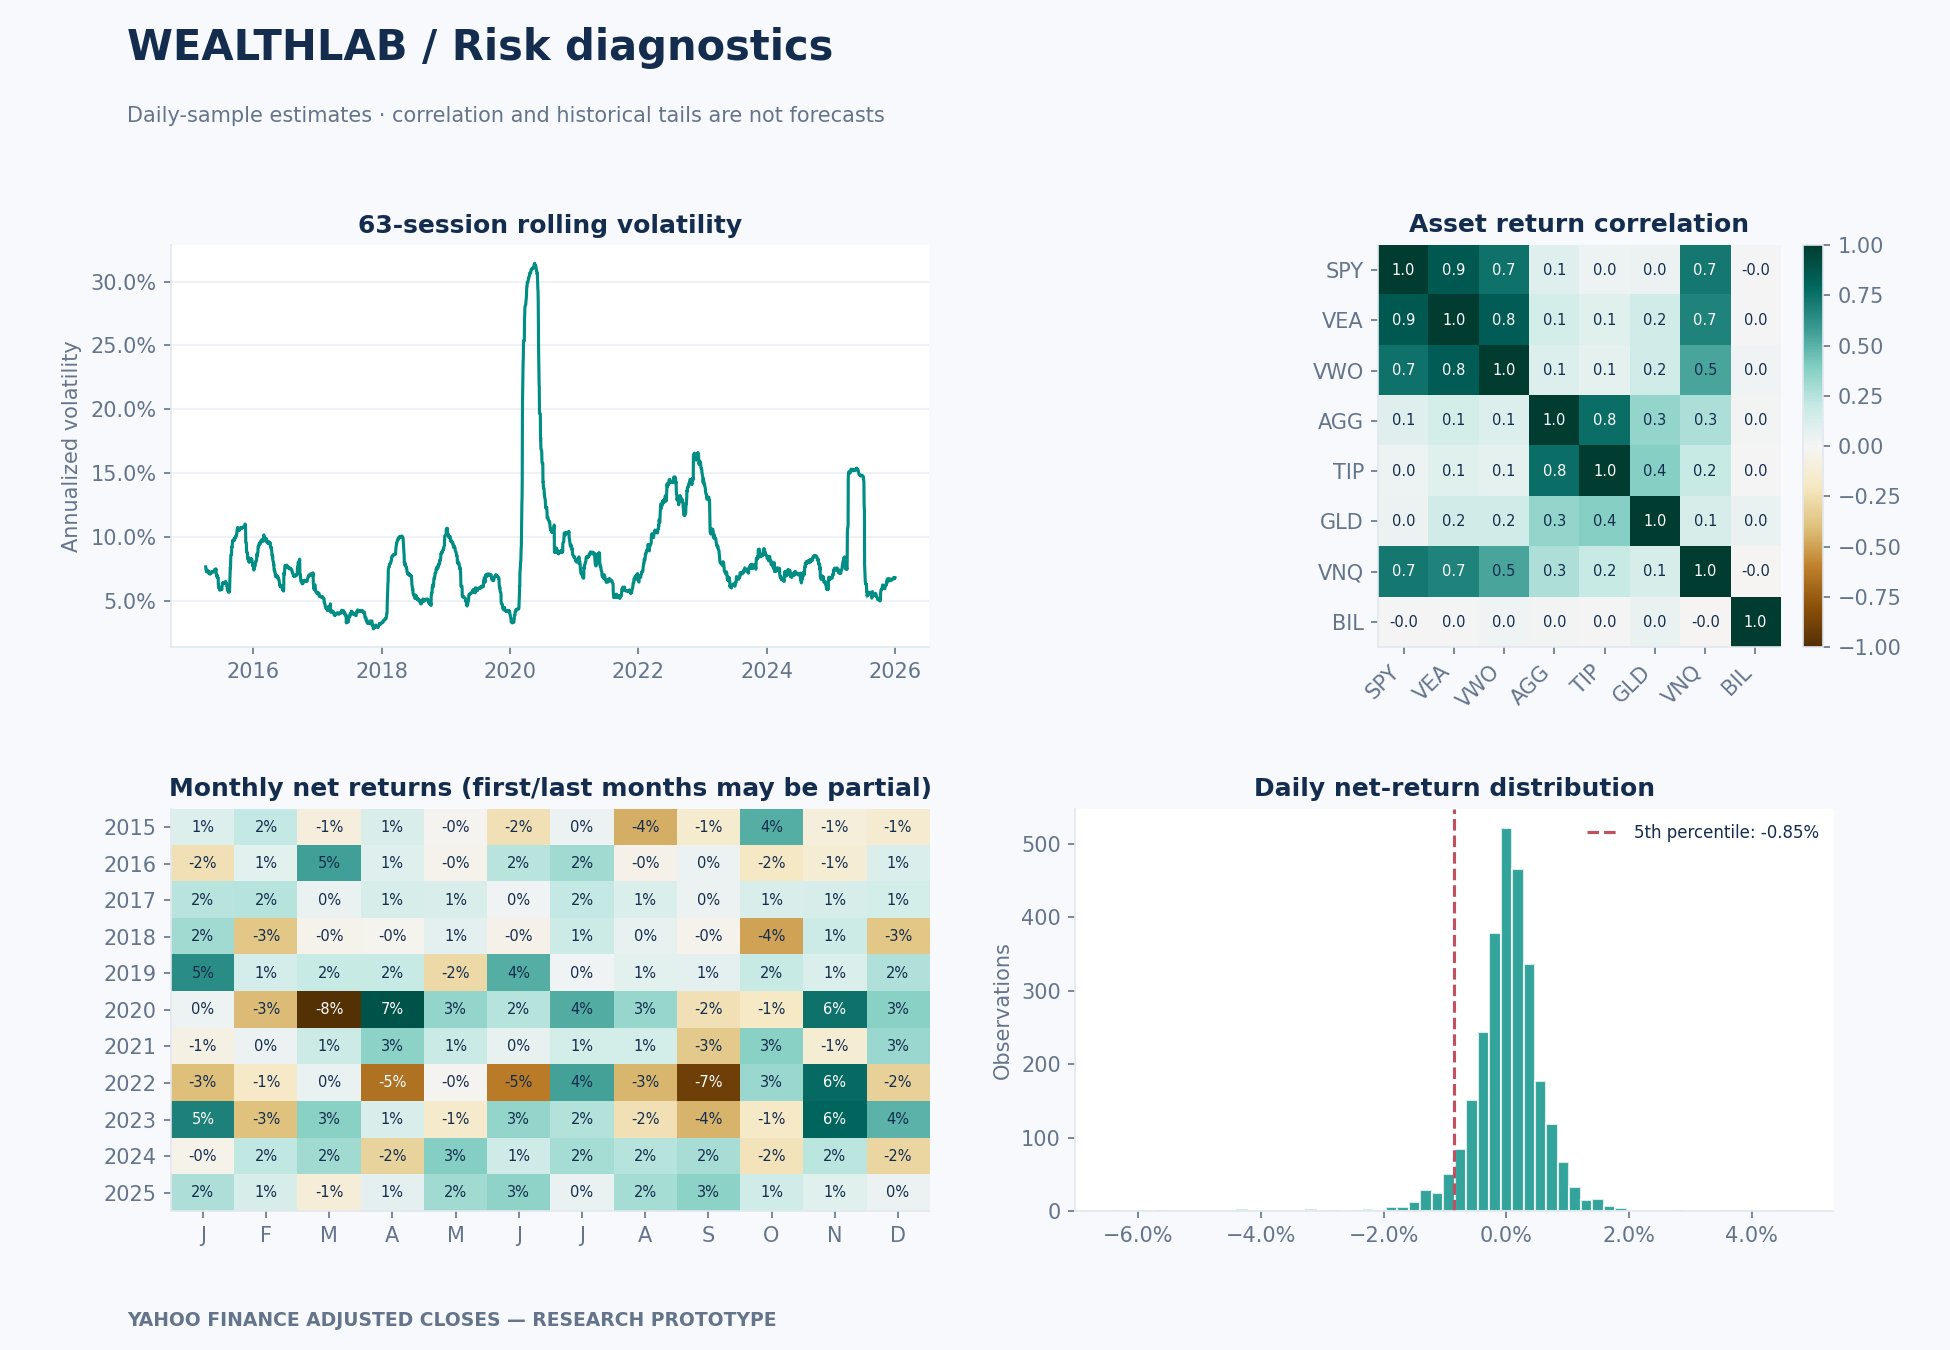

Attribution


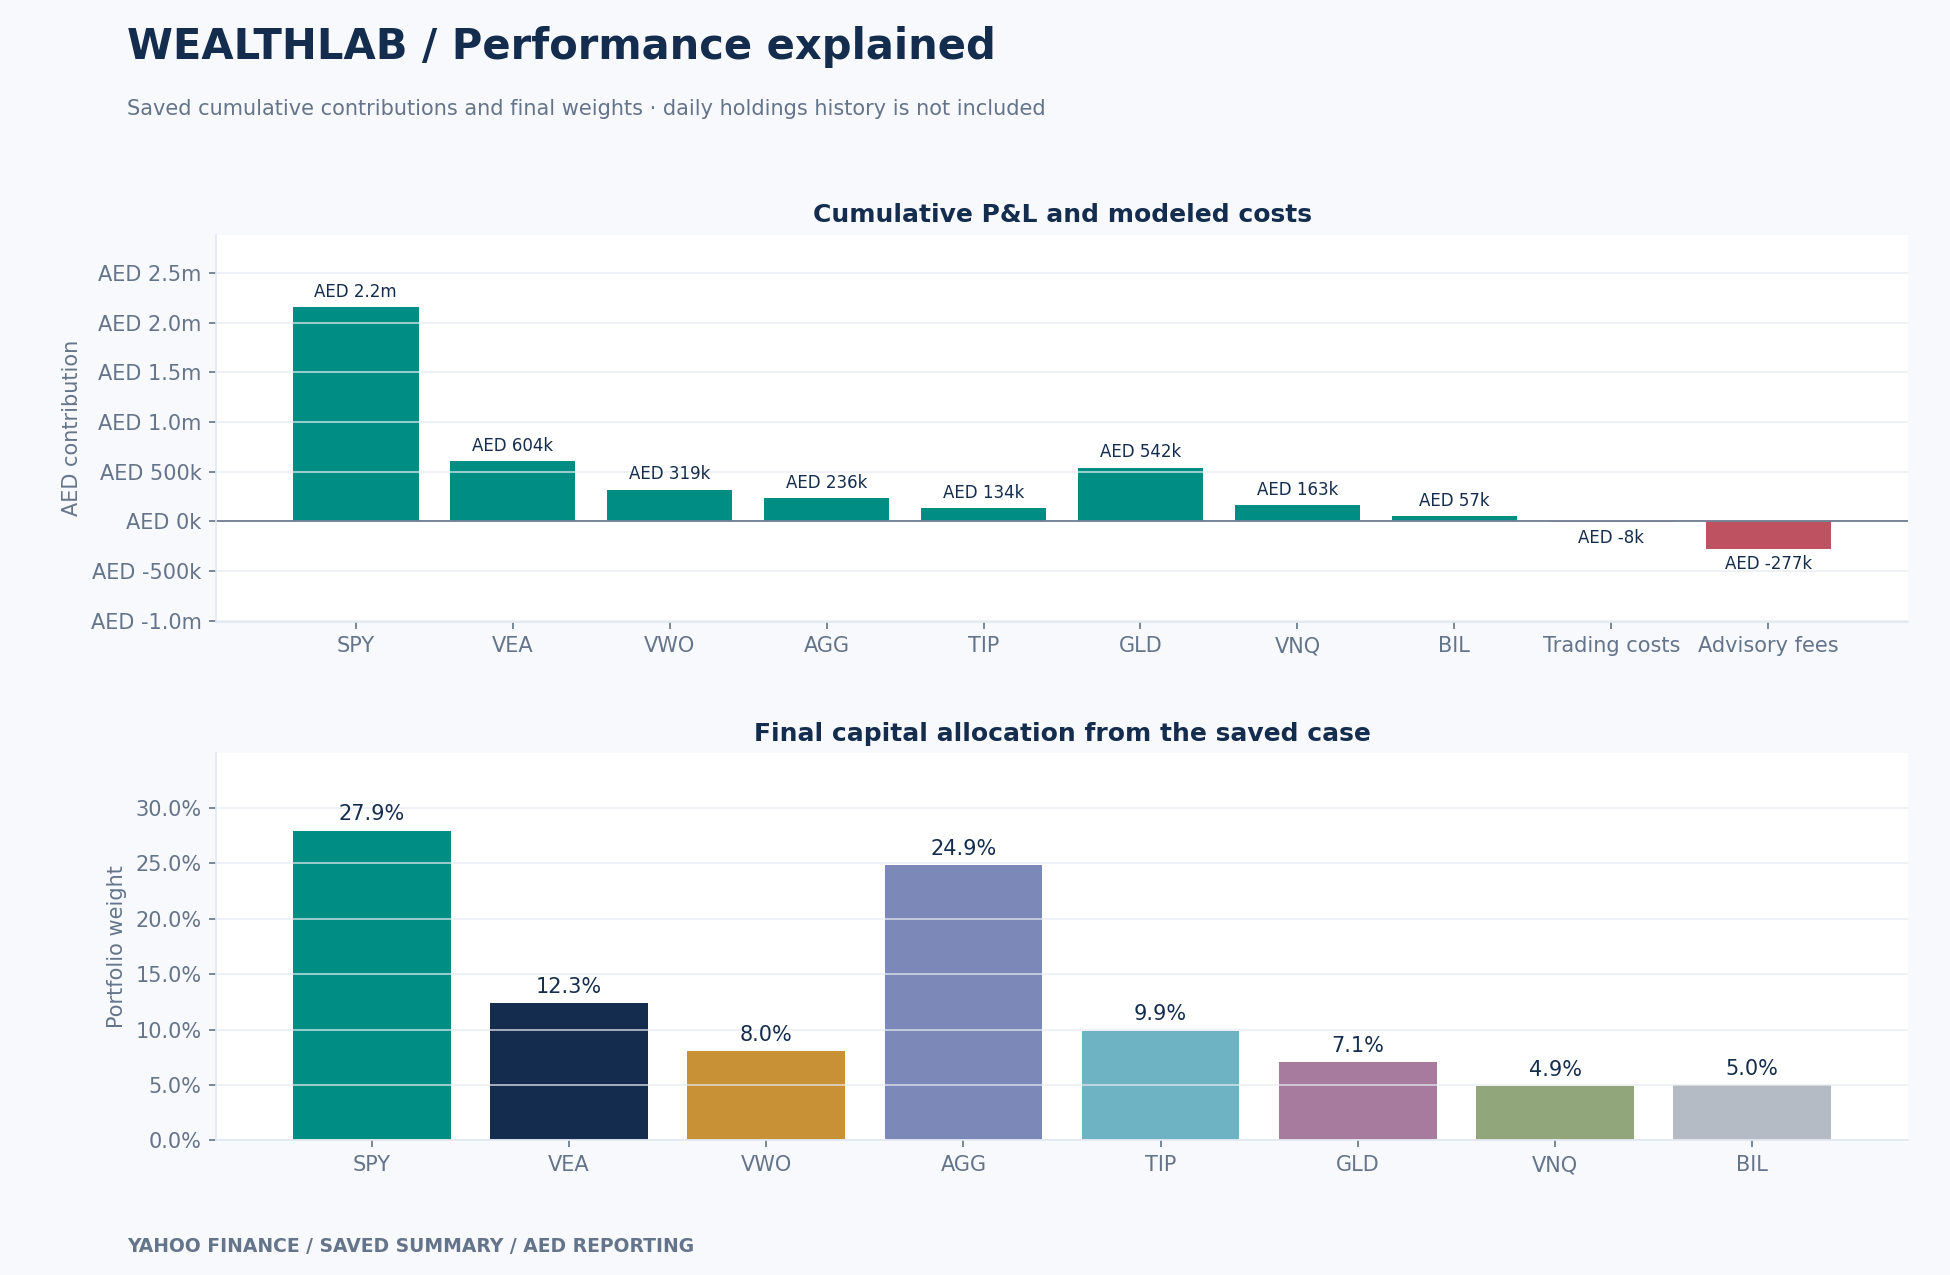

Planning


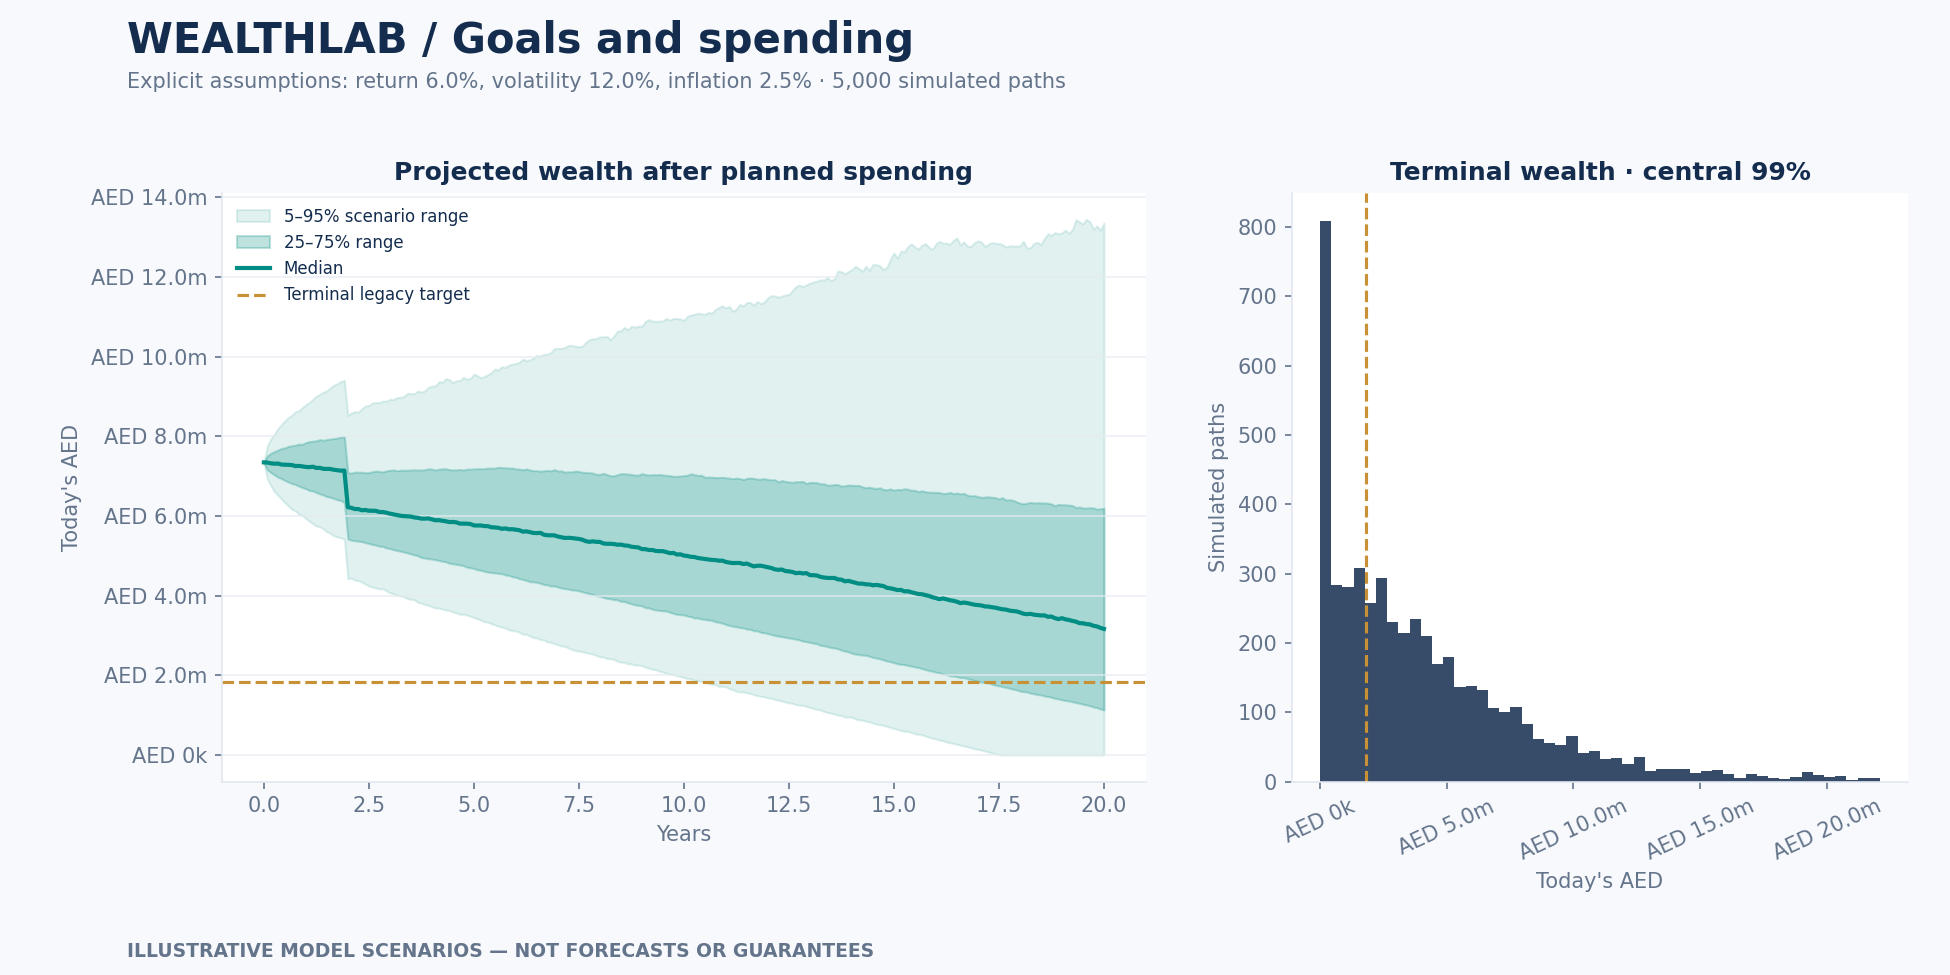

Scenarios


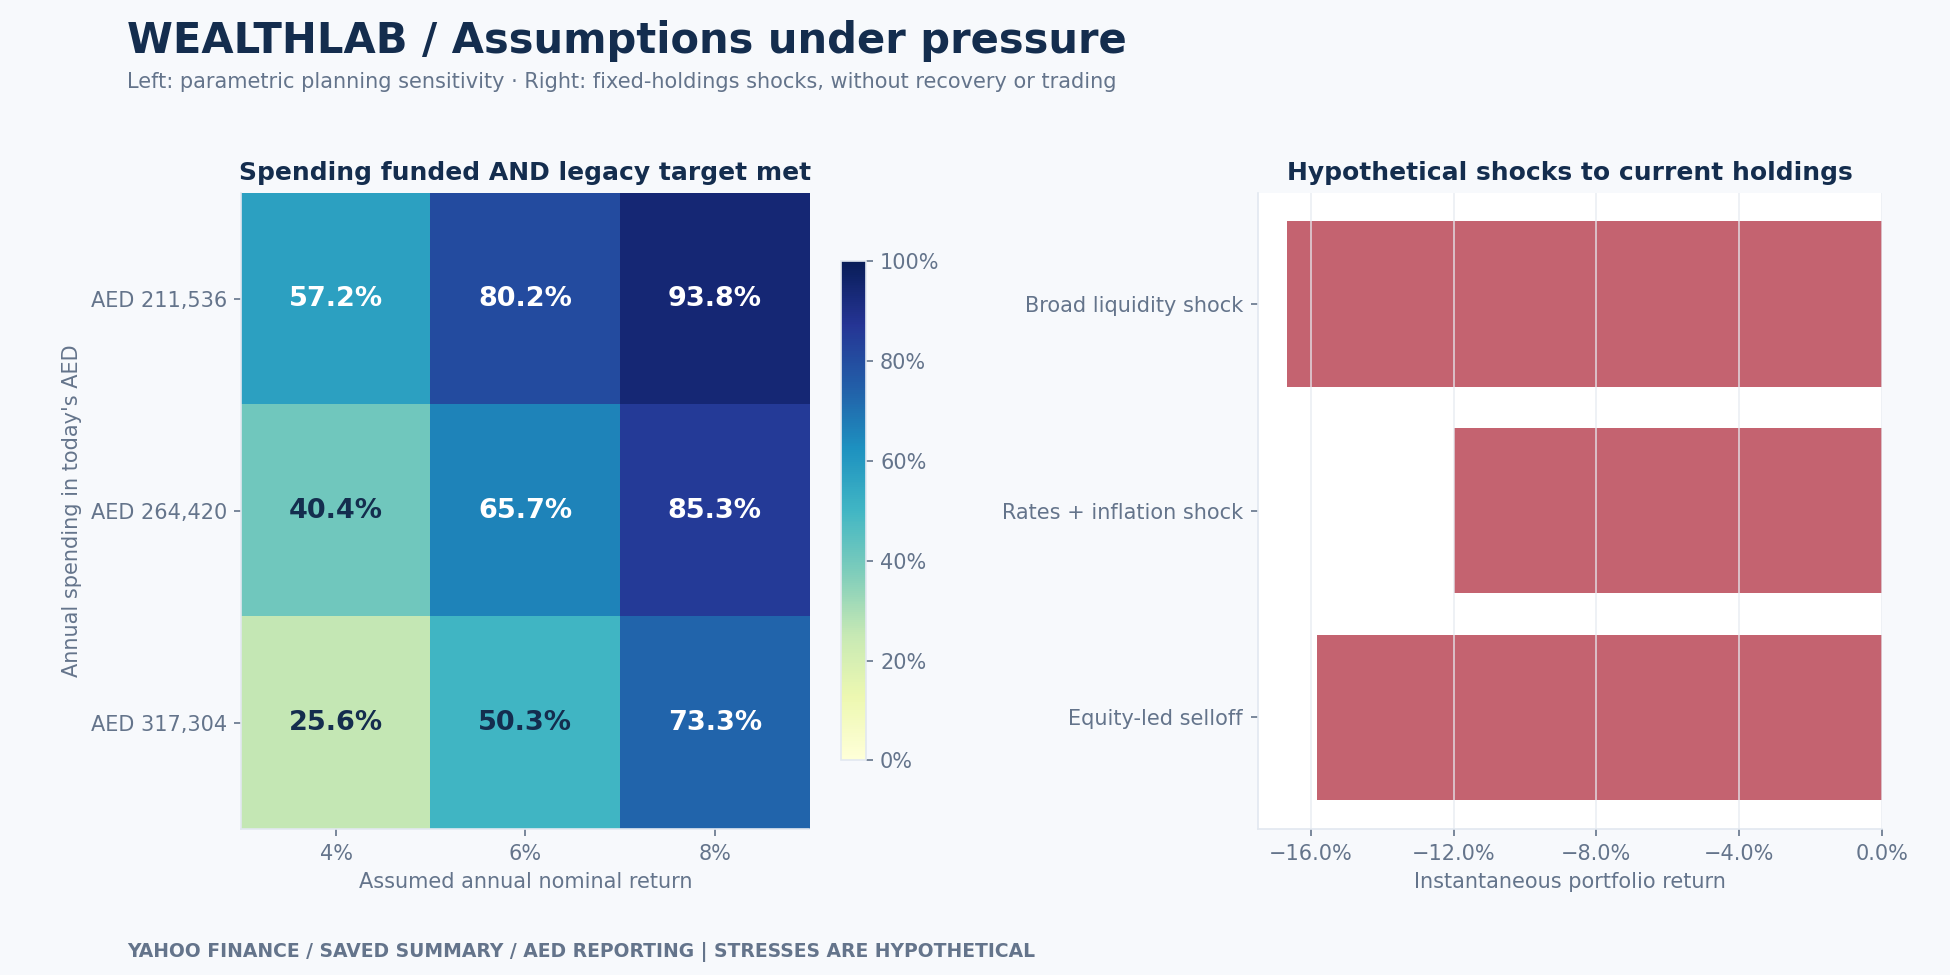

In [ ]:
# CELL 18 | Display charts
for label, chart_path in RUN.chart_paths.items():
    print(label.replace("_", " ").title())
    display(Image(filename=str(chart_path)))

## Cell 19 — Optional interactive planning sensitivity

Sliders rerun the planning model with a fixed seed. They are exploratory and do
not change the saved report. To persist a changed case, edit CLIENT in Cell 12
and rerun the analysis. The core project completes even without ipywidgets.

In [ ]:
# CELL 19 | Optional Colab controls
if importlib.util.find_spec("ipywidgets") is not None and not os.getenv("WEALTHLAB_SKIP_WIDGETS"):
    import ipywidgets as widgets
    import matplotlib.pyplot as plt
    from matplotlib.ticker import FuncFormatter
    def explore(expected_return=6.0, spending_thousands=CLIENT.annual_spending_today/1000):
        case = replace(CLIENT, expected_annual_return=expected_return/100,
                       annual_spending_today=spending_thousands*1000)
        result = simulate_client(case, CONFIG.advisory_fee_annual)
        print(f"Joint goal success: {result.success_probability:.1%}; "
              f"spending funded: {result.survival_probability:.1%}")
        fig, ax = plt.subplots(figsize=(10, 4))
        q = result.quantiles_real
        ax.fill_between(q.index, q.p05, q.p95, alpha=.15, color="#008d83")
        ax.plot(q.index, q.p50, color="#008d83", label="Median real wealth")
        ax.axhline(case.legacy_goal_today, color="#c89135", linestyle="--", label="Legacy goal")
        ax.set(xlabel="Years", ylabel=f"Today's {CLIENT.currency}", title="Illustrative planning sensitivity")
        ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{CLIENT.currency} {x/1e6:.1f}m"))
        ax.legend(); fig.tight_layout()
        display(fig)
        plt.close(fig)
    widgets.interact(explore,
        expected_return=widgets.FloatSlider(value=CLIENT.expected_annual_return*100,
                                           min=0, max=12, step=.5, description="Return %"),
        spending_thousands=widgets.FloatSlider(value=CLIENT.annual_spending_today/1000,
                                              min=CLIENT.annual_spending_today/1000*.25,
                                              max=CLIENT.annual_spending_today/1000*2.25,
                                              step=2, description=f"{CLIENT.currency} k/yr"))
else:
    print("Optional widgets unavailable or disabled. All saved outputs remain complete.")

## Cell 20 — Materialize documentation and financial tests

The embedded guide covers architecture, data conventions, equations, all metrics,
finance use cases, upgrade priorities, and resume wording. Offline tests challenge
the model using independent hand-calculated cases.

In [ ]:
# CELL 20 | Build documentation and tests
import json
supplemental = json.loads("{\"tests/test_accounting.py\": \"\\\"\\\"\\\"Hand-calculated cases that challenge the accounting, not just its syntax.\\\"\\\"\\\"\\n\\nimport unittest\\nimport numpy as np\\nimport pandas as pd\\n\\nfrom wealthlab.analytics import dollar_attribution, drawdown, performance_metrics, risk_contributions\\nfrom wealthlab.portfolio import run_backtest, self_financing_rebalance\\n\\n\\ndef frame(values, dates=None):\\n    return pd.DataFrame(values, index=pd.to_datetime(dates or [\\\"2024-01-02\\\", \\\"2024-01-03\\\", \\\"2024-01-04\\\"]),\\n                        columns=[\\\"A\\\", \\\"B\\\"])\\n\\n\\nclass AccountingTests(unittest.TestCase):\\n    def test_buy_hold_drifts_instead_of_daily_rebalancing(self):\\n        prices = frame([[100, 100], [110, 100], [100, 100]])\\n        run = run_backtest(prices, {\\\"A\\\": .5, \\\"B\\\": .5}, 1000, 0, 0, \\\"none\\\")\\n        np.testing.assert_allclose(run.history.nav, [1000, 1050, 1000])\\n        self.assertAlmostEqual(run.weights.iloc[1].A, 550/1050)\\n        self.assertAlmostEqual(run.returns.iloc[-1], -50/1050)\\n\\n    def test_month_boundary_executes_after_that_days_return(self):\\n        prices = frame([[100, 100], [110, 100], [110, 110]],\\n                       [\\\"2024-01-30\\\", \\\"2024-02-01\\\", \\\"2024-02-02\\\"])\\n        run = run_backtest(prices, {\\\"A\\\": .5, \\\"B\\\": .5}, 1000, 0, 0, \\\"monthly\\\")\\n        np.testing.assert_allclose(run.history.nav, [1000, 1050, 1102.5])\\n        np.testing.assert_allclose(run.weights.iloc[1], [.5, .5])\\n\\n    def test_initial_deployment_pays_cost_from_cash(self):\\n        h, cost, turnover = self_financing_rebalance(np.zeros(2), 1000, np.array([.6, .4]), .01)\\n        self.assertAlmostEqual(h.sum(), 1000/1.01)\\n        self.assertAlmostEqual(cost, 1000-h.sum())\\n        self.assertAlmostEqual(turnover, h.sum()/1000)\\n\\n    def test_cost_equation_holds_for_a_large_reallocation(self):\\n        holdings = np.array([900., 100.])\\n        target = np.array([.2, .8])\\n        h, cost, _ = self_financing_rebalance(holdings, 1000, target, .007)\\n        self.assertAlmostEqual(h.sum() + cost, 1000, places=9)\\n        self.assertAlmostEqual(cost, .007 * np.abs(h-holdings).sum(), places=9)\\n        np.testing.assert_allclose(h/h.sum(), target)\\n\\n    def test_advisory_fee_accrues_over_weekend(self):\\n        prices = frame([[100, 100], [100, 100]], [\\\"2024-01-05\\\", \\\"2024-01-08\\\"])\\n        run = run_backtest(prices, {\\\"A\\\": 1., \\\"B\\\": 0.}, 1000, 0, .01, \\\"none\\\")\\n        self.assertAlmostEqual(run.history.nav.iloc[-1], 1000 * .99 ** (3/365.25))\\n\\n    def test_attribution_reconciles_under_costs_and_rebalancing(self):\\n        dates = pd.bdate_range(\\\"2023-01-01\\\", periods=300)\\n        rng = np.random.default_rng(4)\\n        prices = pd.DataFrame(100*np.exp(np.cumsum(rng.normal(0, .01, (300,2)), axis=0)),\\n                              index=dates, columns=[\\\"A\\\", \\\"B\\\"])\\n        run = run_backtest(prices, {\\\"A\\\": .6, \\\"B\\\": .4}, 10000, 8, .009)\\n        self.assertAlmostEqual(dollar_attribution(run).sum(), run.history.nav.iloc[-1]-10000, places=7)\\n        self.assertAlmostEqual((1+run.returns).prod(), run.history.nav.iloc[-1]/10000, places=10)\\n        np.testing.assert_allclose(run.weights.sum(axis=1), 1)\\n\\n    def test_initial_cost_is_visible_in_drawdown(self):\\n        run = run_backtest(frame([[100,100], [100,100], [100,100]]), {\\\"A\\\": .5,\\\"B\\\": .5}, 1000, 10, 0)\\n        self.assertLess(drawdown(run).iloc[0], 0)\\n\\n    def test_prefix_results_do_not_change_when_future_data_added(self):\\n        dates = pd.bdate_range(\\\"2024-01-29\\\", periods=8)\\n        prices = pd.DataFrame({\\\"A\\\": np.arange(100,108), \\\"B\\\": np.arange(100,92,-1)}, index=dates)\\n        small = run_backtest(prices.iloc[:5], {\\\"A\\\": .5,\\\"B\\\": .5}, trading_cost_bps=5)\\n        large = run_backtest(prices, {\\\"A\\\": .5,\\\"B\\\": .5}, trading_cost_bps=5)\\n        pd.testing.assert_frame_equal(small.history, large.history.iloc[:5])\\n\\n    def test_zero_volatility_ratios_are_undefined(self):\\n        prices = frame([[100,100], [100,100], [100,100]])\\n        run = run_backtest(prices, {\\\"A\\\": .5,\\\"B\\\": .5}, 1000, 0, 0)\\n        metrics = performance_metrics(run, pd.Series(0., index=prices.index), run)\\n        self.assertTrue(np.isnan(metrics[\\\"Sharpe ratio\\\"]))\\n        self.assertTrue(np.isnan(metrics[\\\"Information ratio\\\"]))\\n\\n    def test_risk_components_sum_to_portfolio_volatility(self):\\n        returns = pd.DataFrame(np.random.default_rng(4).normal(0,.01,(300,2)), columns=[\\\"A\\\",\\\"B\\\"])\\n        rc = risk_contributions(returns, pd.Series({\\\"A\\\": .6,\\\"B\\\": .4}))\\n        self.assertAlmostEqual(rc.risk_share.sum(), 1)\\n\\n    def test_invalid_weights_or_prices_are_rejected(self):\\n        prices = frame([[100,100], [100,100], [100,100]])\\n        with self.assertRaises(ValueError):\\n            run_backtest(prices, {\\\"A\\\": .6,\\\"B\\\": .6})\\n        prices.iloc[1, 0] = np.nan\\n        with self.assertRaises(ValueError):\\n            run_backtest(prices, {\\\"A\\\": .5,\\\"B\\\": .5})\\n\\n\\nif __name__ == \\\"__main__\\\":\\n    unittest.main()\\n\", \"tests/test_currency.py\": \"\\\"\\\"\\\"Currency equivalence checks using the same returns, costs, and scenario shocks.\\\"\\\"\\\"\\n\\nfrom dataclasses import replace\\nimport tempfile\\nimport unittest\\n\\nimport numpy as np\\nimport pandas as pd\\n\\nfrom wealthlab.analytics import performance_metrics, pnl_attribution\\nfrom wealthlab.config import ClientConfig, ResearchConfig\\nfrom wealthlab.currency import AED_PER_USD, conversion_factor, format_money\\nfrom wealthlab.pipeline import run_project\\nfrom wealthlab.planning import simulate_client\\nfrom wealthlab.portfolio import run_backtest\\n\\n\\nclass CurrencyTests(unittest.TestCase):\\n    def test_fixed_translation_and_round_trip(self):\\n        self.assertEqual(1_000_000 * conversion_factor(\\\"USD\\\", \\\"AED\\\"), 3_672_500)\\n        self.assertEqual(72_000 * conversion_factor(\\\"USD\\\", \\\"AED\\\"), 264_420)\\n        self.assertAlmostEqual(conversion_factor(\\\"USD\\\", \\\"AED\\\") * conversion_factor(\\\"AED\\\", \\\"USD\\\"), 1)\\n        self.assertEqual(conversion_factor(\\\"AED\\\", \\\"AED\\\"), 1)\\n\\n    def test_default_case_preserves_original_purchasing_amounts(self):\\n        cfg, client = ResearchConfig(), ClientConfig()\\n        self.assertEqual(cfg.initial_capital, 1_000_000 * AED_PER_USD)\\n        self.assertEqual(client.current_wealth, 2_000_000 * AED_PER_USD)\\n        self.assertEqual(client.annual_spending_today, 72_000 * AED_PER_USD)\\n        self.assertEqual(client.legacy_goal_today, 500_000 * AED_PER_USD)\\n        self.assertEqual(client.one_off_spending[24], 250_000 * AED_PER_USD)\\n\\n    def test_backtest_scales_money_and_preserves_returns_and_weights(self):\\n        prices = pd.DataFrame({\\\"A\\\": [100, 110, 95, 105, 120], \\\"B\\\": [50, 49, 52, 55, 54]},\\n            index=pd.to_datetime([\\\"2024-01-30\\\", \\\"2024-01-31\\\", \\\"2024-02-01\\\", \\\"2024-03-01\\\", \\\"2024-04-01\\\"]))\\n        original_prices = prices.copy()\\n        usd = run_backtest(prices, {\\\"A\\\": .6, \\\"B\\\": .4}, initial_capital=10_000, currency=\\\"USD\\\")\\n        aed = run_backtest(prices, {\\\"A\\\": .6, \\\"B\\\": .4}, initial_capital=36_725, currency=\\\"AED\\\")\\n        monetary = [\\\"nav\\\", \\\"transaction_cost\\\", \\\"advisory_fee\\\"]\\n        np.testing.assert_allclose(aed.history[monetary], usd.history[monetary] * AED_PER_USD, rtol=1e-12)\\n        np.testing.assert_allclose(aed.asset_pnl, usd.asset_pnl * AED_PER_USD, rtol=1e-12, atol=1e-10)\\n        np.testing.assert_allclose(aed.returns, usd.returns, atol=1e-14)\\n        np.testing.assert_allclose(aed.weights, usd.weights, atol=1e-14)\\n        self.assertEqual(pnl_attribution(aed).name, \\\"profit_aed\\\")\\n        self.assertAlmostEqual(pnl_attribution(aed).sum(), aed.history.nav.iloc[-1] - 36_725, places=8)\\n        pd.testing.assert_frame_equal(prices, original_prices)\\n        rf = pd.Series(0., index=prices.index[1:])\\n        usd_metrics, aed_metrics = performance_metrics(usd, rf), performance_metrics(aed, rf)\\n        for name, value in usd_metrics.items():\\n            if name.endswith(\\\" USD\\\"):\\n                self.assertAlmostEqual(aed_metrics[name[:-3] + \\\"AED\\\"], value * AED_PER_USD, places=7)\\n            else:\\n                np.testing.assert_allclose(aed_metrics[name], value, rtol=1e-10, atol=1e-12)\\n        with self.assertRaises(ValueError):\\n            performance_metrics(aed, rf, benchmark=usd)\\n\\n    def test_planning_scales_wealth_without_changing_goal_frequencies(self):\\n        usd = ClientConfig(currency=\\\"USD\\\", current_wealth=120_000, annual_spending_today=5_000,\\n            legacy_goal_today=50_000, one_off_spending={12: 10_000}, horizon_years=2, paths=200)\\n        aed = replace(usd, currency=\\\"AED\\\", current_wealth=usd.current_wealth * AED_PER_USD,\\n            annual_spending_today=usd.annual_spending_today * AED_PER_USD,\\n            legacy_goal_today=usd.legacy_goal_today * AED_PER_USD,\\n            one_off_spending={12: 10_000 * AED_PER_USD})\\n        left, right = simulate_client(usd), simulate_client(aed)\\n        np.testing.assert_allclose(right.quantiles_real, left.quantiles_real * AED_PER_USD, rtol=1e-12)\\n        np.testing.assert_array_equal(right.funded_all_spending, left.funded_all_spending)\\n        self.assertEqual(right.success_probability, left.success_probability)\\n        self.assertEqual(right.survival_probability, left.survival_probability)\\n\\n    def test_mixed_currencies_rejected_before_data_access(self):\\n        with tempfile.TemporaryDirectory() as temp, self.assertRaises(ValueError):\\n            run_project(ResearchConfig(source=\\\"yahoo\\\"), ClientConfig(currency=\\\"USD\\\"), temp)\\n\\n    def test_unsupported_currency_rejected(self):\\n        for constructor in (ResearchConfig, ClientConfig):\\n            with self.assertRaises(ValueError):\\n                constructor(currency=\\\"MAD\\\")\\n\\n    def test_money_format_is_explicit_and_rejects_nonfinite_values(self):\\n        self.assertEqual(format_money(264420), \\\"AED 264,420\\\")\\n        self.assertEqual(format_money(-1000, \\\"AED\\\", 2), \\\"AED -1,000.00\\\")\\n        with self.assertRaises(ValueError):\\n            format_money(float(\\\"nan\\\"))\\n\\n\\nif __name__ == \\\"__main__\\\":\\n    unittest.main()\\n\", \"tests/test_data.py\": \"\\\"\\\"\\\"Deterministic pipeline and provider-contract checks without a network.\\\"\\\"\\\"\\n\\nfrom dataclasses import replace\\nfrom hashlib import sha256\\nfrom pathlib import Path\\nimport json\\nimport os\\nimport tempfile\\nimport types\\nimport unittest\\nfrom unittest.mock import patch\\n\\nimport numpy as np\\nimport pandas as pd\\n\\nfrom wealthlab.config import ResearchConfig\\nfrom wealthlab.data import (DataError, DataQualityError, clean_prices,\\n                           extract_yahoo_adjusted_close, load_prices, risk_free_returns)\\n\\n\\nclass DataTests(unittest.TestCase):\\n    def setUp(self):\\n        self.cfg = ResearchConfig(start=\\\"2024-01-01\\\", end=\\\"2024-01-06\\\", min_observations=3,\\n                                   weights={\\\"SPY\\\": .6,\\\"AGG\\\": .4}, benchmark={\\\"SPY\\\": .6,\\\"AGG\\\": .4})\\n        self.frame = pd.DataFrame({\\\"SPY\\\": [100,101,102,103,104], \\\"AGG\\\": [100,100,101,101,102]},\\n                                  index=pd.bdate_range(\\\"2024-01-01\\\", periods=5)).astype(float)\\n\\n    def test_demo_cache_roundtrip_is_exact(self):\\n        with tempfile.TemporaryDirectory() as temp:\\n            first = load_prices(self.cfg, temp)\\n            second = load_prices(self.cfg, temp)\\n            pd.testing.assert_frame_equal(first.prices, second.prices)\\n            self.assertFalse(first.manifest[\\\"cache_hit\\\"])\\n            self.assertTrue(second.manifest[\\\"cache_hit\\\"])\\n            self.assertTrue(second.manifest[\\\"synthetic\\\"])\\n\\n    def test_cache_tampering_is_rejected(self):\\n        with tempfile.TemporaryDirectory() as temp:\\n            load_prices(self.cfg, temp)\\n            next(Path(temp).glob(\\\"*.csv\\\")).write_text(\\\"tampered\\\")\\n            with self.assertRaises(DataError):\\n                load_prices(self.cfg, temp)\\n\\n    def test_source_names_do_not_share_cache(self):\\n        raw = pd.concat({\\\"Adj Close\\\": self.frame}, axis=1)\\n        fake_yf = types.SimpleNamespace(__version__=\\\"mock\\\", download=lambda *a,**k: raw)\\n        with tempfile.TemporaryDirectory() as temp, patch.dict(\\\"sys.modules\\\", {\\\"yfinance\\\": fake_yf}):\\n            load_prices(self.cfg, temp)\\n            live = load_prices(replace(self.cfg, source=\\\"yahoo\\\"), temp)\\n            self.assertEqual(len(list(Path(temp).glob(\\\"*.csv\\\"))), 2)\\n            self.assertFalse(live.manifest[\\\"synthetic\\\"])\\n\\n    def test_provider_failure_never_silently_returns_demo(self):\\n        raw = pd.DataFrame()\\n        fake_yf = types.SimpleNamespace(__version__=\\\"mock\\\", download=lambda *a,**k: raw)\\n        with tempfile.TemporaryDirectory() as temp, patch.dict(\\\"sys.modules\\\", {\\\"yfinance\\\": fake_yf}), \\\\\\n                patch(\\\"wealthlab.data.time.sleep\\\"):\\n            with self.assertRaises(DataError):\\n                load_prices(replace(self.cfg, source=\\\"yahoo\\\"), temp)\\n            self.assertEqual(list(Path(temp).glob(\\\"*.csv\\\")), [])\\n\\n    def test_yahoo_multiindex_field_first(self):\\n        raw = pd.concat({\\\"Adj Close\\\": self.frame, \\\"Close\\\": self.frame*2}, axis=1)\\n        selected = extract_yahoo_adjusted_close(raw, [\\\"SPY\\\",\\\"AGG\\\"])\\n        np.testing.assert_allclose(selected, self.frame)\\n\\n    def test_yahoo_multiindex_ticker_first(self):\\n        raw = pd.concat({\\\"Adj Close\\\": self.frame}, axis=1).swaplevel(axis=1)\\n        selected = extract_yahoo_adjusted_close(raw, [\\\"SPY\\\",\\\"AGG\\\"])\\n        np.testing.assert_allclose(selected, self.frame)\\n\\n    def test_unadjusted_prices_are_not_substituted(self):\\n        with self.assertRaises(DataError):\\n            extract_yahoo_adjusted_close(pd.DataFrame({\\\"Close\\\": [100]}), [\\\"SPY\\\"])\\n\\n    def test_interior_missing_is_rejected_not_filled(self):\\n        self.frame.iloc[2,0] = np.nan\\n        with self.assertRaises(DataQualityError):\\n            clean_prices(self.frame, self.cfg)\\n\\n    def test_identical_duplicates_are_removed(self):\\n        duplicate = pd.concat([self.frame, self.frame.iloc[[0]]])\\n        cleaned, quality = clean_prices(duplicate, self.cfg)\\n        self.assertEqual(len(cleaned), 5)\\n        self.assertEqual(quality[\\\"identical_duplicates_removed\\\"], 1)\\n\\n    def test_conflicting_duplicates_are_rejected(self):\\n        duplicate = self.frame.iloc[[0]].copy()\\n        duplicate.iloc[0,0] = 999\\n        with self.assertRaises(DataQualityError):\\n            clean_prices(pd.concat([self.frame, duplicate]), self.cfg)\\n\\n    def test_nonpositive_and_infinite_prices_are_rejected(self):\\n        for value in [0, -1, np.inf]:\\n            changed = self.frame.copy()\\n            changed.iloc[1,0] = value\\n            with self.assertRaises(DataQualityError):\\n                clean_prices(changed, self.cfg)\\n\\n    def test_late_inception_requires_explicit_start_change(self):\\n        cfg = replace(self.cfg, start=\\\"2023-01-01\\\")\\n        with self.assertRaises(DataQualityError):\\n            clean_prices(self.frame, cfg)\\n\\n    def test_risk_free_uses_calendar_days(self):\\n        dates = pd.to_datetime([\\\"2024-01-05\\\", \\\"2024-01-08\\\"])\\n        rf, _ = risk_free_returns(dates, replace(self.cfg, annual_risk_free_rate=.05), \\\".\\\")\\n        self.assertEqual(rf.iloc[0], 0)\\n        self.assertAlmostEqual(rf.iloc[1], 1.05**(3/365.25)-1)\\n\\n    def test_fred_missing_key_fails_explicitly(self):\\n        with tempfile.TemporaryDirectory() as temp, patch.dict(os.environ, {}, clear=True):\\n            with self.assertRaisesRegex(DataError, \\\"FRED_API_KEY\\\"):\\n                risk_free_returns(self.frame.index, replace(self.cfg, risk_free_source=\\\"fred\\\"), temp)\\n\\n    def test_fred_cached_yield_is_lagged(self):\\n        dates = pd.to_datetime([\\\"2024-01-02\\\", \\\"2024-01-03\\\", \\\"2024-01-04\\\"])\\n        start = (dates[0] - pd.Timedelta(days=14)).date().isoformat()\\n        end = dates[-1].date().isoformat()\\n        key = sha256(f\\\"fred-DGS3MO-{start}-{end}-v1\\\".encode()).hexdigest()[:20]\\n        payload = {\\\"observations\\\": [{\\\"date\\\": \\\"2024-01-01\\\", \\\"value\\\": \\\"2\\\"},\\n                                    {\\\"date\\\": \\\"2024-01-02\\\", \\\"value\\\": \\\"4\\\"},\\n                                    {\\\"date\\\": \\\"2024-01-03\\\", \\\"value\\\": \\\"8\\\"}]}\\n        with tempfile.TemporaryDirectory() as temp:\\n            stored = {\\\"payload\\\": payload, \\\"retrieved_at_utc\\\": \\\"fixture\\\",\\n                      \\\"sha256\\\": sha256(json.dumps(payload, sort_keys=True).encode()).hexdigest()}\\n            (Path(temp)/f\\\"fred-{key}.json\\\").write_text(json.dumps(stored))\\n            rf, _ = risk_free_returns(dates, replace(self.cfg, risk_free_source=\\\"fred\\\"), temp)\\n            self.assertAlmostEqual(rf.iloc[1], 1.04**(1/365.25)-1)\\n            self.assertAlmostEqual(rf.iloc[2], 1.08**(1/365.25)-1)\\n\\n\\nif __name__ == \\\"__main__\\\":\\n    unittest.main()\\n\", \"tests/test_findings.py\": \"\\\"\\\"\\\"Check that report wording follows the supplied data and escapes HTML.\\\"\\\"\\\"\\n\\nfrom dataclasses import replace\\nimport unittest\\n\\nimport pandas as pd\\n\\nfrom wealthlab.config import ResearchConfig, ClientConfig\\nfrom wealthlab.findings import build_findings, findings_to_html\\nfrom wealthlab.planning import simulate_client\\n\\n\\nclass FindingsTests(unittest.TestCase):\\n    def test_renderer_escapes_untrusted_text(self):\\n        html = findings_to_html('## Results\\\\n\\\\n<script>alert(1)</script>\\\\n\\\\n**Safe** text.')\\n        self.assertNotIn('<script>', html)\\n        self.assertIn('&lt;script&gt;', html)\\n        self.assertIn('<strong>Safe</strong>', html)\\n\\n    def test_generated_source_label_and_comparison_follow_inputs(self):\\n        cfg = ResearchConfig()\\n        client = ClientConfig(horizon_years=1, paths=100, one_off_spending={})\\n        m = pd.DataFrame({'Client portfolio': {'CAGR': .08, 'Total return': .1,\\n            'Annualized volatility': .09, 'Maximum drawdown': -.2, 'Sharpe ratio': .5,\\n            'Ending NAV AED': 1100000, 'Advisory fees AED': 1000, 'Transaction costs AED': 100},\\n            'Strategic benchmark': {'CAGR': .05, 'Total return': .08,\\n            'Annualized volatility': .1, 'Maximum drawdown': -.22, 'Sharpe ratio': .3,\\n            'Ending NAV AED': 1080000}})\\n        risk = pd.DataFrame({'capital_weight': [.3,.4], 'risk_share': [.6,.1]}, index=['SPY','AGG'])\\n        pnl = pd.Series({'SPY': 100000., 'AGG': 1100., 'Trading costs': -100., 'Advisory fees': -1000.})\\n        stress = pd.DataFrame({'portfolio_return': [-.1]}, index=['Test shock'])\\n        projection = simulate_client(client)\\n        sensitivity = pd.DataFrame([[.4,.6,.8]], index=[client.annual_spending_today], columns=[.04,.06,.08])\\n        quality = {'first_observation': '2015-01-02', 'last_observation': '2025-12-31', 'retained_rows': 2766}\\n        arguments = (client,m,risk,pnl,stress,projection,sensitivity,quality)\\n        demo = build_findings(cfg,*arguments)\\n        yahoo = build_findings(replace(cfg,source='yahoo'),*arguments)\\n        self.assertIn('synthetic demonstration',demo)\\n        self.assertIn('real Yahoo Finance prices',yahoo)\\n        self.assertNotIn('synthetic demonstration',yahoo)\\n        self.assertIn('earned a higher annualized return',yahoo)\\n        self.assertIn('8.00%',yahoo)\\n\", \"tests/test_integration.py\": \"\\\"\\\"\\\"Exercise the exported run contract using a short synthetic mandate.\\\"\\\"\\\"\\n\\nimport json\\nfrom pathlib import Path\\nimport tempfile\\nimport unittest\\n\\nfrom wealthlab.config import ClientConfig, ResearchConfig\\nfrom wealthlab.pipeline import run_project\\n\\n\\nclass IntegrationTests(unittest.TestCase):\\n    def test_end_to_end_outputs_and_escaped_client_label(self):\\n        cfg = ResearchConfig(start=\\\"2023-01-01\\\", end=\\\"2024-02-01\\\")\\n        client = ClientConfig(label=\\\"Family <script>alert(1)</script>\\\", horizon_years=1,\\n                              paths=100, one_off_spending={})\\n        with tempfile.TemporaryDirectory() as temp:\\n            result = run_project(cfg, client, temp)\\n            html = result.report_path.read_text()\\n            self.assertIn(\\\"SYNTHETIC DEMO\\\", html)\\n            self.assertIn(\\\"&lt;script&gt;\\\", html)\\n            self.assertNotIn(\\\"<script>alert\\\", html)\\n            self.assertNotIn('src=\\\"https://', html)\\n            self.assertEqual(len(result.chart_paths), 5)\\n            self.assertTrue(all(p.read_bytes().startswith(b\\\"\\\\x89PNG\\\") for p in result.chart_paths.values()))\\n            manifest = json.loads((result.output_dir / \\\"run_manifest.json\\\").read_text())\\n            self.assertLess(abs(manifest[\\\"validation\\\"][\\\"attribution_residual_aed\\\"]), 1e-6)\\n            self.assertEqual(manifest[\\\"currency\\\"][\\\"reporting_currency\\\"], \\\"AED\\\")\\n            self.assertIn(\\\"Ending NAV AED\\\", result.metrics.index)\\n            self.assertIn(\\\"AED 264,420\\\", html)\\n            self.assertNotIn(\\\"Ending NAV USD\\\", html)\\n            self.assertIn(\\\"source_code_sha256\\\", manifest)\\n            self.assertEqual(len(list(Path(result.output_dir).glob(\\\"*.csv\\\"))), 12)\\n\\n\\nif __name__ == \\\"__main__\\\":\\n    unittest.main()\\n\", \"tests/test_planning.py\": \"\\\"\\\"\\\"Planning boundary cases and deterministic analytical comparisons.\\\"\\\"\\\"\\n\\nfrom dataclasses import replace\\nimport unittest\\nimport numpy as np\\n\\nfrom wealthlab.config import ClientConfig\\nfrom wealthlab.planning import simulate_client, planning_sensitivity\\n\\n\\nclass PlanningTests(unittest.TestCase):\\n    def setUp(self):\\n        self.client = ClientConfig(current_wealth=1000, annual_spending_today=120,\\n                                   horizon_years=1, inflation=0, expected_annual_return=0,\\n                                   annual_volatility=0, legacy_goal_today=0, paths=100,\\n                                   one_off_spending={})\\n\\n    def test_zero_return_cashflow_has_exact_solution(self):\\n        result = simulate_client(self.client, 0)\\n        np.testing.assert_allclose(result.terminal_real, 880)\\n        self.assertEqual(result.survival_probability, 1)\\n\\n    def test_zero_volatility_growth_matches_expected_annual_return(self):\\n        client = replace(self.client, annual_spending_today=0, expected_annual_return=.06)\\n        result = simulate_client(client, 0)\\n        np.testing.assert_allclose(result.terminal_real, 1060)\\n\\n    def test_fee_compounds_once_over_a_year(self):\\n        client = replace(self.client, annual_spending_today=0)\\n        np.testing.assert_allclose(simulate_client(client, .01).terminal_real, 990)\\n\\n    def test_depletion_is_absorbing(self):\\n        client = replace(self.client, annual_spending_today=2400)\\n        result = simulate_client(client, 0)\\n        np.testing.assert_allclose(result.terminal_real, 0)\\n        self.assertEqual(result.survival_probability, 0)\\n        self.assertEqual(result.success_probability, 0)\\n\\n    def test_legacy_goal_changes_joint_success_not_spending_funding(self):\\n        result = simulate_client(replace(self.client, legacy_goal_today=900), 0)\\n        self.assertEqual(result.survival_probability, 1)\\n        self.assertEqual(result.success_probability, 0)\\n\\n    def test_one_off_spending_is_applied_once(self):\\n        client = replace(self.client, one_off_spending={6: 100})\\n        np.testing.assert_allclose(simulate_client(client, 0).terminal_real, 780)\\n\\n    def test_real_wealth_deflates_nominal_balance(self):\\n        client = replace(self.client, annual_spending_today=0, inflation=.05)\\n        np.testing.assert_allclose(simulate_client(client, 0).terminal_real, 1000/1.05)\\n\\n    def test_random_seed_is_reproducible(self):\\n        client = replace(self.client, annual_volatility=.2)\\n        a, b = simulate_client(client), simulate_client(client)\\n        np.testing.assert_array_equal(a.terminal_real, b.terminal_real)\\n\\n    def test_more_spending_does_not_improve_success_with_common_shocks(self):\\n        table = planning_sensitivity(replace(self.client, legacy_goal_today=850, annual_volatility=.2), 0)\\n        self.assertTrue((table.diff().iloc[1:].to_numpy() <= 0).all())\\n\\n    def test_invalid_shocks_rejected(self):\\n        with self.assertRaises(ValueError):\\n            simulate_client(self.client, shocks=np.zeros((2,2)))\\n\\n    def test_invalid_inputs_rejected(self):\\n        for fields in [{\\\"current_wealth\\\": -1}, {\\\"annual_spending_today\\\": -1}, {\\\"paths\\\": 0},\\n                       {\\\"inflation\\\": float(\\\"nan\\\")}, {\\\"one_off_spending\\\": {0: 100}}]:\\n            with self.assertRaises(ValueError):\\n                replace(self.client, **fields)\\n\\n\\nif __name__ == \\\"__main__\\\":\\n    unittest.main()\\n\", \"docs/PROJECT_GUIDE.md\": \"# WealthLab \u2014 Complete project and build guide\\n\\n## 1. Project overview\\n\\n**Project:** Multi-Asset Portfolio Analytics & Client Wealth Planning.\\n\\n**Audience:** A finance student or junior analyst targeting private banking,\\nwealth management, investment advisory, or portfolio analytics.\\n\\n**Question:** How did a diversified portfolio perform, which holdings drove\\nits outcome and risk, and how sensitive is a fictional family's spending plan\\nto investment assumptions?\\n\\n**Difficulty:** Intermediate Python foundations through advanced portfolio accounting.\\nThe engine is a well-documented research prototype. Production deployment would\\nrequire a larger data-control, security, operational, and governance framework.\\n\\nThe project has two deliberately separate analytical tracks:\\n\\n1. Historical portfolio accounting, without client deposits or withdrawals.\\n2. Prospective, assumption-driven client spending scenarios.\\n\\nHistorical results do not automatically become forward return assumptions.\\nThe finalized historical case uses real Yahoo Finance adjusted prices from the\\nsupplied, successfully executed Colab notebook. Its portfolio returns are a\\nhypothetical backtest. Forward client planning and stresses remain simulations.\\nThe recorded summaries are translated to AED, monetary charts are redrawn\\nfrom those summaries, and the original dimensionless diagnostics panel is\\npreserved. The raw daily-price cache was not attached. Re-run the notebook to create a fresh full-data export.\\n\\n## 2. Real-world finance use case\\n\\nA private-bank analyst prepares a portfolio review for a fictional family.\\nThe family has AED 7,345,000 of investable wealth, annual real spending of\\nAED 264,420, an additional AED 918,125 goal in month 24, and a desired real\\nlegacy of AED 1,836,250 after 20 years. These are case assumptions, not facts\\nabout the user.\\n\\nThe analyst needs to explain diversification, concentration, interest-sensitive\\nassets, losses under stress, fees, and the sensitivity of the plan. A relationship\\nmanager could use similar analysis as an input to a discussion with investment,\\nlending, and planning specialists. This software does not replace those roles\\nor determine what is suitable for an actual person.\\n\\nThe quantitative contribution is transparent accounting and useful decision\\nsupport: different capital weights can create very different risk exposures;\\nsmall changes in spending or return assumptions can materially change outcomes.\\n\\nAll case amounts are UAE dirhams (AED), translated from the original USD\\ncase at 1 USD = AED 3.6725. Yahoo ETF price observations remain USD source\\nquotes. Price relatives drive AED-denominated accounts under a constant-rate\\nassumption; percentages do not change. FX spreads, conversion charges, and\\nchanges in the peg are not modeled. See [currency conventions](CURRENCY.md).\\n\\n## 3. System architecture\\n\\n```mermaid\\nflowchart TD\\n    A[Research configuration] --> B[Synthetic or Yahoo prices]\\n    B --> C[Checksummed cache and validation]\\n    C --> D[Drifting holdings and rebalance engine]\\n    D --> E[Performance, attribution, and risk]\\n    F[Client assumptions] --> G[Monthly cash-flow scenarios]\\n    E --> H[Embedded report and audit bundle]\\n    G --> H\\n```\\n\\nAn optional FRED input supplies a lagged yield proxy for excess-return metrics.\\nIt is not a portfolio holding and is not used to add a second return to BIL.\\n\\nThe Colab notebook embeds every source module in clearly numbered build cells.\\nRunning these cells recreates the same package structure used locally and on\\nGitHub. Analysis calls then use normal imports rather than a monolithic script.\\n\\n## 4. APIs and sources\\n\\n| Input | Default | Optional live route | Important convention |\\n|---|---|---|---|\\n| Asset price history | Yahoo through yfinance | Explicit synthetic mode for offline tests | Adjusted close; end date exclusive |\\n| Corporate-action adjustment | Yahoo adjusted prices | Embedded in synthetic test indices | Do not add dividends to adjusted returns again |\\n| Risk-free comparison | Explicit 2.5% annual assumption | FRED DGS3MO with personal API key | One-day minimum lag, 7-day maximum stale age; yield approximation |\\n| Portfolio mandate | User configuration | Same | Fixed before the historical calculation |\\n| Client goals | Fictional configuration | Same | Amounts are AED; real-value goals share a t=0 basis |\\n| API credentials | None needed | Environment or Colab Secrets | Never stored in notebooks, manifests, or Git |\\n\\nSEC EDGAR, FMP, Alpha Vantage, and paid tick feeds are unnecessary for this\\nETF-level project. A licensed daily-price provider can replace Yahoo later by\\nreturning the same wide adjusted-price DataFrame and provenance metadata.\\n\\nYahoo's Python wrapper is unofficial and its project warns about personal-use\\ndata terms. FRED requires each user to use their own API key. These interfaces\\nare conveniences for research, not guaranteed institutional data services.\\n\\n## 5. Libraries and runtime\\n\\n| Library | Role | Needed for offline demo? |\\n|---|---|---|\\n| numpy | Arrays, scenario simulation, vectorized holdings math | Yes |\\n| pandas | Dated data, alignment, returns, tables | Yes |\\n| scipy | Available for quantitative extensions; current core equations use NumPy | Installed core research dependency |\\n| matplotlib | Professional saved figures | Yes |\\n| yfinance | Yahoo adapter | No |\\n| requests | Optional FRED adapter, HTTP retries and timeouts | No |\\n| ipywidgets | Optional Colab sensitivity controls | No |\\n| unittest | Financial validation tests | Python standard library |\\n| json, hashlib, pathlib, logging | Configuration, provenance, filesystem and diagnostics | Python standard library |\\n\\nPython 3.10+ is supported by the code's syntax. The artifact's actual exercised\\nenvironment is recorded in `requirements-tested.txt` and the example manifest.\\nThe core demo does not need a GPU. Optional widgets are detected; their absence\\ndoes not prevent notebook completion.\\n\\n## 6. Folder and file structure\\n\\n| File or directory | Responsibility |\\n|---|---|\\n| `WealthLab_Colab.ipynb` | Single upload, all source code, analysis, figures, export |\\n| `wealthlab/currency.py` | Reporting units, fixed USD/AED convention, formatting, and FX provenance |\\n| `wealthlab/config.py` | ResearchConfig and ClientConfig input contracts |\\n| `wealthlab/data.py` | Source adapters, atomic caching, adjusted-close extraction, quality checks |\\n| `wealthlab/portfolio.py` | Daily holdings state and exact self-financing cost solution |\\n| `wealthlab/analytics.py` | Metrics, monetary attribution, risk contribution and stresses |\\n| `wealthlab/planning.py` | Cash-flow simulation and sensitivity grid |\\n| `wealthlab/charts.py` | Five multi-panel PNG figures |\\n| `wealthlab/report.py` | Offline HTML dashboard and strict JSON |\\n| `wealthlab/pipeline.py` | End-to-end orchestration and output tables |\\n| `wealthlab/__main__.py` | Local command-line interface |\\n| `config/demo.json` | Editable default assumptions |\\n| `tests/test_accounting.py` | Independently calculated holdings and cost cases |\\n| `tests/test_data.py` | Provider contracts, quality failures, cache and lag behavior |\\n| `tests/test_planning.py` | Cash-flow boundaries, depletion, inflation and determinism |\\n| `tools/build_notebook.py` | Rebuild notebook from maintained source files |\\n| `tools/check_notebook.py` | Execute every code cell; --source demo explicitly selects offline verification |\\n| `docs/` | Methodology, validation, sources and preview image |\\n| `examples/yahoo/` | Preserved Yahoo charts, summary tables, report, and provenance |\\n| `FINDINGS.md` | Corrected discussion of the saved Yahoo results |\\n| `START_HERE.html` | Entry page for the complete organized project |\\n| `data/cache/` | Private local price/rate snapshots, excluded from Git |\\n| `reports/` | New analytical runs, separated by source and input/code hash |\\n\\n## 7. Step-by-step build guide\\n\\n### Step 1 \u2014 Set up the environment\\n\\nUpload the notebook to Colab. The first code cell detects missing core libraries\\nand installs them only when needed. Local users install `requirements.txt`.\\nNo network installation is required in an environment already containing the core.\\n\\n### Step 2 \u2014 Materialize the package\\n\\nThe next numbered cells write each embedded module into `wealthlab/` inside a\\ndedicated notebook workspace. This makes the package inspectable and reusable.\\nDo not edit only the emitted files and then rerun their bootstrap cells: those\\ncells intentionally restore the embedded version. For maintained development,\\nedit the repository modules and regenerate the notebook.\\n\\n### Step 3 \u2014 Define the mandate\\n\\nSet target and benchmark weights, dates, cost assumptions, rebalance frequency,\\nand source. The defaults are long-only and fully invested. Weights must sum to\\none; the engine does not silently normalize them. Use the eight supported ETF\\nlabels unless you also extend the demo generator and stress mappings.\\n\\n### Step 4 \u2014 Collect and validate data\\n\\nLoad the selected source into a wide price table, then run quality checks.\\nReview the data-quality output before trusting results. Yahoo mode does not\\nswitch to synthetic data if the provider fails.\\n\\n### Step 5 \u2014 Build the accounting track\\n\\nRun the client portfolio, strategic benchmark, and a frictionless comparison.\\nThe latter removes the explicitly modeled advisory fee and transaction cost;\\nfund operating expenses already embedded in market total returns remain embedded.\\n\\n### Step 6 \u2014 Inspect financial identities\\n\\nThe accounting engine requires asset P&L minus all modeled costs to equal\\nthe change from starting capital to ending NAV. Review weight sums, fee totals,\\nand sample rebalance dates. Test a small known case before scaling up.\\n\\n### Step 7 \u2014 Produce performance and risk diagnostics\\n\\nCalculate the metric table, exact monetary attribution, rolling volatility,\\nmonthly returns, trailing risk decomposition, and hypothetical stresses.\\nCompare risk contribution with capital allocation; they answer different questions.\\n\\n### Step 8 \u2014 Add the client planning track\\n\\nSpecify current wealth, spending, the one-off goal, inflation, return, volatility,\\nand a legacy target. Run monthly simulations and the return/spending sensitivity\\ngrid. Use scenario distributions instead of reporting a single terminal value.\\n\\n### Step 9 \u2014 Build the report\\n\\n`run_project()` executes the same analysis and saves all figures, tables,\\nassumptions, data quality, checksums, package versions, and HTML. Embedded images\\nmake the report portable without a chart CDN or internet connection.\\n\\n### Step 10 \u2014 Validate and prepare GitHub\\n\\nRun offline unit tests and the notebook checker. Review saved charts. Publish\\nthe source, documentation, notebook, and correctly labeled Yahoo case bundle. Do not commit\\nAPI keys or assume downloaded vendor data can be redistributed. The included\\nGitHub Actions workflow is supplied for future repository execution; no external\\nrepository has been created or published by this deliverable.\\n\\n## 8. Collection pipeline\\n\\nThe price-cache key combines source, date range, ordered universe, adjustment\\npolicy, and demo-generator seed/version. A SHA-256 digest protects the actual CSV\\nbytes. Data is read back from the exact saved bytes on the first run so cached\\nand uncached analyses receive identical numerical inputs.\\n\\nYahoo downloads use explicit parameters: daily interval, `auto_adjust=False`,\\n`back_adjust=False`, `repair=False`, and `actions=True`. The adapter extracts\\n`Adj Close` from either common MultiIndex orientation. Missing fields are errors.\\nThree bounded attempts handle transient failures, with short exponential waits.\\n\\nFRED uses an HTTPS request with connect/read timeouts and bounded retries. The\\ncredential is never part of the cache key or emitted errors. Cached payloads\\nalso carry checksums and retrieval dates. Latest-retrieved observations are\\nlagged at least one calendar day before risk-free accrual. This does not recreate\\nhistorical publication vintages perfectly; it is a documented comparison proxy.\\n\\n## 9. Cleaning and feature engineering\\n\\n1. Verify all required assets and unique asset columns.\\n2. Parse date-only timestamps, sort chronologically, and preserve calendar labels.\\n3. Remove identical duplicate rows; reject conflicting duplicate-date prices.\\n4. Reject infinity, zero, negative prices, and nonnumeric values.\\n5. Establish a common valid boundary across assets and the requested date range.\\n6. Reject interior missing values. No forward-fill or backfill is performed.\\n7. Reject insufficient history, materially late inception, stale ending history,\\n   and unusually long calendar gaps.\\n8. Flag daily absolute moves above 20% for review; do not clip them.\\n9. Compute simple returns explicitly with `pct_change(fill_method=None)`.\\n\\nThese checks do not prove every exchange session is present. A fully absent\\nmarket date may evade a heuristic gap check. An exchange-calendar and independent\\nsource-reconciliation layer is an explicit upgrade.\\n\\nDerived features include rolling 63-session volatility, monthly compounded\\nreturns, drawdowns, trailing 252-session covariance, capital/risk weights,\\nasset-level monetary profits, and gross traded NAV fractions. No machine-learning\\nfeature selection or return optimization is hidden in this project.\\n\\n## 10. Core models and algorithms\\n\\n### Holdings and rebalancing\\n\\nLet asset holdings be reporting-currency amounts H, target weights w, and proportional\\ntransaction cost c. After asset returns, holdings drift naturally. Advisory fees\\nreduce all positions proportionally. On a scheduled rebalance, solve:\\n\\n$$V_{after}+c\\\\sum_i|w_iV_{after}-H_i|=V_{before}.$$\\n\\nBisection produces a self-financing result. Initial deployment uses H = 0 and\\nstarting cash equal to the configured capital. If all cash is invested, initial\\npost-cost NAV is capital divided by (1+c).\\n\\nRebalances occur at the first observed close of a new month or quarter. This\\nfixed schedule needs no knowledge of the next observation. The policy assumes\\nfractional holdings and closing-price execution plus proportional costs; it does\\nnot model an actual broker fill or holdings in raw share units.\\n\\nAnnual advisory fee f over d calendar days reduces wealth by a factor:\\n\\n$$(1-f)^{d/365.25}.$$\\n\\nThis specifies an effective annual fee reduction rather than a daily simple-rate\\napproximation. Fees accrue across weekends. Embedded fund fees are not deducted\\nagain.\\n\\n### Return and monetary attribution\\n\\nLater daily returns are NAV_t / NAV_(t-1) - 1. The first row records initial\\ndeployment cost against starting capital. The product over every row equals\\nending NAV divided by initial capital.\\n\\nDollar attribution is exactly additive:\\n\\n$$V_T-V_0=\\\\sum_{t,i}H_{i,t-1}r_{i,t}-\\\\sum_t TradingCost_t-\\\\sum_t AdvisoryFee_t.$$\\n\\nThis is holding-level monetary contribution, not Brinson sector attribution or\\ncausal attribution. It avoids summing unlinked daily percentage contributions\\nand labeling them cumulative return attribution.\\n\\n### Risk decomposition\\n\\nUsing trailing annualized covariance Sigma and latest held weights w:\\n\\n$$\\\\sigma_p=\\\\sqrt{w^T\\\\Sigma w},\\\\qquad RC_i=\\\\frac{w_i(\\\\Sigma w)_i}{\\\\sigma_p}.$$\\n\\nComponents sum to portfolio volatility; dividing by volatility gives risk shares\\nthat sum to one. Negative components remain visible. Sample covariance is\\nappropriate for a transparent baseline, not a claim of superior forecasting.\\n\\n### Planning simulation\\n\\nFor annual expected simple nominal return mu and annual log-return volatility\\nsigma, monthly gross growth is:\\n\\n$$G_m=\\\\exp\\\\left(\\\\frac{\\\\log(1+\\\\mu)-\\\\sigma^2/2}{12}+\\\\frac{\\\\sigma Z_m}{\\\\sqrt{12}}\\\\right).$$\\n\\nThis yields expected annual gross growth 1+mu before fees. Beginning-of-month\\nspending and one-off costs increase with deterministic inflation. Remaining\\nwealth earns the monthly growth factor and pays an advisory fee. Depletion is\\nabsorbing. Real wealth divides nominal wealth by the cumulative inflation factor.\\n\\nReport both the frequency of funding all scheduled spending and the frequency\\nof funding spending AND achieving the terminal real legacy target. Monte Carlo\\nstandard error describes simulation sampling noise only; model uncertainty is\\nlarger and is not captured by that standard error.\\n\\nThe sensitivity grid uses common random numbers so differences across assumptions\\nhave less simulation noise. It is not an optimizer or a recommended allocation.\\n\\n## 11. Visualizations and dashboard\\n\\n| Panel | Contents | Interpretation |\\n|---|---|---|\\n| Portfolio overview | Growth, drawdown, capital weights, risk shares | What happened and where risk sits |\\n| Risk diagnostics | Rolling volatility, correlation, monthly heatmap, daily-return histogram | Stability, co-movement and historical tails |\\n| Attribution | Dollar P&L by asset/cost and weight history | Reconciled performance and allocation drift |\\n| Client projection | Real-wealth fan chart and terminal distribution | Outcomes under explicitly chosen assumptions |\\n| Sensitivity and stress | Spending/return grid and three portfolio shocks | Dependence on assumptions and current exposure |\\n\\nThe HTML report includes navigation, metric cards, the fictional case, a full\\nmetric table, expandable assumptions/provenance, and print styling. It embeds\\nall PNGs and opens offline. It is an explanatory report, not a live trading app.\\nThe notebook adds optional sliders for planning assumptions when ipywidgets is\\navailable. Those exploratory sliders do not silently overwrite the saved report.\\n\\n## 12. Performance metrics\\n\\n| Metric | Definition / convention |\\n|---|---|\\n| Total return | Ending NAV / starting capital - 1; includes initial purchase costs |\\n| CAGR | Geometric growth using actual elapsed days / 365.25 |\\n| Annualized volatility | Daily return sample standard deviation \u00d7 sqrt(252) |\\n| Sharpe | Mean daily excess return / its sample standard deviation \u00d7 sqrt(252) |\\n| Sortino | Annualized excess-return mean relative to full-sample downside deviation |\\n| Maximum drawdown | Lowest NAV / running peak - 1; initial capital is a peak candidate |\\n| Calmar | CAGR / absolute maximum drawdown |\\n| Historical daily VaR 95% | 95th empirical quantile of negative daily returns |\\n| Historical daily ES 95% | Mean loss at or beyond that threshold; ties included |\\n| Tracking error | Daily active-return sample standard deviation \u00d7 sqrt(252) |\\n| Information ratio | Annualized arithmetic active mean / tracking error |\\n| Beta | Return covariance with strategic benchmark / benchmark variance |\\n| Annual gross turnover | Sum of buys-plus-sells / pre-trade NAV, divided by elapsed years; initial deployment excluded |\\n| Transaction costs / advisory fees | Actual deducted amounts, not terminal wealth difference |\\n\\nThe initial cost-only row has no elapsed return interval. It enters total return,\\nCAGR, drawdown, monthly returns, and monetary attribution, but is excluded from\\ndaily-distribution risk statistics. A zero denominator produces an undefined\\nratio, serialized as JSON null and displayed as 'Undefined'.\\n\\nVaR/ES are descriptive historical estimates, not forecasts or regulatory models.\\nNo independence or normality claim justifies the square-root annualization; it\\nis a reporting convention whose limits matter when returns are autocorrelated.\\n\\n## 13. Final deliverables and resume positioning\\n\\nThe deliverables are the complete self-contained notebook, reusable Python\\npackage, tests, command-line entry point, dependency specifications, guide,\\nYahoo case dashboard, analytical summary tables, currency-labeled figures, assumptions, and\\nchecksummed run manifest. The notebook exports a ZIP of the specific run.\\n\\nSuggested resume wording after reproducing and understanding the project:\\n\\n> Developed a Python/Google Colab wealth analytics platform with self-financing\\n> multi-asset portfolio accounting, transaction-cost-aware rebalancing, reconciled\\n> monetary attribution, risk decomposition, and Monte Carlo client spending analysis;\\n> automated reproducible HTML reporting and financial validation checks.\\n\\nInterview topics to prepare:\\n\\n- Why adjusted-price returns must not have dividends added twice.\\n- Why a 30% capital weight may contribute substantially more than 30% of risk.\\n- How costs are funded when the portfolio is fully invested.\\n- Why historical CAGR is not a defensible default forward-return assumption.\\n- How sequence of returns interacts with withdrawals.\\n- Why a model's success frequency is conditional on assumptions.\\n- Which requirements separate this prototype from a live advisory system.\\n\\n## 14. Potential upgrades\\n\\n| Upgrade | Finance purpose | Engineering requirement |\\n|---|---|---|\\n| Black\u2013Litterman allocation | Incorporate investment views and uncertainty | Separate view inputs, posterior checks, constrained optimizer |\\n| Tax-aware rebalancing | Study after-tax implementation | Jurisdiction-specific rules, lots, holding periods, independent validation |\\n| External cash flows and XIRR | Analyze actual client funding | Flow ledger, valuation timing, time-weighted and money-weighted returns |\\n| Income ledger | Separate cash distributions from capital gains | Raw prices, distributions, tax handling and reinvestment choices |\\n| Securities-backed lending | Explore liquidity and collateral stress | Haircuts, interest, maintenance thresholds, forced-sale scenarios |\\n| Exchange calendar and second provider | Strengthen data controls | Session completeness, independent reconciliation, corporate actions |\\n| Block bootstrap / regime scenarios | Challenge lognormal planning | Dependence-preserving samples, model comparison, tail stress |\\n| Multi-currency wealth | Include base-currency and FX risks | Timestamp alignment, FX conversion, account currency rules |\\n| Bond-level holdings | Improve duration and cash-flow detail | Pricing, coupons, accrued interest and conventions |\\n| Production service | Support controlled operational use | Authentication, privacy, persistent database, monitoring, access controls, review |\\n\\nPrioritize external cash-flow accounting and data controls before adding more\\ncomplex prediction models. The most useful extension for investment-strategy\\nroles is Black\u2013Litterman; for private-bank relationship support, goals, liquidity,\\nand communication deserve priority.\\n\\n## Sources and scope\\n\\nPrimary provider references checked for this project:\\n\\n- https://ranaroussi.github.io/yfinance/reference/api/yfinance.download.html\\n- https://github.com/ranaroussi/yfinance\\n- https://fred.stlouisfed.org/docs/api/fred/series_observations.html\\n- https://fred.stlouisfed.org/docs/api/api_key.html\\n- https://fred.stlouisfed.org/docs/api/fred/realtime_period.html\\n\\nIndustry context:\\n\\n- https://www.ubs.com/us/en/wealth-management/insights/article.3760299.html\\n- https://privatebank.jpmorgan.com/nam/en/services\\n\\nThe project design and calculations are independent educational implementations;\\nthese institutions have not endorsed or validated the software.\\n\", \"docs/VALIDATION.md\": \"# Validation record\\n\\nThe supplied artifact was checked on 2026-11-04 with Python 3.12.14, NumPy\\n2.3.5, pandas 2.2.3, SciPy 1.17.0, and matplotlib 3.10.8.\\n\\n## Original core checks\\n\\n- **38 offline tests passed.** Coverage includes hand-calculated buy-and-hold\\n  drift, month-boundary execution timing, the self-financing cost equation,\\n  initial purchase cost, weekend fee accrual, exact P&L reconciliation, and\\n  unchanged historical results when future observations are appended.\\n- Data-contract tests cover both Yahoo MultiIndex orientations, refusal to\\n  substitute unadjusted prices, explicit provider failure, source-separated\\n  caches, checksum corruption, duplicate conflicts, invalid prices, missing\\n  interior observations, late inception, and lagged cached FRED observations.\\n- Planning tests cover deterministic cash-flow solutions, annual growth and fee\\n  compounding, real-value deflation, one-off spending, absorbing depletion,\\n  legacy-target semantics, reproducible shocks, and spending sensitivity.\\n- An end-to-end test verifies the HTML report, five PNG figures, twelve CSVs\\n  including synthetic prices, JSON manifest, attribution reconciliation, and\\n  escaping of user-supplied report text.\\n- **All 23 notebook code cells executed successfully** in a fresh temporary\\n  workspace and separate Python process. The notebook produced its report and\\n  downloadable run ZIP. Optional widget rendering was disabled in this check.\\n- The default command-line demo completed. Five saved figure panels were\\n  visually inspected; title spacing and label density were corrected.\\n\\n## Finalized Yahoo case\\n\\nThe user supplied an executed Colab notebook with Yahoo selected, saved Yahoo\\nprice output, 2,766 common price observations from 2015-01-02 to 2025-12-31,\\nfive Yahoo chart panels, and 38 passing tests. The notebook recorded yfinance\\n0.2.66 and a SHA-256 digest of the original adjusted-price CSV.\\n\\nFinalization preserves these historical outputs and records their provenance\\nin `examples/yahoo/provenance.json`. The outdated synthetic findings were\\nreplaced with findings based on the saved Yahoo tables. Summary CSV precision\\nreflects saved notebook displays; terminal NAVs additionally use the more\\nprecise Colab table metadata. The uploaded UTF-16 notebook was normalized to\\nUTF-8 for compatibility.\\n\\nThe raw daily-price cache and original run ZIP were not attached. A new Yahoo\\ndownload could not be performed in the finalization environment. No daily\\nobservations or historical return paths were reconstructed from the figures.\\nRun the Yahoo-configured notebook to retrieve fresh prices and full daily CSVs.\\nClient planning was independently recalculated from its saved assumptions.\\n\\nUpdated reporting includes automatically generated findings. Two additional\\ntests cover source-aware wording and safe HTML rendering. The previous finalization suite contained 40 passing tests. All 24 current code cells passed the isolated\\ncomputational notebook check with an explicit demo override; that check does\\nnot replace or relabel the preserved Yahoo case.\\n\\n## AED reporting update\\n\\nThe current suite has **47 passing offline tests**, including seven currency\\ntests. These verify fixed-rate translation, the converted default case, matching\\nUSD/AED percentage returns and weights, scaled P&L and costs, unchanged planning\\ngoal frequencies under the same shocks, currency validation, and rejection of\\nmixed reporting currencies before data access. The integration check verifies\\nAED report labels, monetary metric keys, and reconciliation.\\n\\nRecorded Yahoo monetary summaries were multiplied by 3.6725 once; rate, source,\\ntranslation factor, and original USD assumptions are retained in provenance.\\nPercentage metrics and the original data checksum were preserved. Monetary\\ncharts are redrawn from the available summaries and recalculated planning; no\\nmissing daily history is inferred. The original dimensionless diagnostics panel\\nis retained. The updated notebook is checked separately in explicit offline\\ndemo mode, which does not replace its saved Yahoo case.\\n\\n## What these checks do not establish\\n\\nThe notebook was computationally executed as ordinary Python, not in an actual\\nGoogle Colab browser or Jupyter kernel. Live Yahoo and FRED requests were not\\nexecuted in the artifact-building environment. Their schema and failure\\ncontracts were tested offline; current provider access, credentials, licensing,\\nand optional widget behavior still need a user-side smoke test.\\n\\nNo live client, brokerage integration, suitability review, tax calculation,\\nregulatory validation, or external GitHub deployment occurred. GitHub Actions\\nconfiguration is included but has not run on a remote repository.\\n\\n## Reproduce\\n\\n```bash\\npython -m pip install -r requirements.txt\\npython -m unittest discover -s tests -v\\npython tools/check_notebook.py --source demo\\npython -m wealthlab --source demo --root .\\n```\\n\\nFor a fixed core environment, use `requirements-tested.txt` on a compatible\\nPython interpreter. Test any dependency upgrades before relying on the results.\\n\", \"LICENSE\": \"MIT License\\n\\nCopyright (c) 2026 WealthLab contributors\\n\\nPermission is hereby granted, free of charge, to any person obtaining a copy\\nof this software and associated documentation files (the \\\"Software\\\"), to deal\\nin the Software without restriction, including without limitation the rights\\nto use, copy, modify, merge, publish, distribute, sublicense, and/or sell\\ncopies of the Software, and to permit persons to whom the Software is\\nfurnished to do so, subject to the following conditions:\\n\\nThe above copyright notice and this permission notice shall be included in all\\ncopies or substantial portions of the Software.\\n\\nTHE SOFTWARE IS PROVIDED \\\"AS IS\\\", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR\\nIMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,\\nFITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE\\nAUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER\\nLIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,\\nOUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE\\nSOFTWARE.\\n\", \"pyproject.toml\": \"[build-system]\\nrequires = [\\\"setuptools>=68\\\"]\\nbuild-backend = \\\"setuptools.build_meta\\\"\\n\\n[project]\\nname = \\\"wealthlab-research\\\"\\nversion = \\\"1.0.0\\\"\\ndescription = \\\"Multi-asset portfolio accounting and illustrative client wealth planning\\\"\\nrequires-python = \\\">=3.10\\\"\\ndependencies = [\\\"numpy>=1.26,<3\\\", \\\"pandas>=2.2,<3\\\", \\\"scipy>=1.11,<2\\\", \\\"matplotlib>=3.8,<4\\\"]\\n\\n[project.optional-dependencies]\\nlive = [\\\"yfinance>=0.2.54,<2\\\", \\\"requests>=2.32,<3\\\"]\\n\\n[tool.setuptools.packages.find]\\ninclude = [\\\"wealthlab*\\\"]\\n\", \"docs/PERSONAL_REFLECTION.md\": \"# Project reflection\\n\\n## Why I started\\n\\nI started WealthLab to build my understanding of portfolio analysis, private\\nbanking, and financial risk. I want to understand how portfolios respond to\\nchanging market conditions and use that knowledge to make more informed\\nfinancial decisions.\\n\\nI'm also interested in what sits behind the numbers: the assumptions we make,\\nthe details we overlook, and the biases that influence how we interpret results.\\nThis project gives me a way to question those assumptions and practice\\npresenting findings honestly, including their limitations.\\n\\n## How I approached it\\n\\nI chose to use AI to support the coding and documentation because I wanted early\\nexperience of combining financial analysis with technology as a student.\\n\\nMy goal was to develop practical skills I could carry into my career. Working\\nthrough the notebook, switching to Yahoo Finance data, and reviewing the results\\ngave me a starting point. I want to build on that experience by becoming more\\nconfident with Python, checking calculations, and explaining the financial\\nreasoning behind the outputs.\\n\\n## Challenges I worked through with guidance\\n\\n### Getting comfortable with Colab\\n\\nPart of the learning was practical: finding the right cells, running the\\nnotebook, reading the output, and saving the right files. When the tests printed\\nred text, I initially needed help interpreting it. Finding `OK` at the end\\nhelped me understand that the final test status mattered more than the color\\nof the output.\\n\\n### Moving from demonstration data to real market data\\n\\nI wanted the final case to use Yahoo Finance prices. Making that change raised\\nquestions about date coverage, missing observations, adjusted prices, and what\\nthe downloaded data actually represented. The project includes checks for these\\nissues, and understanding the reasons behind those checks is part of my\\nongoing learning.\\n\\n### Interpreting the return and risk trade-off\\n\\nOne question to work through was why the broader portfolio earned less than the\\n60/40 benchmark even though it had lower volatility. In the saved case, the\\nannualized returns were 6.83% and 8.39%, while volatility was 9.38% and 10.93%.\\nThis made it important to consider return and risk together when discussing\\ndiversification.\\n\\n### Following the financial calculations\\n\\nFollowing how returns, trading costs, and advisory fees flow into ending\\nportfolio value took care. The project uses automated tests and a reconciliation\\nof investment P&L, costs, and ending wealth. Running those checks was useful,\\nbut I still want more practice checking the calculations myself and explaining\\nthe timing and units involved.\\n\\n### Separating history from simulation\\n\\nI had to keep two parts of the project separate: the historical portfolio\\nbacktest and the fictional client's future spending scenarios. The Yahoo data\\ndescribes past prices. The planning model uses chosen return, volatility, and\\ninflation assumptions. Its success frequencies depend on those assumptions and\\nare not predictions of what a client will experience.\\n\\n### Keeping the written report consistent\\n\\nChanging the data source also meant updating the written findings. The early\\ndiscussion used demonstration numbers, so it needed to be replaced when the\\nYahoo results became the final case. Getting the charts, tables, and discussion\\nto describe the same run was part of finishing the project.\\n\\n## Contributions\\n\\nAI supported the implementation, tests, documentation, and repository setup. My\\ninvolvement included running the project in Colab, choosing to use real Yahoo\\ndata, and working through the outputs with guidance. This reflection uses my\\nstated motivation and selected challenges, with AI assistance in editing.\\n\\n## What I want to investigate next\\n\\nI want to make the data checks more specific by comparing the dates in the price\\nhistory with the expected exchange sessions. I'd also like a report showing\\neach check's result, threshold, status, and evidence. That would help me follow\\nwhy a check passed or failed and decide what needs attention.\\n\\nI'm also curious about how much the rebalancing rule affects the results. I'd\\nlike to compare monthly, quarterly, and buy-and-hold policies across different\\nhistorical periods, using the same starting allocation and cost assumptions.\\nIt seems like a useful way to question whether a conclusion holds beyond one\\nrule or one period, and to give myself more practice explaining the results.\\n\\nThese are planned extensions. They have not been implemented or evaluated in\\nthe current case.\\n\", \"docs/RESEARCH_NOTES.md\": \"# Research choices and open questions\\n\\nThis note explains the setup used in the saved case. The choices came from the\\ninitial AI-assisted project design. They should be challenged as part of the\\nlearning exercise; they were not selected through an optimization or a client\\nsuitability assessment.\\n\\n## What question does the case answer?\\n\\nHow did a diversified ETF portfolio compare with a simple 60/40 benchmark once\\nmodeled trading costs and advisory fees were included?\\n\\nThe client spending exercise asks a separate question: under explicitly chosen\\nforward assumptions, how often would the fictional account fund its planned\\nspending and meet a terminal legacy target?\\n\\n## Why these choices?\\n\\nThe current reporting currency is AED. Original USD case amounts are translated\\nat a fixed 1 USD = AED 3.6725; the source Yahoo quotes remain USD. This changes\\nmonetary units while preserving the recorded percentage results. It does not\\nintroduce UAE securities, taxes, or client suitability assumptions. See\\n[currency conventions](CURRENCY.md).\\n\\n| Choice | Role in this example | What remains open |\\n|---|---|---|\\n| Eight USD-listed ETFs | Provides exposure to US, developed-market and emerging-market stocks, bonds, inflation-linked bonds, gold, real estate, and Treasury bills. | ETFs are proxies. Their exposures overlap, and the universe was selected retrospectively. |\\n| Fixed starting weights | Makes a strategic allocation easy to describe and reproduce. | The weights are illustrative and were not shown to be optimal or suitable for an actual client. |\\n| 60% SPY / 40% AGG benchmark | Gives the results a simple reference point using the same execution conventions. | Its asset exposures differ from the eight-ETF portfolio. That limits conclusions about the source of performance differences. |\\n| Monthly rebalancing | Provides a clear calendar rule with weight drift between trades. | Comparisons with quarterly rebalancing and buy-and-hold are planned, but have not been performed. |\\n| 5 bps trading cost and 0.50% advisory fee | Makes implementation costs explicit in portfolio accounting. | These are assumptions, not estimates fitted to actual broker fills or client fee agreements. |\\n| Constant 2.50% risk-free rate | Gives excess-return metrics a stated comparison assumption. | Actual cash rates varied over the period. The optional FRED path is a yield proxy and needs its own convention review. |\\n| Fixed planning return, volatility and inflation | Keeps the cash-flow simulation transparent. | The assumptions were not calibrated to a particular client's circumstances or validated as forecasts. |\\n\\n## What do the saved results support?\\n\\nThe client portfolio earned 6.83% a year compared with 8.39% for the benchmark,\\nusing the rounded saved metrics. Its annualized volatility was 9.38% compared\\nwith 10.93%, and its maximum drawdown was about 20.07% compared with 21.49%.\\nThe observed result is lower return and lower measured risk for this portfolio\\nover this sample.\\n\\nThese observations do not establish that broader diversification caused the\\nreturn difference or that another set of weights would have been preferable.\\nThat would require additional controlled comparisons.\\n\\nAt the final observation, SPY held 27.93% of capital and contributed 53.02% of\\nestimated trailing volatility. That is a useful example of how capital weights\\nand risk contributions can differ. It does not establish that 27.93% was the\\nright allocation for a particular person.\\n\\n## What the checks establish\\n\\nThe implementation tests include hand-calculated holdings cases, cost funding,\\nfee accrual, and P&L reconciliation. Those checks address whether covered parts\\nof the calculation behave as specified.\\n\\nThey do not establish that the portfolio will outperform, that the return\\nassumptions are reliable forecasts, or that the model meets a regulatory\\nvalidation standard. No independent third-party model validation is claimed.\\n\\n## Planned extensions\\n\\n### Exchange-session checks and an evidence report\\n\\nCompare observed price dates for each ETF with the expected sessions from its\\nlisting exchange's calendar, within the requested coverage period. Account for\\nexchange holidays and listing dates so those are not mistaken for missing data.\\nThe current gap checks do not establish complete exchange-session coverage.\\n\\nProduce a report with a row for each check: its name, observed result, threshold,\\npass/fail status, and supporting evidence. For a missing-session check, the\\nevidence would identify the affected ticker and dates. State the thresholds\\nbefore evaluating a run and retain failures for review rather than silently\\nfilling missing prices.\\n\\n### Rebalancing policies across historical periods\\n\\nCompare monthly, quarterly, and buy-and-hold policies using the same ETF\\nuniverse, starting allocation, price observations, initial capital, trading-cost\\nassumptions, and advisory-fee convention. Buy-and-hold would start from that\\nallocation and allow weights to drift without scheduled rebalancing.\\n\\nChoose period boundaries before comparing results and apply the same start and\\nend dates to all three policies within each period. Compare annualized return,\\nvolatility, maximum drawdown, turnover, and costs. This would test whether the\\nconclusions depend on the rebalancing rule or the historical period; it would\\nnot establish which policy will perform best in the future.\\n\\nBoth extensions are planned work. No results from them are included in the\\ncurrent findings.\\n\\n## Other questions for the next version\\n\\n- Do the main conclusions change under higher costs?\\n- How would rolling, out-of-sample risk forecasts perform?\\n- Can selected calculations be reproduced independently in Excel?\\n- How would a changing historical risk-free series affect the risk-adjusted metrics?\\n\\nThese are proposed follow-up questions. No results from those experiments are\\nincluded in the current findings. The saved Yahoo summaries also have limited\\ndisplay precision, and the original daily-price cache was not attached. A fresh\\ndata download is needed for those new historical experiments.\\n\", \"docs/CURRENCY.md\": \"# Reporting in UAE dirhams\\n\\nWealthLab reports portfolio capital, ending wealth, P&L, fees, client spending,\\nand legacy goals in **UAE dirhams (AED)** by default. The existing USD case was\\nconverted numerically using **1 USD = AED 3.6725**.\\n\\nThe rate was verified against the [Central Bank of the UAE exchange-rate\\npublication](https://centralbank.ae/en/forex-eibor/exchange-rates/) on 2026-11-04.\\nIt is a fixed reporting assumption, not a live execution quote. No FX API or\\nAPI key is required.\\n\\n| Case amount | AED value |\\n|---|---:|\\n| Historical starting capital | 3,672,500 |\\n| Client planning wealth | 7,345,000 |\\n| Annual spending in today's purchasing power | 264,420 |\\n| Additional spending in month 24, in today's purchasing power | 918,125 |\\n| Terminal real legacy target | 1,836,250 |\\n\\n## Source quotes and accounting units\\n\\nYahoo ETF observations remain USD-denominated adjusted-price quotes. The raw\\nprice cache, its checksum, and source provenance are not relabeled as AED.\\nThe accounting engine uses each asset's percentage price changes and applies\\nthem to holdings already expressed in the account's reporting currency. With\\na constant USD/AED rate, this produces the translated AED balances without\\nconverting the source prices or multiplying account values twice.\\n\\nFees, costs, and investment contributions scale by the same factor. Weights,\\npercentage returns, drawdowns, Sharpe ratios, and other dimensionless risk\\nmeasures retain their meaning. Translating all planning balances, spending,\\nand goals together preserves modeled goal frequencies under the same shocks.\\n\\nThe model assumes the same fixed USD/AED rate throughout history and future\\nplanning. It does not model FX spreads, currency-conversion charges, a change\\nin the peg, or differences between UAE and US inflation. The planning inflation\\nassumption remains the explicitly chosen 2.5%; it is not a UAE CPI estimate.\\n\\n## Configuration and exports\\n\\n`ResearchConfig.currency` and `ClientConfig.currency` default to `AED` and must\\nmatch. Monetary inputs must already be expressed in that currency. Changing\\nthe currency field alone does not convert user-supplied amounts. `USD` remains\\nsupported for explicit comparisons using correctly denominated inputs.\\n\\nMonetary metric rows carry an AED suffix. Attribution is exported as\\n`pnl_attribution.csv` with a `profit_aed` column. Other monetary CSVs use the\\nreporting currency stated in the run manifest; returns and weights remain\\ndimensionless. `planning_sensitivity.csv` names its spending index\\n`annual_spending_today_aed`. Each generated run records its currency convention\\nin `run_manifest.json`; the recorded example uses `provenance.json`.\\n\\n## The saved Yahoo case\\n\\nThe original daily-price cache was not attached. The example translates the\\nrecorded monetary summary values once and preserves their source precision;\\nit does not create new daily market observations. Monetary figures are redrawn\\nfrom those summaries, and planning is recalculated from the translated case.\\nThe original risk-diagnostics image contains only dimensionless values and is\\nretained. The example provenance keeps the original USD assumptions, translation\\nfactor, source notebook checksum, and original price checksum.\\n\\nRun the notebook in Yahoo mode to retrieve prices and generate a new complete\\nAED daily account history. The offline validation uses an explicitly labeled\\nsynthetic source and does not replace the saved Yahoo example.\\n\", \"config/demo.json\": \"{\\n  \\\"research\\\": {\\n    \\\"source\\\": \\\"demo\\\",\\n    \\\"start\\\": \\\"2015-01-01\\\",\\n    \\\"end\\\": \\\"2026-01-01\\\",\\n    \\\"weights\\\": {\\n      \\\"SPY\\\": 0.28,\\n      \\\"VEA\\\": 0.12,\\n      \\\"VWO\\\": 0.08,\\n      \\\"AGG\\\": 0.25,\\n      \\\"TIP\\\": 0.1,\\n      \\\"GLD\\\": 0.07,\\n      \\\"VNQ\\\": 0.05,\\n      \\\"BIL\\\": 0.05\\n    },\\n    \\\"benchmark\\\": {\\n      \\\"SPY\\\": 0.6,\\n      \\\"AGG\\\": 0.4\\n    },\\n    \\\"initial_capital\\\": 3672500.0,\\n    \\\"trading_cost_bps\\\": 5.0,\\n    \\\"advisory_fee_annual\\\": 0.005,\\n    \\\"rebalance\\\": \\\"monthly\\\",\\n    \\\"annual_risk_free_rate\\\": 0.025,\\n    \\\"risk_free_source\\\": \\\"constant\\\",\\n    \\\"periods_per_year\\\": 252,\\n    \\\"min_observations\\\": 253,\\n    \\\"max_calendar_gap_days\\\": 7,\\n    \\\"seed\\\": 42,\\n    \\\"currency\\\": \\\"AED\\\"\\n  },\\n  \\\"client\\\": {\\n    \\\"label\\\": \\\"Illustrative family mandate\\\",\\n    \\\"current_wealth\\\": 7345000.0,\\n    \\\"annual_spending_today\\\": 264420.0,\\n    \\\"horizon_years\\\": 20,\\n    \\\"inflation\\\": 0.025,\\n    \\\"expected_annual_return\\\": 0.06,\\n    \\\"annual_volatility\\\": 0.12,\\n    \\\"legacy_goal_today\\\": 1836250.0,\\n    \\\"paths\\\": 5000,\\n    \\\"seed\\\": 2026,\\n    \\\"one_off_spending\\\": {\\n      \\\"24\\\": 918125.0\\n    },\\n    \\\"currency\\\": \\\"AED\\\"\\n  }\\n}\\n\", \".gitignore\": \"__pycache__/\\n*.py[cod]\\n.venv/\\n.env\\n.ipynb_checkpoints/\\n*.egg-info/\\nbuild/\\ndist/\\ndata/cache/\\nreports/yahoo/\\nreports/demo/\\ncolab_workspace/\\nwealthlab_colab/\\n\", \".github/workflows/ci.yml\": \"name: Offline research checks\\non: [push, pull_request]\\njobs:\\n  test:\\n    runs-on: ubuntu-latest\\n    strategy:\\n      matrix:\\n        python-version: [\\\"3.11\\\", \\\"3.12\\\"]\\n    steps:\\n      - uses: actions/checkout@v4\\n      - uses: actions/setup-python@v5\\n        with:\\n          python-version: ${{ matrix.python-version }}\\n      - run: python -m pip install -r requirements.txt\\n      - run: python -m unittest discover -s tests -v\\n      - run: python tools/check_notebook.py --source demo\\n\", \"tools/check_notebook.py\": \"\\\"\\\"\\\"Validate and execute every plain-Python notebook cell in an isolated process.\\n\\nThis verifies computational execution without requiring a local Jupyter server.\\nIt deliberately does not claim a Colab-browser or Jupyter-kernel integration test.\\n\\\"\\\"\\\"\\n\\nfrom base64 import b64encode\\nfrom contextlib import redirect_stdout, redirect_stderr\\nfrom pathlib import Path\\nimport argparse\\nimport io\\nimport json\\nimport os\\nimport re\\nimport subprocess\\nimport sys\\nimport tempfile\\nimport time\\n\\nROOT = Path(__file__).resolve().parents[1]\\n\\n\\ndef worker(notebook_path: Path, output_path: Path, workspace: Path) -> None:\\n    notebook = json.loads(notebook_path.read_text())\\n    if notebook.get(\\\"nbformat\\\") != 4 or not notebook.get(\\\"cells\\\"):\\n        raise ValueError(\\\"Expected a nonempty v4 notebook.\\\")\\n    os.environ[\\\"WEALTHLAB_NOTEBOOK_ROOT\\\"] = str(workspace)\\n    os.environ[\\\"WEALTHLAB_SKIP_WIDGETS\\\"] = \\\"1\\\"\\n    scope = {\\\"__name__\\\": \\\"__main__\\\"}\\n    execution_count = 0\\n    outputs = []\\n\\n    def capture(value):\\n        if isinstance(value, dict) and \\\"_image\\\" in value:\\n            payload = {\\\"image/png\\\": b64encode(Path(value[\\\"_image\\\"]).read_bytes()).decode(),\\n                       \\\"text/plain\\\": \\\"WealthLab saved figure\\\"}\\n        elif isinstance(value, dict) and \\\"_html\\\" in value:\\n            payload = {\\\"text/html\\\": value[\\\"_html\\\"], \\\"text/plain\\\": \\\"WealthLab report ready\\\"}\\n        elif isinstance(value, dict) and \\\"_markdown\\\" in value:\\n            payload = {\\\"text/markdown\\\": value[\\\"_markdown\\\"], \\\"text/plain\\\": value[\\\"_markdown\\\"]}\\n        elif hasattr(value, \\\"_repr_html_\\\"):\\n            payload = {\\\"text/html\\\": value._repr_html_(), \\\"text/plain\\\": str(value)}\\n        else:\\n            payload = {\\\"text/plain\\\": str(value)}\\n        outputs.append({\\\"output_type\\\": \\\"display_data\\\", \\\"data\\\": payload, \\\"metadata\\\": {}})\\n\\n    for index, cell in enumerate(notebook[\\\"cells\\\"]):\\n        if cell[\\\"cell_type\\\"] != \\\"code\\\":\\n            continue\\n        execution_count += 1\\n        source = \\\"\\\".join(cell[\\\"source\\\"])\\n        if os.getenv(\\\"WEALTHLAB_CHECK_SOURCE\\\") == \\\"demo\\\" and source.startswith(\\\"# CELL 12\\\"):\\n            source, changed = re.subn(r'^SOURCE\\\\s*=\\\\s*\\\"yahoo\\\"', 'SOURCE = \\\"demo\\\"', source, count=1, flags=re.M)\\n            if changed != 1:\\n                raise ValueError(\\\"Could not apply the explicit offline source override.\\\")\\n        outputs = []\\n        stdout, stderr = io.StringIO(), io.StringIO()\\n        with redirect_stdout(stdout), redirect_stderr(stderr):\\n            exec(compile(source, f\\\"notebook-cell-{execution_count}\\\", \\\"exec\\\"), scope)\\n        if execution_count == 1:\\n            scope.update(display=capture, Image=lambda filename: {\\\"_image\\\": filename},\\n                         HTML=lambda value: {\\\"_html\\\": value}, Markdown=lambda value: {\\\"_markdown\\\": value})\\n        if stdout.getvalue():\\n            outputs.insert(0, {\\\"output_type\\\": \\\"stream\\\", \\\"name\\\": \\\"stdout\\\", \\\"text\\\": stdout.getvalue()})\\n        if stderr.getvalue():\\n            outputs.append({\\\"output_type\\\": \\\"stream\\\", \\\"name\\\": \\\"stderr\\\", \\\"text\\\": stderr.getvalue()})\\n        cell.update(execution_count=execution_count, outputs=outputs)\\n    report = scope[\\\"RUN\\\"].report_path\\n    if not report.is_file() or not scope[\\\"EXPORT_PATH\\\"].is_file():\\n        raise AssertionError(\\\"Notebook did not create its report and export bundle.\\\")\\n    # Strip ephemeral machine paths from captured text; keep figures and calculations.\\n    serialized = json.dumps(notebook, ensure_ascii=False, indent=1)\\n    serialized = serialized.replace(str(workspace), \\\"<notebook-workspace>\\\")\\n    output_path.write_text(serialized, encoding=\\\"utf-8\\\")\\n    mode = os.getenv(\\\"WEALTHLAB_CHECK_SOURCE\\\", \\\"notebook setting\\\")\\n    print(f\\\"PASS: all {execution_count} code cells executed; report and ZIP produced (source: {mode}).\\\")\\n\\n\\ndef main():\\n    parser = argparse.ArgumentParser()\\n    parser.add_argument(\\\"--write-executed\\\", type=Path)\\n    parser.add_argument(\\\"--source\\\", choices=[\\\"demo\\\"], help=\\\"Explicit offline override; preserves saved Yahoo outputs\\\")\\n    parser.add_argument(\\\"--worker\\\", nargs=3, metavar=(\\\"NOTEBOOK\\\", \\\"OUTPUT\\\", \\\"WORKSPACE\\\"))\\n    args = parser.parse_args()\\n    if args.source and args.write_executed:\\n        parser.error(\\\"An offline source override cannot overwrite the notebook's saved Yahoo outputs.\\\")\\n    if args.worker:\\n        worker(*(Path(arg) for arg in args.worker))\\n        return\\n    started = time.monotonic()\\n    with tempfile.TemporaryDirectory(prefix=\\\"wealthlab-notebook-\\\") as temp:\\n        temporary = Path(temp)\\n        target = args.write_executed.resolve() if args.write_executed else temporary / \\\"executed.ipynb\\\"\\n        # Input and output may be the same file: the worker reads it completely first.\\n        environment = os.environ.copy()\\n        environment.pop(\\\"FRED_API_KEY\\\", None)\\n        if args.source:\\n            environment[\\\"WEALTHLAB_CHECK_SOURCE\\\"] = args.source\\n        checked = subprocess.run(\\n            [sys.executable, str(Path(__file__).resolve()), \\\"--worker\\\", str(ROOT/\\\"WealthLab_Colab.ipynb\\\"),\\n             str(target), str(temporary / \\\"project\\\")], cwd=temporary, env=environment,\\n            capture_output=True, text=True, timeout=180)\\n        print(checked.stdout, end=\\\"\\\")\\n        if checked.returncode:\\n            print(checked.stderr, file=sys.stderr)\\n        checked.check_returncode()\\n    print(f\\\"Isolated computational notebook check: {time.monotonic()-started:.1f}s.\\\")\\n\\n\\nif __name__ == \\\"__main__\\\":\\n    main()\\n\", \"tools/build_notebook.py\": \"\\\"\\\"\\\"Generate a standalone, ordinary-Python notebook from the maintained package.\\n\\nNo nbformat dependency is required. All notebook code cells can also execute in\\na standard interpreter; optional display integrations are guarded imports.\\n\\\"\\\"\\\"\\n\\nfrom pathlib import Path\\nimport json\\nimport sys\\nimport textwrap\\nfrom uuid import uuid4\\n\\nROOT = Path(__file__).resolve().parents[1]\\n\\n\\ndef markdown(source):\\n    return {\\\"cell_type\\\": \\\"markdown\\\", \\\"id\\\": uuid4().hex[:8], \\\"metadata\\\": {},\\n            \\\"source\\\": textwrap.dedent(source).strip().splitlines(keepends=True)}\\n\\n\\ndef code(source):\\n    return {\\\"cell_type\\\": \\\"code\\\", \\\"id\\\": uuid4().hex[:8], \\\"metadata\\\": {},\\n            \\\"execution_count\\\": None, \\\"outputs\\\": [],\\n            \\\"source\\\": textwrap.dedent(source).strip().splitlines(keepends=True)}\\n\\n\\ndef main():\\n    cells = [markdown('''\\n        # WealthLab | Multi-Asset Portfolio & Client Wealth Planning\\n\\n        **Complete, self-contained Google Colab finance project.**\\n\\n        Built for private banking, wealth management, and portfolio analytics.\\n        This notebook embeds all source modules and runs without uploading a repository.\\n\\n        **Default: YAHOO FINANCE.** The finalized example preserves the real-price\\n        results from the supplied, successfully executed Colab notebook.\\n        Historical portfolio returns are hypothetical backtest returns. Client planning\\n        and stress scenarios remain models, not forecasts.\\n        The output is a research prototype, not a suitability decision or production platform.\\n\\n        **Workflow:** setup \u2192 inspect/build modules \u2192 configure \u2192 collect/validate \u2192\\n        account \u2192 analyze risk \u2192 simulate client goals \u2192 export a complete report.\\n\\n        **Case:** a fictional family's portfolio and spending plan. Historical capital,\\n        current planning wealth, and forward-return assumptions are explicitly separate.\\n        **Reporting currency: UAE dirhams (AED).** Existing case amounts are\\n        translated at 1 USD = AED 3.6725. Yahoo quotes remain USD source data;\\n        a constant USD/AED reporting rate is assumed. Percentage results are unchanged.\\n        Full methodology, source references, and resume wording are included in the final cells.\\n    '''), markdown('''\\n        ## Cell 01 \u2014 Environment and dedicated workspace\\n\\n        No GPU is required. Core dependencies install only if missing. The offline demo\\n        uses no API keys. Runtime files are temporary; use the export cell to retain work.\\n    '''), code('''\\n        # CELL 01 | Setup\\n        import importlib.util\\n        import os\\n        from pathlib import Path\\n        import subprocess\\n        import sys\\n\\n        requirements = {\\\"numpy\\\": \\\"numpy>=1.26,<3\\\", \\\"pandas\\\": \\\"pandas>=2.2,<3\\\",\\n                        \\\"scipy\\\": \\\"scipy>=1.11,<2\\\", \\\"matplotlib\\\": \\\"matplotlib>=3.8,<4\\\"}\\n        missing = [spec for name, spec in requirements.items()\\n                   if importlib.util.find_spec(name) is None]\\n        if missing:\\n            subprocess.check_call([sys.executable, \\\"-m\\\", \\\"pip\\\", \\\"install\\\", \\\"--quiet\\\", *missing])\\n        # An environment override is useful for isolated local execution checks.\\n        default_root = Path(\\\"/content/wealthlab\\\") if Path(\\\"/content\\\").exists() else Path.cwd() / \\\"wealthlab_colab\\\"\\n        PROJECT_ROOT = Path(os.getenv(\\\"WEALTHLAB_NOTEBOOK_ROOT\\\", str(default_root))).resolve()\\n        PROJECT_ROOT.mkdir(parents=True, exist_ok=True)\\n        (PROJECT_ROOT / \\\"wealthlab\\\").mkdir(exist_ok=True)\\n        for folder in (\\\"tests\\\", \\\"docs\\\", \\\"config\\\"):\\n            (PROJECT_ROOT / folder).mkdir(exist_ok=True)\\n        if str(PROJECT_ROOT) not in sys.path:\\n            sys.path.insert(0, str(PROJECT_ROOT))\\n        # Display adapters are optional outside Jupyter/Colab.\\n        try:\\n            from IPython.display import display, HTML, Image, Markdown\\n        except ImportError:\\n            def display(value):\\n                print(value)\\n            HTML = Markdown = lambda value: value\\n            Image = lambda filename: f\\\"Saved figure: {filename}\\\"\\n        print(f\\\"Python {sys.version.split()[0]} | Workspace: {PROJECT_ROOT}\\\")\\n    ''')]\\n    modules = [\\n        (\\\"__init__.py\\\", \\\"Package identity\\\", \\\"Versioned, inspectable research code.\\\"),\\n        (\\\"config.py\\\", \\\"Validated assumptions\\\", \\\"Rates are decimals; weights must sum to one. No silent normalization.\\\"),\\n        (\\\"data.py\\\", \\\"Collection, caching, and cleaning\\\", \\\"Adjusted-price semantics, schema handling, retries, checksums, and explicit failure.\\\"),\\n        (\\\"portfolio.py\\\", \\\"Self-financing portfolio accounting\\\", \\\"AED holdings drift between scheduled closes; costs are funded from portfolio value.\\\"),\\n        (\\\"analytics.py\\\", \\\"Performance and risk algorithms\\\", \\\"Exact attribution and transparent reporting conventions.\\\"),\\n        (\\\"planning.py\\\", \\\"Client cash-flow scenarios\\\", \\\"Monthly spending, one-off goals, inflation, depletion, and legacy targets.\\\"),\\n        (\\\"charts.py\\\", \\\"Professional chart engine\\\", \\\"Saved, portable figures with prominent source labels.\\\"),\\n        (\\\"report.py\\\", \\\"Offline HTML reporting\\\", \\\"Embedded images and safely escaped client text.\\\"),\\n        (\\\"pipeline.py\\\", \\\"End-to-end orchestration\\\", \\\"A single function reproduces the complete run and audit bundle.\\\"),\\n        (\\\"__main__.py\\\", \\\"Command-line interface\\\", \\\"The same project runs locally with python -m wealthlab.\\\"),\\n    ]\\n    number = 2\\n    for name, title, explanation in modules:\\n        source = (ROOT / \\\"wealthlab\\\" / name).read_text()\\n        # Each code cell visibly contains the complete editable source.\\n        literal = source.replace(\\\"\\\\\\\\\\\", \\\"\\\\\\\\\\\\\\\\\\\").replace(\\\"'''\\\", \\\"\\\\\\\\'\\\\\\\\'\\\\\\\\'\\\")\\n        cells.append(markdown(f\\\"## Cell {number:02d} \u2014 {title}\\\\n\\\\n{explanation}\\\\n\\\\nThis cell writes `wealthlab/{name}`.\\\"))\\n        module_cell = f\\\"# CELL {number:02d} | Build {name}\\\\n\\\" \\\\\\n                          + f\\\"module_source = '''{literal}'''\\\\n\\\" \\\\\\n                          + f\\\"(PROJECT_ROOT / 'wealthlab' / '{name}').write_text(module_source, encoding='utf-8')\\\\n\\\" \\\\\\n                          + f\\\"print('Created wealthlab/{name}')\\\"\\n        for extra_name in ({\\\"config.py\\\": [\\\"currency.py\\\"], \\\"report.py\\\": [\\\"findings.py\\\"]}.get(name, [])):\\n            findings_source = (ROOT / \\\"wealthlab\\\" / extra_name).read_text()\\n            findings_literal = findings_source.replace(\\\"\\\\\\\\\\\", \\\"\\\\\\\\\\\\\\\\\\\").replace(\\\"'''\\\", \\\"\\\\\\\\'\\\\\\\\'\\\\\\\\'\\\")\\n            module_cell += (f\\\"\\\\nfindings_source = '''{findings_literal}'''\\\\n\\\"\\n                            f\\\"(PROJECT_ROOT / 'wealthlab' / '{extra_name}').write_text(findings_source, encoding='utf-8')\\\\n\\\"\\n                            f\\\"print('Created wealthlab/{extra_name}')\\\")\\n        cells.append(code(module_cell))\\n        number += 1\\n\\n    cells += [markdown('''\\n        ## Cell 12 \u2014 Configure the research mandate and client case\\n\\n        `SOURCE=\\\"yahoo\\\"` downloads real observations. Dates are fixed and end-exclusive.\\n        Set `SOURCE=\\\"demo\\\"` only when you deliberately want an offline synthetic test.\\n        `USE_FRED=False` uses an explicit annual risk-free assumption, not observed rates.\\n        FRED mode reads your own secret; credentials are never printed or exported.\\n        Keep the documented eight ETF labels unless you extend the stress and demo mappings.\\n        All capital, spending, fees, and goals below are AED. Raw Yahoo prices\\n        remain USD quotes; their percentage changes drive AED portfolio accounting.\\n    '''), code('''\\n        # CELL 12 | User-editable configuration\\n        from dataclasses import replace\\n        import importlib\\n        # Rerunning source cells is supported: discard previously imported package modules.\\n        for module_name in list(sys.modules):\\n            if module_name == \\\"wealthlab\\\" or module_name.startswith(\\\"wealthlab.\\\"):\\n                del sys.modules[module_name]\\n        importlib.invalidate_caches()\\n        from wealthlab.config import ResearchConfig, ClientConfig\\n\\n        SOURCE = \\\"yahoo\\\"                  # \\\"yahoo\\\" or explicit offline \\\"demo\\\"\\n        USE_FRED = False                  # Optional; personal FRED_API_KEY needed\\n        REFRESH_CACHE = False             # Explicitly replace a matching snapshot\\n        if SOURCE == \\\"yahoo\\\":\\n            live_requirements = {\\\"yfinance\\\": \\\"yfinance>=0.2.54,<2\\\", \\\"requests\\\": \\\"requests>=2.32,<3\\\"}\\n            missing = [spec for name, spec in live_requirements.items()\\n                       if importlib.util.find_spec(name) is None]\\n            if missing:\\n                subprocess.check_call([sys.executable, \\\"-m\\\", \\\"pip\\\", \\\"install\\\", \\\"--quiet\\\", *missing])\\n        if USE_FRED:\\n            if importlib.util.find_spec(\\\"requests\\\") is None:\\n                subprocess.check_call([sys.executable, \\\"-m\\\", \\\"pip\\\", \\\"install\\\", \\\"--quiet\\\", \\\"requests>=2.32,<3\\\"])\\n            if not os.getenv(\\\"FRED_API_KEY\\\"):\\n                try:\\n                    from google.colab import userdata\\n                    os.environ[\\\"FRED_API_KEY\\\"] = userdata.get(\\\"FRED_API_KEY\\\")\\n                except Exception:\\n                    raise RuntimeError(\\\"Add your FRED_API_KEY to Colab Secrets or the environment.\\\") from None\\n\\n        CONFIG = ResearchConfig(\\n            source=SOURCE, start=\\\"2015-01-01\\\", end=\\\"2026-01-01\\\",\\n            currency=\\\"AED\\\", initial_capital=3_672_500, trading_cost_bps=5,\\n            advisory_fee_annual=0.005, rebalance=\\\"monthly\\\",\\n            annual_risk_free_rate=0.025,\\n            risk_free_source=\\\"fred\\\" if USE_FRED else \\\"constant\\\",\\n        )\\n        CLIENT = ClientConfig(\\n            currency=\\\"AED\\\", current_wealth=7_345_000, annual_spending_today=264_420,\\n            horizon_years=20, inflation=0.025, expected_annual_return=0.06,\\n            annual_volatility=0.12, legacy_goal_today=1_836_250,\\n            one_off_spending={24: 918_125}, paths=5_000,\\n        )\\n        print(\\\"SYNTHETIC DEMO \u2014 NOT MARKET DATA\\\" if SOURCE == \\\"demo\\\" else \\\"YAHOO MARKET-DATA RESEARCH\\\")\\n        display(CONFIG.to_dict())\\n        display(CLIENT.to_dict())\\n        from wealthlab.currency import currency_disclosure\\n        print(currency_disclosure(CONFIG.currency))\\n    '''), markdown('''\\n        ## Cell 13 \u2014 Data collection and strict quality checks\\n\\n        No forward-fill, backfill, or return clipping. Conflicting duplicates, interior\\n        missing values, stale observations, and insufficient common history fail explicitly.\\n        Yahoo failure does not substitute synthetic data. Adjusted returns already incorporate\\n        corporate-action adjustments; do not add dividends again.\\n    '''), code('''\\n        # CELL 13 | Collect \u2192 cache \u2192 validate \u2192 engineer returns\\n        from wealthlab.data import load_prices, clean_prices, risk_free_returns\\n        market = load_prices(CONFIG, PROJECT_ROOT / \\\"data/cache\\\", refresh=REFRESH_CACHE)\\n        prices, quality = clean_prices(market.prices, CONFIG)\\n        risk_free, risk_free_metadata = risk_free_returns(\\n            prices.index, CONFIG, PROJECT_ROOT / \\\"data/cache\\\", refresh=REFRESH_CACHE)\\n        asset_returns = prices.pct_change(fill_method=None).iloc[1:]\\n        print(\\\"Source ETF adjusted-price quotes: USD. Account and client amounts:\\\", CONFIG.currency)\\n        display(prices.head())\\n        display(quality)\\n        print(\\\"Source:\\\", market.manifest[\\\"provider\\\"])\\n        print(\\\"Price SHA-256:\\\", market.manifest[\\\"sha256\\\"])\\n    '''), markdown('''\\n        ## Cell 14 \u2014 Portfolio accounting and exact reconciliation\\n\\n        The engine accrues returns on held AED positions, deducts calendar-day fees,\\n        then rebalances at predetermined closes. The self-financing cost equation is solved\\n        numerically. Initial purchases also pay costs. No deposits or withdrawals enter\\n        this historical account; those belong to the client-planning track.\\n    '''), code('''\\n        # CELL 14 | Portfolio, benchmark, and frictionless comparison\\n        from wealthlab.portfolio import run_backtest\\n        from wealthlab.analytics import pnl_attribution\\n        execution = dict(initial_capital=CONFIG.initial_capital,\\n                         trading_cost_bps=CONFIG.trading_cost_bps,\\n                         advisory_fee_annual=CONFIG.advisory_fee_annual,\\n                         rebalance=CONFIG.rebalance, currency=CONFIG.currency)\\n        portfolio = run_backtest(prices, CONFIG.weights, **execution)\\n        benchmark = run_backtest(prices, CONFIG.benchmark, **execution)\\n        frictionless = run_backtest(prices, CONFIG.weights,\\n                                   initial_capital=CONFIG.initial_capital,\\n                                   trading_cost_bps=0, advisory_fee_annual=0,\\n                                   rebalance=CONFIG.rebalance, currency=CONFIG.currency)\\n        attribution = pnl_attribution(portfolio)\\n        residual = portfolio.history.nav.iloc[-1] - CONFIG.initial_capital - attribution.sum()\\n        print(f\\\"Attribution residual: {CONFIG.currency} {residual:.10f}\\\")\\n        display(portfolio.history.head())\\n        display(attribution.to_frame())\\n    '''), markdown('''\\n        ## Cell 15 \u2014 Performance metrics and risk decomposition\\n\\n        CAGR uses elapsed calendar time. Daily risk statistics exclude the initial cost-only\\n        observation. Risk shares are a trailing-sample Euler volatility decomposition,\\n        not a prediction. Undefined ratios remain undefined instead of being replaced by zero.\\n    '''), code('''\\n        # CELL 15 | Metrics, capital weights, and risk shares\\n        import pandas as pd\\n        from wealthlab.analytics import performance_metrics, risk_contributions, hypothetical_stress\\n        metrics = pd.DataFrame({\\n            \\\"Client portfolio\\\": performance_metrics(portfolio, risk_free, benchmark, CONFIG.periods_per_year),\\n            \\\"Strategic benchmark\\\": performance_metrics(benchmark, risk_free, periods_per_year=CONFIG.periods_per_year),\\n            \\\"Before modeled costs\\\": performance_metrics(frictionless, risk_free, benchmark, CONFIG.periods_per_year),\\n        })\\n        risk = risk_contributions(asset_returns, portfolio.weights.iloc[-1], CONFIG.periods_per_year)\\n        stress = hypothetical_stress(portfolio.weights.iloc[-1])\\n        display(metrics.round(4))\\n        display(risk.round(4))\\n        display(stress[[\\\"portfolio_return\\\"]])\\n    '''), markdown('''\\n        ## Cell 16 \u2014 Client spending and legacy scenarios\\n\\n        Planning starts from CLIENT.current_wealth, independently of historical terminal NAV.\\n        Monthly lognormal returns use explicit forward assumptions. Spending occurs at the\\n        beginning of the month, inflation increases spending, and depletion is absorbing.\\n        Success requires all spending funded AND the terminal real legacy target achieved.\\n    '''), code('''\\n        # CELL 16 | Scenario model and common-random-number sensitivity\\n        from wealthlab.planning import simulate_client, planning_sensitivity\\n        projection = simulate_client(CLIENT, CONFIG.advisory_fee_annual)\\n        sensitivity = planning_sensitivity(CLIENT, CONFIG.advisory_fee_annual)\\n        print(f\\\"Spending funded + legacy target achieved: {projection.success_probability:.1%}\\\")\\n        print(f\\\"All spending funded: {projection.survival_probability:.1%}\\\")\\n        print(f\\\"Monte Carlo standard error: {projection.success_mc_standard_error:.2%}\\\")\\n        print(\\\"Simulation frequencies are conditional on assumptions, not guarantees.\\\")\\n        display(sensitivity)\\n    '''), markdown('''\\n        ## Cell 17 \u2014 Generate the complete report and audit bundle\\n\\n        The reusable pipeline recomputes the same analysis from the cached inputs and\\n        exports charts, CSVs, assumptions, quality checks, checksums, and package versions.\\n        The source-code digest contributes to the run ID.\\n    '''), code('''\\n        # CELL 17 | One-call reproducibility\\n        from wealthlab.pipeline import run_project\\n        RUN = run_project(CONFIG, CLIENT, root=PROJECT_ROOT)\\n        pd.testing.assert_frame_equal(RUN.portfolio.history, portfolio.history)\\n        print(\\\"Report:\\\", RUN.report_path)\\n        print(\\\"Run bundle:\\\", RUN.output_dir)\\n        display(HTML(f\\\"<p><strong>Completed {CONFIG.source.upper()} run.</strong> \\\"\\n                     \\\"Download client_report.html below to open the complete offline dashboard.</p>\\\"))\\n    '''), markdown('''\\n        ## Cell 18 \u2014 Review the saved figures\\n\\n        Each historical chart identifies its source. The terminal-wealth histogram displays\\n        the central 99% for readability; all paths enter calculations.\\n    '''), code('''\\n        # CELL 18 | Display charts\\n        for label, chart_path in RUN.chart_paths.items():\\n            print(label.replace(\\\"_\\\", \\\" \\\").title())\\n            display(Image(filename=str(chart_path)))\\n    '''), markdown('''\\n        ## Cell 19 \u2014 Optional interactive planning sensitivity\\n\\n        Sliders rerun the planning model with a fixed seed. They are exploratory and do\\n        not change the saved report. To persist a changed case, edit CLIENT in Cell 12\\n        and rerun the analysis. The core project completes even without ipywidgets.\\n    '''), code('''\\n        # CELL 19 | Optional Colab controls\\n        if importlib.util.find_spec(\\\"ipywidgets\\\") is not None and not os.getenv(\\\"WEALTHLAB_SKIP_WIDGETS\\\"):\\n            import ipywidgets as widgets\\n            import matplotlib.pyplot as plt\\n            from matplotlib.ticker import FuncFormatter\\n            def explore(expected_return=6.0, spending_thousands=CLIENT.annual_spending_today/1000):\\n                case = replace(CLIENT, expected_annual_return=expected_return/100,\\n                               annual_spending_today=spending_thousands*1000)\\n                result = simulate_client(case, CONFIG.advisory_fee_annual)\\n                print(f\\\"Joint goal success: {result.success_probability:.1%}; \\\"\\n                      f\\\"spending funded: {result.survival_probability:.1%}\\\")\\n                fig, ax = plt.subplots(figsize=(10, 4))\\n                q = result.quantiles_real\\n                ax.fill_between(q.index, q.p05, q.p95, alpha=.15, color=\\\"#008d83\\\")\\n                ax.plot(q.index, q.p50, color=\\\"#008d83\\\", label=\\\"Median real wealth\\\")\\n                ax.axhline(case.legacy_goal_today, color=\\\"#c89135\\\", linestyle=\\\"--\\\", label=\\\"Legacy goal\\\")\\n                ax.set(xlabel=\\\"Years\\\", ylabel=f\\\"Today's {CLIENT.currency}\\\", title=\\\"Illustrative planning sensitivity\\\")\\n                ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f\\\"{CLIENT.currency} {x/1e6:.1f}m\\\"))\\n                ax.legend(); fig.tight_layout()\\n                display(fig)\\n                plt.close(fig)\\n            widgets.interact(explore,\\n                expected_return=widgets.FloatSlider(value=CLIENT.expected_annual_return*100,\\n                                                   min=0, max=12, step=.5, description=\\\"Return %\\\"),\\n                spending_thousands=widgets.FloatSlider(value=CLIENT.annual_spending_today/1000,\\n                                                      min=CLIENT.annual_spending_today/1000*.25,\\n                                                      max=CLIENT.annual_spending_today/1000*2.25,\\n                                                      step=2, description=f\\\"{CLIENT.currency} k/yr\\\"))\\n        else:\\n            print(\\\"Optional widgets unavailable or disabled. All saved outputs remain complete.\\\")\\n    ''')]\\n\\n    # Embed tests and guide so the notebook remains a complete standalone deliverable.\\n    supplemental = [*sorted((ROOT / \\\"tests\\\").glob(\\\"test_*.py\\\")), ROOT / \\\"docs/PROJECT_GUIDE.md\\\",\\n                    ROOT / \\\"docs/VALIDATION.md\\\", ROOT / \\\"LICENSE\\\", ROOT / \\\"pyproject.toml\\\",\\n                    ROOT / \\\"docs/PERSONAL_REFLECTION.md\\\", ROOT / \\\"docs/RESEARCH_NOTES.md\\\",\\n                    ROOT / \\\"docs/CURRENCY.md\\\",\\n                    ROOT / \\\"config/demo.json\\\", ROOT / \\\".gitignore\\\", ROOT / \\\".github/workflows/ci.yml\\\",\\n                    ROOT / \\\"tools/check_notebook.py\\\", ROOT / \\\"tools/build_notebook.py\\\",\\n                    ROOT / \\\"README.md\\\", ROOT / \\\"FINDINGS.md\\\", ROOT / \\\"START_HERE.html\\\",\\n                    ROOT / \\\"config/yahoo.json\\\", ROOT / \\\"tools/finalize_from_notebook.py\\\",\\n                    ROOT / \\\"requirements.txt\\\", ROOT / \\\"requirements-live.txt\\\",\\n                    ROOT / \\\"requirements-tested.txt\\\", ROOT / \\\"requirements-colab.txt\\\"]\\n    mapping = {str(p.relative_to(ROOT)): p.read_text() for p in supplemental}\\n    cells += [markdown('''\\n        ## Cell 20 \u2014 Materialize documentation and financial tests\\n\\n        The embedded guide covers architecture, data conventions, equations, all metrics,\\n        finance use cases, upgrade priorities, and resume wording. Offline tests challenge\\n        the model using independent hand-calculated cases.\\n    '''), code(\\\"# CELL 20 | Build documentation and tests\\\\n\\\"\\n              \\\"import json\\\\n\\\"\\n              f\\\"supplemental = json.loads({json.dumps(json.dumps(mapping, ensure_ascii=False))})\\\\n\\\"\\n              \\\"for relative_path, content in supplemental.items():\\\\n\\\"\\n              \\\"    destination = PROJECT_ROOT / relative_path\\\\n\\\"\\n              \\\"    destination.parent.mkdir(parents=True, exist_ok=True)\\\\n\\\"\\n              \\\"    destination.write_text(content, encoding='utf-8')\\\\n\\\"\\n              \\\"import shutil\\\\n\\\"\\n              \\\"(PROJECT_ROOT / 'docs/images').mkdir(exist_ok=True)\\\\n\\\"\\n              \\\"shutil.copy2(RUN.chart_paths['overview'], PROJECT_ROOT / 'docs/images/portfolio_overview.png')\\\\n\\\"\\n              \\\"print(f'Created {len(supplemental)} documentation, tooling, and test files.')\\\"),\\n        markdown('''\\n        ## Cell 21 \u2014 Run financial validation\\n\\n        A successful run establishes the covered accounting and data-contract behavior.\\n        It does not certify live-provider availability, investment merit, or suitability.\\n    '''), code('''\\n        # CELL 21 | Offline test suite\\n        completed = subprocess.run([sys.executable, \\\"-m\\\", \\\"unittest\\\", \\\"discover\\\", \\\"-s\\\", \\\"tests\\\", \\\"-v\\\"],\\n                                   cwd=PROJECT_ROOT, capture_output=True, text=True)\\n        print(completed.stdout)\\n        print(completed.stderr)\\n        completed.check_returncode()\\n    '''), markdown('''\\n        ## Cell 22 \u2014 Export and download\\n\\n        The ZIP contains the generated run, emitted Python package, documentation, and tests.\\n        Live raw-data caches and credentials are excluded. Check provider rights before\\n        redistributing outputs derived from downloaded market data.\\n        Set DOWNLOAD_FILES=True to invoke Colab's browser downloads.\\n    '''), code('''\\n        # CELL 22 | Export artifacts\\n        from zipfile import ZipFile, ZIP_DEFLATED\\n        EXPORT_PATH = PROJECT_ROOT / \\\"WealthLab_Run.zip\\\"\\n        with ZipFile(EXPORT_PATH, \\\"w\\\", ZIP_DEFLATED) as archive:\\n            for folder in [RUN.output_dir, PROJECT_ROOT / \\\"wealthlab\\\", PROJECT_ROOT / \\\"tests\\\",\\n                           PROJECT_ROOT / \\\"docs\\\", PROJECT_ROOT / \\\"tools\\\", PROJECT_ROOT / \\\"config\\\", PROJECT_ROOT / \\\".github\\\"]:\\n                for file_path in sorted(folder.rglob(\\\"*\\\")):\\n                    if file_path.is_file() and \\\"__pycache__\\\" not in file_path.parts:\\n                        archive.write(file_path, file_path.relative_to(PROJECT_ROOT))\\n            for name in [\\\"README.md\\\", \\\"FINDINGS.md\\\", \\\"START_HERE.html\\\", \\\"LICENSE\\\", \\\"pyproject.toml\\\", \\\".gitignore\\\", \\\"requirements.txt\\\",\\n                         \\\"requirements-live.txt\\\", \\\"requirements-tested.txt\\\", \\\"requirements-colab.txt\\\"]:\\n                archive.write(PROJECT_ROOT / name, name)\\n        print(\\\"Complete export:\\\", EXPORT_PATH)\\n        print(\\\"Offline dashboard:\\\", RUN.report_path)\\n        DOWNLOAD_FILES = False\\n        if DOWNLOAD_FILES:\\n            try:\\n                from google.colab import files\\n                files.download(str(EXPORT_PATH))\\n                files.download(str(RUN.report_path))\\n            except ImportError:\\n                print(\\\"Outside Colab: open the printed local paths.\\\")\\n    '''), markdown('''\\n        ## Cell 23 \u2014 Read the full project guide\\n\\n        The guide includes the overview, real finance use case, architecture, source and\\n        library requirements, file structure, build guide, pipeline, cleaning, algorithms,\\n        dashboard, metrics, deliverables, resume description, and potential upgrades.\\n    '''), code('''\\n        # CELL 23 | Methodology and presentation\\n        display(Markdown((PROJECT_ROOT / \\\"docs/PROJECT_GUIDE.md\\\").read_text()))\\n    '''), markdown('''\\n        ## Cell 24 \u2014 Findings and Conclusions\\n\\n        This discussion is generated from the current run, so its numbers and data-source\\n        labels match the report. Saved outputs show the uploaded Yahoo summary case\\n        translated to AED, with recalculated planning scenarios. They are not a new download.\\n    '''), code('''\\n        # CELL 24 | Findings generated from the actual run\\n        display(Markdown((RUN.output_dir / \\\"FINDINGS.md\\\").read_text(encoding=\\\"utf-8\\\")))\\n    ''')]\\n    notebook = {\\\"cells\\\": cells, \\\"metadata\\\": {\\n        \\\"kernelspec\\\": {\\\"display_name\\\": \\\"Python 3\\\", \\\"language\\\": \\\"python\\\", \\\"name\\\": \\\"python3\\\"},\\n        \\\"language_info\\\": {\\\"name\\\": \\\"python\\\", \\\"version\\\": \\\"3.12\\\"},\\n        \\\"colab\\\": {\\\"name\\\": \\\"WealthLab_Colab.ipynb\\\", \\\"provenance\\\": []},\\n    }, \\\"nbformat\\\": 4, \\\"nbformat_minor\\\": 5}\\n    path = ROOT / \\\"WealthLab_Colab.ipynb\\\"\\n    path.write_text(json.dumps(notebook, ensure_ascii=False, indent=1), encoding=\\\"utf-8\\\")\\n    print(f\\\"Built {path.name}: {len(cells)} cells, {path.stat().st_size:,} bytes\\\")\\n\\n\\nif __name__ == \\\"__main__\\\":\\n    main()\\n\", \"README.md\": \"# WealthLab\\n\\n**Multi-Asset Portfolio Analytics & Client Wealth Planning**\\n\\n[Open in Google Colab](https://colab.research.google.com/github/KhalilChaaban/Wealthlab-portfolio-analytics/blob/main/WealthLab_Colab.ipynb) \u00b7 [Findings](FINDINGS.md) \u00b7 [Project reflection](docs/PERSONAL_REFLECTION.md) \u00b7 [Research choices](docs/RESEARCH_NOTES.md)\\n\\nPersonal learning and research project developed with AI assistance.\\n\\nThis project compares an eight-ETF portfolio with a 60/40 benchmark and explores\\nhow fees, risk, and client spending assumptions affect the results. It uses\\nPython and Google Colab, with a saved report that can be opened offline.\\n\\n## Why I started this project\\n\\nI started WealthLab to build my understanding of portfolio analysis, private\\nbanking, and financial risk. I want to understand how portfolios respond to\\nchanging market conditions and make more informed financial decisions. I'm also\\ninterested in the assumptions behind the numbers and how bias can affect the\\nway results are interpreted.\\n\\nI chose to use AI to support the coding and documentation so I could get early\\nexperience of combining financial analysis with technology as a student. My\\ninvolvement included running the project in Colab, choosing Yahoo data, and\\nworking through the outputs with guidance.\\n\\nThe challenges I worked through included learning the Colab workflow, working\\nwith real market data, interpreting the return and risk trade-off, following\\nfinancial calculations, separating history from simulation, and keeping the\\nreport consistent after the data source changed. The [project reflection](docs/PERSONAL_REFLECTION.md)\\ndescribes those experiences and what I still want to learn.\\n\\nThe [research notes](docs/RESEARCH_NOTES.md) explain the modeling choices and\\nwhich follow-up questions remain unanswered.\\n\\nFor the next version, I want to investigate two additions:\\n\\n- Check for missing exchange sessions and report each check's result, threshold,\\n  status, and supporting evidence.\\n- Compare monthly, quarterly, and buy-and-hold policies across different\\n  historical periods using consistent inputs and cost assumptions.\\n\\nThese are planned extensions; the current findings do not include their results.\\n\\n![Yahoo Finance portfolio dashboard](docs/images/portfolio_overview.png)\\n\\n> **Finalized Yahoo Finance case:** real adjusted-price observations from\\n> 2015-01-02 to 2025-12-31. Historical portfolio returns are hypothetical backtest\\n> results. Client projections and stress scenarios remain modeled assumptions.\\n\\n## Open the completed project\\n\\nDouble-click **`START_HERE.html`**, then choose **Open the Yahoo portfolio report**.\\nThe updated notebook, findings, code, figures, and result tables are already in\\nplace. Manual notebook replacement is unnecessary.\\n\\nThe example translates the recorded Yahoo summary results into AED. Monetary\\ncharts are redrawn from those summaries, and the original dimensionless risk\\ndiagnostics panel is preserved. Summary tables inherit saved display precision. The raw daily-price cache was\\nnot attached; rerun the notebook for a fresh download and full daily CSV exports.\\nSee [saved-case provenance](examples/yahoo/provenance.json).\\n\\n## Findings from the Yahoo case\\n\\nThe portfolio used **2,766 common daily price observations**, an AED 3,672,500\\nstarting account, monthly rebalancing, 5 bps of trading costs, and a 0.50%\\nannual advisory fee.\\n\\n| Metric | Client portfolio | 60/40 strategic benchmark |\\n|---|---:|---:|\\n| Annualized return | 6.83% | 8.39% |\\n| Annualized volatility | 9.38% | 10.93% |\\n| Maximum drawdown | -20.07% | -21.49% |\\n| Sharpe ratio | 0.49 | 0.57 |\\n| Ending wealth from AED 3,672,500 | AED 7,597,391 | AED 8,906,958 |\\n\\nThe portfolio was less volatile, but earned less than the benchmark. SPY\\naccounted for approximately 27.93% of ending capital and 53.02% of estimated\\ntrailing volatility. It was also the largest positive monetary contributor.\\nSharpe uses an assumed 2.50% annual risk-free rate in this case.\\n\\nClient planning was separate: 89.32% of simulated paths funded all spending,\\nwhile 65.68% also met the terminal legacy target. These are assumption-dependent\\nsimulation frequencies, not forecasts. Read [FINDINGS.md](FINDINGS.md) for the\\nfull discussion and limitations.\\n\\n## Start in Colab\\n\\n1. Open [Google Colab](https://colab.research.google.com/).\\n2. Choose **File \u2192 Upload notebook** and select `WealthLab_Colab.ipynb`.\\n3. Choose **Runtime \u2192 Run all**. The notebook contains every Python module and\\n   recreates its own working project; uploading the ZIP is unnecessary.\\n4. Leave `SOURCE = \\\"yahoo\\\"` for real observations. Synthetic mode is available\\n   only as an explicit offline research/test option.\\n5. Download `client_report.html` and the generated run bundle in the export cell.\\n\\nThe notebook installs core dependencies only if missing. Yahoo mode also checks\\nfor its optional adapter. FRED requires your own `FRED_API_KEY`, preferably entered\\nthrough Colab Secrets. Yahoo needs no API key. The explicit offline synthetic\\ntest mode needs neither network access nor API keys.\\n\\n## Start locally\\n\\n```bash\\npython -m venv .venv\\nsource .venv/bin/activate\\npython -m pip install -r requirements-live.txt\\npython -m unittest discover -s tests -v\\npython -m wealthlab --config config/yahoo.json --root .\\n```\\n\\nWindows activation: `.venv\\\\Scripts\\\\activate`.\\n\\nFor live research:\\n\\n```bash\\npython -m pip install -r requirements-live.txt\\npython -m wealthlab --source yahoo --start 2015-01-01 --end 2026-01-01 --root .\\n```\\n\\nThe end date is exclusive. Default historical dates are fixed for reproducibility,\\nnot automatically extended to today. Use `--refresh` to intentionally replace an\\nexisting matching cache snapshot. Keep an old snapshot separately if needed.\\n\\n## What is built\\n\\n- Eight USD-listed ETF proxies, a default 60/40 benchmark, and fixed strategic weights.\\n- Drifting holdings with monthly, quarterly, or buy-and-hold schedules.\\n- Self-financing transaction costs, calendar-day advisory fees, and exact monetary P&L attribution.\\n- CAGR, Sharpe, Sortino, drawdown, historical VaR/ES, beta, and tracking error.\\n- Trailing Euler risk contributions and hypothetical portfolio stresses.\\n- Monthly client cash-flow simulation with inflation, one-off spending, and a real legacy target.\\n- Five professional figure panels, eleven analytical CSV tables, strict JSON provenance,\\n  and a standalone HTML report with all images embedded.\\n- Offline tests, a GitHub Actions workflow, and an executable self-contained Colab notebook.\\n- Findings generated from each run and included in its notebook view and HTML report.\\n\\n## Architecture\\n\\n```mermaid\\nflowchart TD\\n    A[Validated research and client assumptions] --> B[Explicit data source and checksummed cache]\\n    B --> C[Strict price validation and returns]\\n    C --> D[Self-financing portfolio and benchmark]\\n    D --> E[Performance, attribution, and risk]\\n    A --> F[Client cash-flow simulation]\\n    E --> G[Charts, HTML report, CSVs, and provenance]\\n    F --> G\\n```\\n\\n## Repository map\\n\\n| Path | Purpose |\\n|---|---|\\n| `WealthLab_Colab.ipynb` | Complete standalone notebook, including all module source |\\n| `START_HERE.html` | Simple entry page for the completed case |\\n| `FINDINGS.md` | Discussion of the saved Yahoo results |\\n| `docs/PERSONAL_REFLECTION.md` | Motivation, approach, and challenges worked through with guidance |\\n| `docs/RESEARCH_NOTES.md` | Modeling choices, interpretation, and open questions |\\n| `wealthlab/config.py` | Validated research and client assumptions |\\n| `wealthlab/data.py` | Synthetic generator, Yahoo/FRED adapters, caching, quality checks |\\n| `wealthlab/portfolio.py` | Holdings, rebalancing, transaction costs, and fees |\\n| `wealthlab/analytics.py` | Performance, risk, attribution, monthly returns, stress |\\n| `wealthlab/planning.py` | Monthly wealth simulations and sensitivity |\\n| `wealthlab/charts.py` | Five matplotlib figure panels |\\n| `wealthlab/report.py` | Embedded HTML report and safe JSON serialization |\\n| `wealthlab/findings.py` | Source-aware findings generated from actual run metrics |\\n| `wealthlab/pipeline.py` | Reproducible workflow and exports |\\n| `wealthlab/__main__.py` | Command-line interface |\\n| `tests/` | Offline accounting, data-contract, and planning tests |\\n| `tools/` | Notebook generation and execution checks |\\n| `config/yahoo.json` | Editable Yahoo case mandate |\\n| `config/demo.json` | Explicit offline test mandate |\\n| `docs/PROJECT_GUIDE.md` | Full build guide, equations, use cases, resume wording, upgrades |\\n| `docs/CURRENCY.md` | AED amounts, fixed-rate translation, and source-quote conventions |\\n| `docs/VALIDATION.md` | Validation scope and limitations |\\n| `examples/yahoo/` | AED report, redrawn monetary charts, summary tables, and provenance |\\n| `data/cache/` | Local data snapshots; ignored by Git |\\n| `reports/{source}/{run_id}/` | Generated research outputs; ignored by Git |\\n\\n## Default assumptions\\n\\n**Reporting currency: UAE dirhams (AED).** The existing case amounts use a fixed\\ntranslation of **1 USD = AED 3.6725**, verified against the\\n[Central Bank of the UAE](https://centralbank.ae/en/forex-eibor/exchange-rates/).\\nYahoo quotes remain USD source data. A constant reporting rate is assumed; FX\\nspreads and changes in the peg are outside the model. Percentage returns and\\nrisk measures are unchanged. See [currency conventions](docs/CURRENCY.md).\\n\\n| Assumption | Default |\\n|---|---|\\n| Research starting capital | AED 3,672,500 |\\n| Target weights | SPY 28%, VEA 12%, VWO 8%, AGG 25%, TIP 10%, GLD 7%, VNQ 5%, BIL 5% |\\n| Benchmark | SPY 60%, AGG 40%; same cost and fee conventions |\\n| Rebalance | First available close in a new calendar month |\\n| Trading cost | 5 bps of gross traded notional, including initial deployment |\\n| Advisory fee | 0.50% annual compounded reduction, accrued by elapsed calendar days |\\n| Risk-free assumption | 2.50% effective annual; optional lagged FRED DGS3MO proxy |\\n| Client planning wealth | AED 7,345,000; distinct from backtest capital |\\n| Annual spending | AED 264,420 in today's purchasing power |\\n| Additional goal | AED 918,125 in today's purchasing power at simulation month 24 |\\n| Planning horizon / legacy goal | 20 years / AED 1,836,250 in today's purchasing power |\\n| Planning return / volatility / inflation | 6% expected annual nominal simple return / 12% / 2.5% |\\n| Simulation | 5,000 paths; reproducible seed; no automatic historical calibration |\\n\\nChange these assumptions in the notebook or `config/yahoo.json`. Local JSON use:\\n\\n```bash\\npython -m wealthlab --config config/yahoo.json --root .\\n```\\n\\n## Validation and limitations\\n\\nRun `python -m unittest discover -s tests -v` and `python tools/check_notebook.py --source demo`.\\nThe latter executes every plain-Python notebook code cell in a fresh temporary\\ndirectory. It is not a Jupyter-kernel or Colab-browser integration test.\\n\\nThe uploaded Colab notebook contains a successful Yahoo run and 38 passing\\ntests. The finalization environment cannot make a new Yahoo download. The saved\\nYahoo summaries were translated into AED, monetary charts were redrawn from\\nthose summaries, and updated code was tested independently offline. FRED was not used in\\nthe saved case. See [validation details](docs/VALIDATION.md).\\n\\nNo taxes, suitability determination, lending, estate planning, whole-share lots,\\nbroker execution, point-in-time security selection, or exchange-calendar\\ncompleteness guarantee is included. See the guide for the financial consequences\\nof these assumptions. Do not publish Yahoo-derived data without verifying rights.\\n\\n## Resume description\\n\\nUse after reproducing the work and being able to explain its assumptions:\\n\\n> Built a Python/Google Colab wealth analytics platform combining multi-asset\\n> portfolio accounting, transaction-cost-aware rebalancing, reconciled monetary\\n> attribution, risk diagnostics, and Monte Carlo client spending analysis;\\n> produced reproducible HTML reports with documented data provenance and automated\\n> financial validation tests.\\n\\nDescribe the historical case as a hypothetical portfolio backtest using real\\nYahoo prices, and the forward planning as simulation. Do not claim live client\\nuse, investment outperformance, regulatory compliance, or production deployment.\\n\\n## Primary documentation\\n\\n- [yfinance download parameters](https://ranaroussi.github.io/yfinance/reference/api/yfinance.download.html)\\n- [yfinance project and usage notice](https://github.com/ranaroussi/yfinance)\\n- [FRED observations API](https://fred.stlouisfed.org/docs/api/fred/series_observations.html)\\n- [FRED API keys](https://fred.stlouisfed.org/docs/api/api_key.html)\\n- [FRED/ALFRED real-time periods](https://fred.stlouisfed.org/docs/api/fred/realtime_period.html)\\n- [UBS investment philosophy](https://www.ubs.com/us/en/wealth-management/insights/article.3760299.html)\\n- [J.P. Morgan private-bank services](https://privatebank.jpmorgan.com/nam/en/services)\\n\\nCode license: MIT; provider data remains subject to its own terms.\\n\", \"FINDINGS.md\": \"## Findings and Conclusions\\n\\n### What this project looked at\\n\\nThis project explored how a diversified portfolio performed, where its risk came from, and how an investment plan might support a client's spending goals.\\n\\nThe historical analysis used Yahoo Finance daily adjusted-close history for eight USD-listed ETFs, covering **2015-01-02 to 2025-12-31**, with **2,766 common price observations**. The portfolio started with **AED 3,672,500**, rebalanced monthly, and included **5 basis points** of cost per unit of currency traded and a **0.50% annual advisory fee**.\\n\\n**The historical analysis uses real Yahoo Finance prices. Portfolio returns are a hypothetical backtest; client projections and stress scenarios remain simulations.**\\n\\nAmounts are in UAE dirhams (AED). The existing USD case is translated at a fixed reporting rate of 1 USD = AED 3.6725, verified against CBUAE on 2026-11-04. Yahoo ETF quotes remain USD source data; portfolio accounting applies their percentage returns to AED capital. A constant USD/AED rate is assumed throughout history and planning. FX spreads, conversion charges, and a change in the peg are not modeled.\\n\\n### How the portfolio performed\\n\\n| Metric | Client portfolio | Strategic benchmark |\\n|---|---:|---:|\\n| Total return | 106.87% | 142.53% |\\n| Annualized return (CAGR) | 6.83% | 8.39% |\\n| Annualized volatility | 9.38% | 10.93% |\\n| Maximum drawdown | -20.07% | -21.49% |\\n| Sharpe ratio | 0.49 | 0.57 |\\n\\nThe portfolio finished at approximately **AED 7,597,391**, compared with **AED 8,906,958** for the benchmark. The portfolio had lower volatility than the benchmark and earned a lower annualized return. This is a useful reminder to evaluate return and risk together when comparing allocations.\\n\\nThe Sharpe ratio used an explicit **2.50% annual risk-free assumption** in this case. It is a comparison assumption, not an observed cash-investment return series.\\n\\nFees also added up. The portfolio paid approximately **AED 277,392 in advisory fees** and **AED 8,299 in trading costs**. These direct deductions are different from the full terminal-wealth effect, which also reflects compounding.\\n\\n### Where the returns and risk came from\\n\\n**SPY** made the largest positive monetary contribution, approximately **AED 2,155,347**. Every asset made a positive cumulative monetary contribution in this sample.\\n\\nAt the final observation, SPY represented **27.93% of portfolio capital but 53.02% of estimated volatility**. AGG represented **24.85% of capital and 3.74% of estimated volatility**. Risk contributions use the final trailing 252-return sample, rather than the entire performance window.\\n\\nThis makes the difference between allocating money and allocating risk clear. Position weights alone do not tell the whole story.\\n\\n### What happened under stress\\n\\nThe hypothetical shocks to the final holdings produced:\\n\\n- **15.84% loss**: equity-led selloff.\\n- **11.99% loss**: rates + inflation shock.\\n- **16.66% loss**: broad liquidity shock.\\n\\nThese are assumed asset-price shocks. They are not reconstructions of actual crisis returns and do not model recovery, liquidity costs, or changes in holdings during a crisis.\\n\\n### What the client planning model showed\\n\\nThe planning exercise was separate from the historical backtest. It started with **AED 7,345,000**, annual spending of **AED 264,420**, additional spending of **AED 918,125 in month 24**, and a **AED 1,836,250 terminal legacy target after 20 years**. Spending and goals were expressed in today's purchasing power.\\n\\nThe model used **6% expected annual nominal return before advisory fees, 12% volatility, and 2.5% inflation**, across **5,000 simulated paths**. These forward assumptions were set explicitly; they were not automatically inferred from historical returns.\\n\\n- **89.32%** of paths covered every planned spending payment.\\n- **65.68%** covered every payment and also reached the legacy target.\\n\\nLowering the annual return assumption to **4%** reduced the joint success frequency to **40.40%** at the same spending level. The size of that change shows how sensitive a financial plan can be to assumptions. These are model frequencies, not guarantees.\\n\\n### Final takeaway and limitations\\n\\nThe most useful part of this project was connecting portfolio numbers with questions a wealth manager would discuss with a client: how much risk the portfolio carries, what fees cost, and whether spending goals remain achievable under different assumptions.\\n\\nThe historical portfolio is hypothetical and uses a retrospectively selected ETF universe, fractional holdings, adjusted-price proxies, and simplified close execution. Taxes, borrowing, account restrictions, and suitability are outside this version. The planning model also assumes lognormal returns, constant volatility, and deterministic inflation.\\n\\nThe project provides a transparent way to explore investment performance and planning trade-offs while keeping those limits visible. Past performance does not establish future results.\\n\\n## Project reflection\\n\\n[Personal reflection](docs/PERSONAL_REFLECTION.md) \u00b7 [Research choices and planned extensions](docs/RESEARCH_NOTES.md)\\n\", \"START_HERE.html\": \"<!doctype html>\\n<html lang=\\\"en\\\"><head><meta charset=\\\"utf-8\\\"><meta name=\\\"viewport\\\" content=\\\"width=device-width, initial-scale=1\\\">\\n<title>WealthLab \u2014 Start here</title><style>\\n*{box-sizing:border-box}body{margin:0;background:#f3f6fa;color:#142d4e;font:17px/1.7 system-ui,sans-serif}\\nmain{max-width:1040px;margin:50px auto;padding:32px}header{background:#142d4e;color:white;padding:40px;border-radius:14px}\\nh1{font-size:42px;line-height:1.2;margin:10px 0 18px}.eyebrow{color:#90d8d0;letter-spacing:.18em;font-size:12px}\\n.badge{font-size:13px;border:1px solid #90d8d0;border-radius:4px;padding:5px 10px;display:inline-block}\\n.button{display:inline-block;background:#008d83;color:white;padding:13px 20px;border-radius:7px;text-decoration:none;margin:14px 0}\\n.grid{display:grid;grid-template-columns:repeat(2,1fr);gap:18px;margin:22px 0}.card{background:white;padding:26px;border:1px solid #e2e8f0;border-radius:12px}\\nh2{font-size:22px;margin:0 0 10px}a{color:#008d83}.muted{font-size:14px;color:#64748b}code{background:#edf2f7;padding:2px 5px;border-radius:3px}\\n@media(max-width:700px){main{margin:10px auto;padding:16px}.grid{grid-template-columns:1fr}header{padding:24px}h1{font-size:32px}}\\n</style></head><body><main><header><div class=\\\"eyebrow\\\">PRIVATE WEALTH / PORTFOLIO ANALYTICS</div>\\n<h1>WealthLab</h1><span class=\\\"badge\\\">FINALIZED YAHOO FINANCE CASE</span>\\n<p>Your notebook, findings, report, source code, and results use UAE dirhams (AED). The existing case is translated at 1 USD = AED 3.6725; Yahoo source quotes remain USD.</p>\\n<a class=\\\"button\\\" href=\\\"examples/yahoo/client_report.html\\\">Open the Yahoo portfolio report \u2192</a></header>\\n<div class=\\\"grid\\\"><section class=\\\"card\\\"><h2>Read the results</h2>\\n<p>The saved case covers 2015\u20132025 using real Yahoo Finance prices. Start with the report above; it includes the updated findings and five chart panels.</p>\\n<p><a href=\\\"FINDINGS.md\\\">Findings and conclusions</a><br><a href=\\\"README.md\\\">Project introduction and setup</a></p></section>\\n<section class=\\\"card\\\"><h2>Open the notebook</h2><p>Go to <a href=\\\"https://colab.research.google.com/\\\">Google Colab</a>, choose <b>File \u2192 Upload notebook</b>, and select <code>WealthLab_Colab.ipynb</code> from this folder.</p>\\n<p>Yahoo mode is already selected. The notebook shows the recorded Yahoo summaries translated to AED, with currency-labeled charts and findings. Run all to download fresh data and regenerate results.</p></section></div>\\n<section class=\\\"card\\\"><h2>What is in the folders?</h2><p><code>wealthlab/</code> contains Python modules; <code>examples/yahoo/</code> contains the saved report, five chart panels with AED monetary values, summary CSVs, and provenance; <code>tests/</code> contains financial checks; <code>docs/</code> explains the methodology.</p>\\n<p>For GitHub, use the contents of this project folder, including the updated notebook and existing README.</p></section>\\n<p class=\\\"muted\\\">Historical portfolio returns are hypothetical backtest results based on market prices. Planning projections and stress scenarios are simulations. The saved summaries came from the supplied Yahoo-run notebook. Monetary figures were redrawn from those summaries; the raw daily-price cache was not attached. Re-running the notebook creates a new download and full daily exports.</p>\\n</main></body></html>\\n\", \"config/yahoo.json\": \"{\\n  \\\"research\\\": {\\n    \\\"source\\\": \\\"yahoo\\\",\\n    \\\"start\\\": \\\"2015-01-01\\\",\\n    \\\"end\\\": \\\"2026-01-01\\\",\\n    \\\"weights\\\": {\\n      \\\"SPY\\\": 0.28,\\n      \\\"VEA\\\": 0.12,\\n      \\\"VWO\\\": 0.08,\\n      \\\"AGG\\\": 0.25,\\n      \\\"TIP\\\": 0.1,\\n      \\\"GLD\\\": 0.07,\\n      \\\"VNQ\\\": 0.05,\\n      \\\"BIL\\\": 0.05\\n    },\\n    \\\"benchmark\\\": {\\n      \\\"SPY\\\": 0.6,\\n      \\\"AGG\\\": 0.4\\n    },\\n    \\\"currency\\\": \\\"AED\\\",\\n    \\\"initial_capital\\\": 3672500.0,\\n    \\\"trading_cost_bps\\\": 5,\\n    \\\"advisory_fee_annual\\\": 0.005,\\n    \\\"rebalance\\\": \\\"monthly\\\",\\n    \\\"annual_risk_free_rate\\\": 0.025,\\n    \\\"risk_free_source\\\": \\\"constant\\\",\\n    \\\"periods_per_year\\\": 252,\\n    \\\"min_observations\\\": 253,\\n    \\\"max_calendar_gap_days\\\": 7,\\n    \\\"seed\\\": 42\\n  },\\n  \\\"client\\\": {\\n    \\\"label\\\": \\\"Illustrative family mandate\\\",\\n    \\\"currency\\\": \\\"AED\\\",\\n    \\\"current_wealth\\\": 7345000.0,\\n    \\\"annual_spending_today\\\": 264420.0,\\n    \\\"horizon_years\\\": 20,\\n    \\\"inflation\\\": 0.025,\\n    \\\"expected_annual_return\\\": 0.06,\\n    \\\"annual_volatility\\\": 0.12,\\n    \\\"legacy_goal_today\\\": 1836250.0,\\n    \\\"paths\\\": 5000,\\n    \\\"seed\\\": 2026,\\n    \\\"one_off_spending\\\": {\\n      \\\"24\\\": 918125.0\\n    }\\n  }\\n}\", \"tools/finalize_from_notebook.py\": \"\\\"\\\"\\\"Finalize a Yahoo case from an executed notebook without inventing missing data.\\n\\nReads JSON, literal configuration dictionaries, displayed tables, and saved PNGs.\\nIt never executes uploaded source code. The daily price cache is not reconstructed\\nfrom charts or table summaries; its absence is explicit in provenance.\\n\\\"\\\"\\\"\\n\\nfrom base64 import b64decode\\nfrom dataclasses import replace\\nfrom hashlib import sha256\\nfrom html.parser import HTMLParser\\nfrom pathlib import Path\\nimport argparse\\nimport ast\\nimport json\\nimport re\\nimport shutil\\nimport subprocess\\nimport sys\\n\\nROOT = Path(__file__).resolve().parents[1]\\nsys.path.insert(0, str(ROOT))\\n\\nimport numpy as np\\nimport pandas as pd\\n\\nfrom wealthlab.config import ResearchConfig, ClientConfig\\nfrom wealthlab.currency import conversion_factor, currency_metadata\\nfrom wealthlab.charts import create_planning_charts, create_saved_summary_charts\\nfrom wealthlab.findings import build_findings\\nfrom wealthlab.planning import simulate_client\\nfrom wealthlab.report import create_html_report, write_json\\n\\n\\ndef joined(value):\\n    return ''.join(value) if isinstance(value, list) else str(value)\\n\\n\\nclass TableParser(HTMLParser):\\n    def __init__(self):\\n        super().__init__()\\n        self.rows, self.row, self.cell = [], [], []\\n        self.in_cell = False\\n\\n    def handle_starttag(self, tag, attrs):\\n        if tag == 'tr':\\n            self.row = []\\n        elif tag in {'th', 'td'}:\\n            self.in_cell, self.cell = True, []\\n\\n    def handle_data(self, data):\\n        if self.in_cell:\\n            self.cell.append(data)\\n\\n    def handle_endtag(self, tag):\\n        if tag in {'th', 'td'}:\\n            self.row.append(''.join(self.cell).strip())\\n            self.in_cell = False\\n        elif tag == 'tr' and self.row:\\n            self.rows.append(self.row)\\n\\n\\ndef table(output) -> pd.DataFrame:\\n    parser = TableParser()\\n    parser.feed(joined(output['data']['text/html']))\\n    header, *body = parser.rows\\n    if any(len(row) != len(header) for row in body):\\n        raise ValueError('Unexpected displayed-table layout.')\\n    frame = pd.DataFrame([row[1:] for row in body], index=[row[0] for row in body], columns=header[1:])\\n    # A named index can add an all-empty header row beneath column names.\\n    return frame.apply(pd.to_numeric, errors='coerce').dropna(how='all')\\n\\n\\ndef displays(cell):\\n    return [item for item in cell.get('outputs', []) if 'data' in item]\\n\\n\\ndef cell_map(notebook):\\n    result = {}\\n    for cell in notebook['cells']:\\n        if cell['cell_type'] != 'code':\\n            continue\\n        match = re.match(r'# CELL (\\\\d+)\\\\s*\\\\|', joined(cell.get('source', [])))\\n        if match:\\n            result[int(match.group(1))] = cell\\n    return result\\n\\n\\ndef main():\\n    parser = argparse.ArgumentParser(description=__doc__)\\n    parser.add_argument('notebook', type=Path)\\n    parser.add_argument('--currency', choices=['AED', 'USD'], default='AED')\\n    args = parser.parse_args()\\n    raw = args.notebook.read_bytes()\\n    encoding = 'utf-16' if raw.startswith((b'\\\\xff\\\\xfe', b'\\\\xfe\\\\xff')) else 'utf-8-sig'\\n    notebook = json.loads(raw.decode(encoding))\\n    cells = cell_map(notebook)\\n    errors = [item for cell in notebook['cells'] for item in cell.get('outputs', [])\\n              if item.get('output_type') == 'error']\\n    if errors:\\n        raise ValueError('The source notebook contains saved execution errors; inspect it first.')\\n    configuration = [ast.literal_eval(joined(item['data']['text/plain'])) for item in displays(cells[12])]\\n    # Older captured notebooks predate the currency field and used USD amounts.\\n    configuration[0].setdefault('currency', 'USD')\\n    configuration[1].setdefault('currency', 'USD')\\n    config = ResearchConfig(**configuration[0])\\n    client = ClientConfig(**configuration[1])\\n    if config.currency != client.currency:\\n        raise ValueError('Captured research and planning currencies do not match.')\\n    original_config, original_client = config, client\\n    source_currency = config.currency\\n    if config.source != 'yahoo':\\n        raise ValueError('This finalizer requires an actual saved Yahoo run, not a demo run.')\\n    quality = next(ast.literal_eval(joined(item['data']['text/plain']))\\n                   for item in displays(cells[13])\\n                   if joined(item['data'].get('text/plain', '')).lstrip().startswith('{'))\\n    source_output = '\\\\n'.join(joined(item.get('text', '')) for item in cells[13]['outputs'])\\n    provider_match = re.search(r'Source: (.+)', source_output)\\n    checksum_match = re.search(r'Price SHA-256: ([a-f0-9]{64})', source_output)\\n    if not provider_match or 'Yahoo Finance' not in provider_match.group(1) or not checksum_match:\\n        raise ValueError('Saved Yahoo provenance is incomplete.')\\n    metric_output, risk_output, stress_output = displays(cells[15])\\n    metrics, risk, stress = table(metric_output), table(risk_output), table(stress_output)\\n    attribution = table(displays(cells[14])[-1])[f'profit_{source_currency.lower()}']\\n    sensitivity = table(displays(cells[16])[-1])\\n    sensitivity.index = sensitivity.index.astype(float)\\n    sensitivity.columns = sensitivity.columns.astype(float)\\n\\n    # Colab's metadata preserves full four-decimal NAVs even when the HTML table\\n    # renders large values in scientific notation. Use only the known NAV maximum.\\n    intrinsic = metric_output['data'].get('application/vnd.google.colaboratory.intrinsic+json', {})\\n    summary = json.loads(intrinsic['summary']) if intrinsic.get('summary') else {}\\n    for field in summary.get('fields', []):\\n        column = field['column']\\n        value = field['properties'].get('max')\\n        if column in metrics and value and value > 100_000:\\n            metrics.loc[f'Ending NAV {source_currency}', column] = value\\n    # Monetary attribution is saved to six decimal places and provides an\\n    # independent reconciliation, despite the coarser displayed metric table.\\n    reconciliation = config.initial_capital + attribution.sum() - metrics.loc[f'Ending NAV {source_currency}', 'Client portfolio']\\n    if abs(reconciliation) > .01:\\n        raise ValueError(f'Displayed Yahoo attribution does not reconcile: {source_currency} {reconciliation:.6f}.')\\n    if not np.isfinite(metrics['Client portfolio']).all() or len(risk) != 8 or len(stress) != 3:\\n        raise ValueError('Required Yahoo summary outputs are incomplete.')\\n\\n    # Translate recorded amounts once. Percentages, weights, returns and dates\\n    # retain their recorded values. Source quote observations remain USD.\\n    factor = conversion_factor(source_currency, args.currency)\\n    config = replace(config, currency=args.currency, initial_capital=config.initial_capital * factor)\\n    client = replace(client, currency=args.currency,\\n        current_wealth=client.current_wealth * factor,\\n        annual_spending_today=client.annual_spending_today * factor,\\n        legacy_goal_today=client.legacy_goal_today * factor,\\n        one_off_spending={month: value * factor for month, value in client.one_off_spending.items()})\\n    monetary_rows = [f'{name} {source_currency}' for name in\\n                     ('Ending NAV', 'Transaction costs', 'Advisory fees')]\\n    metrics.loc[monetary_rows] *= factor\\n    metrics.rename(index={name: name.rsplit(' ', 1)[0] + ' ' + args.currency\\n                          for name in monetary_rows}, inplace=True)\\n    attribution = (attribution * factor).rename(f'profit_{args.currency.lower()}')\\n    sensitivity.index = sensitivity.index * factor\\n    sensitivity.index.name = f'annual_spending_today_{args.currency.lower()}'\\n    sensitivity.columns.name = 'expected_nominal_return'\\n    reconciliation *= factor\\n    projection = simulate_client(client, config.advisory_fee_annual)\\n    if not np.isclose(projection.success_probability, sensitivity.loc[client.annual_spending_today,\\n            min(sensitivity.columns, key=lambda x: abs(x-client.expected_annual_return))]):\\n        raise ValueError('Planning assumptions do not reproduce the captured sensitivity table.')\\n    findings = build_findings(config, client, metrics, risk, attribution, stress,\\n                              projection, sensitivity, quality)\\n    output = ROOT / 'examples/yahoo'\\n    figures = output / 'figures'\\n    figures.mkdir(parents=True, exist_ok=True)\\n    images = [joined(item['data']['image/png']) for item in displays(cells[18]) if 'image/png' in item['data']]\\n    names = ['01_portfolio_overview.png', '02_risk_diagnostics.png', '03_attribution_and_weights.png',\\n             '04_client_projection.png', '05_sensitivity_and_stress.png']\\n    keys = ['overview', 'diagnostics', 'attribution', 'planning', 'scenarios']\\n    if len(images) != len(names):\\n        raise ValueError('Expected five preserved Yahoo figure panels.')\\n    # This panel contains only dimensionless diagnostics, so its original PNG\\n    # remains valid. Monetary panels are redrawn from available summaries and\\n    # planning assumptions; missing daily paths are never reconstructed.\\n    payload = b64decode(re.sub(r'\\\\s+', '', images[1]), validate=True)\\n    if not payload.startswith(b'\\\\x89PNG'):\\n        raise ValueError('Captured diagnostics chart is not a valid PNG.')\\n    diagnostic_path = figures / names[1]\\n    diagnostic_path.write_bytes(payload)\\n    source_label = f'YAHOO FINANCE / SAVED SUMMARY / {args.currency} REPORTING'\\n    redrawn = create_saved_summary_charts(metrics, risk, attribution, client, figures, source_label)\\n    redrawn.update(create_planning_charts(projection, sensitivity, stress, client, figures, source_label))\\n    redrawn['diagnostics'] = diagnostic_path\\n    chart_paths = {key: redrawn[key] for key in keys}\\n    tables = {'metrics.csv': metrics, 'risk_contributions.csv': risk,\\n              'pnl_attribution.csv': attribution.to_frame(), 'hypothetical_stress.csv': stress,\\n              'planning_sensitivity.csv': sensitivity, 'projection_quantiles_real.csv': projection.quantiles_real}\\n    for name, frame in tables.items():\\n        frame.to_csv(output / name)\\n    (output / 'dollar_attribution.csv').unlink(missing_ok=True)\\n    manifest = {\\n        'source': 'Yahoo Finance; preserved results from the user-executed Colab notebook',\\n        'synthetic_market_data': False, 'source_notebook_sha256': sha256(raw).hexdigest(),\\n        'source_notebook_encoding': encoding, 'output_notebook_encoding': 'utf-8',\\n        'source_price_csv_sha256_recorded_in_notebook': checksum_match.group(1),\\n        'provider_recorded_in_notebook': provider_match.group(1),\\n        'quality': quality, 'research_config': config.to_dict(), 'client_assumptions': client.to_dict(),\\n        'source_research_config': original_config.to_dict(),\\n        'source_client_assumptions': original_client.to_dict(),\\n        'currency': currency_metadata(args.currency),\\n        'currency_translation': {'source_currency': source_currency, 'target_currency': args.currency,\\n                                 'factor': factor, 'percentage_metrics_unchanged': True},\\n        'precision': 'Metrics/risk: saved four-decimal DataFrames; attribution/stress: saved six-decimal display; NAV supplemented from Colab metadata.',\\n        'daily_price_cache_included': False,\\n        'independent_new_yahoo_download_performed': False,\\n        'limitation': 'Raw daily prices and the original run ZIP were not attached. Recorded summaries are currency-translated; monetary panels are redrawn from those summaries. The original dimensionless diagnostics panel is preserved. No missing daily paths are reconstructed. Rerun the Yahoo-configured notebook to obtain full daily CSV exports.',\\n        f'attribution_reconciliation_residual_{args.currency.lower()}': float(reconciliation),\\n        'planning': {'success_frequency': projection.success_probability,\\n                     'spending_funded_frequency': projection.survival_probability,\\n                     'simulation_recalculated_from_saved_assumptions': True},\\n        'figure_sha256': {name: sha256((figures/name).read_bytes()).hexdigest() for name in names},\\n        'source_test_output': '\\\\n'.join(joined(item.get('text','')) for item in cells[21]['outputs'])[-650:],\\n    }\\n    write_json(output / 'provenance.json', manifest)\\n    write_json(output / 'data_quality.json', quality)\\n    write_json(output / 'assumptions.json', {'research': config.to_dict(), 'client': client.to_dict()})\\n    (ROOT/'config/yahoo.json').write_text(json.dumps({'research': config.to_dict(), 'client': client.to_dict()},indent=2))\\n    reflection_links = ('\\\\n## Project reflection\\\\n\\\\n'\\n        '[Personal reflection](docs/PERSONAL_REFLECTION.md) \u00b7 '\\n        '[Research choices and planned extensions](docs/RESEARCH_NOTES.md)\\\\n')\\n    (ROOT/'FINDINGS.md').write_text(findings + reflection_links, encoding='utf-8')\\n    (output/'FINDINGS.md').write_text(findings, encoding='utf-8')\\n    market_manifest = {'provider': provider_match.group(1), 'sha256': checksum_match.group(1),\\n                      'synthetic': False, 'retrieval_timestamp': None,\\n                      'provenance_note': manifest['limitation'],\\n                      'source_notebook_sha256': manifest['source_notebook_sha256']}\\n    market_manifest['saved_summary_only'] = True\\n    report = create_html_report(output/'client_report.html', config, client, metrics, projection,\\n                               chart_paths, quality, market_manifest,\\n                               {'source': 'explicit constant effective-annual assumption',\\n                                'rate': config.annual_risk_free_rate}, findings_markdown=findings)\\n    html = report.read_text()\\n    note = ('<section><h2>About this saved Yahoo case</h2><p>This report translates the recorded Yahoo '\\n            'summary results into the reporting currency. Monetary charts use those summaries, '\\n            'not reconstructed daily observations. The original dimensionless diagnostics chart '\\n            'is preserved. Summary tables retain the source display precision. The raw daily-price '\\n            'cache was not attached, and no fresh Yahoo download was performed. Re-run the notebook '\\n            'to create full daily exports. Client projections were recalculated from the '\\n            'currency-translated assumptions.</p></section>')\\n    report.write_text(html.replace('<div class=\\\"cards\\\">', note+'<div class=\\\"cards\\\">',1),encoding='utf-8')\\n    (ROOT/'docs/images').mkdir(exist_ok=True)\\n    shutil.copy2(chart_paths['overview'],ROOT/'docs/images/portfolio_overview.png')\\n    # Rebuild editable source, then attach clearly labeled translated case outputs.\\n    subprocess.run([sys.executable,str(ROOT/'tools/build_notebook.py')],check=True)\\n    target = ROOT/'WealthLab_Colab.ipynb'\\n    finalized = json.loads(target.read_text())\\n    def display_output(value):\\n        if isinstance(value, pd.DataFrame):\\n            data = {'text/html': value.to_html(), 'text/plain': value.to_string()}\\n        else:\\n            data = {'text/plain': repr(value)}\\n        return {'output_type': 'display_data', 'data': data, 'metadata': {}}\\n    def stream(text):\\n        return {'output_type': 'stream', 'name': 'stdout', 'text': text + '\\\\n'}\\n    for number, cell in cell_map(finalized).items():\\n        cell['execution_count'], cell['outputs'] = None, []\\n        if number == 12:\\n            cell['outputs'] = [stream('Saved Yahoo case; amounts translated to ' + args.currency),\\n                               display_output(config.to_dict()), display_output(client.to_dict())]\\n        if number == 13:\\n            cell['outputs'] = [stream('Original Yahoo source quotes below are USD; no fresh download was performed.')]\\n            cell['outputs'] += [item for item in cells[13].get('outputs', [])\\n                                if 'application/javascript' not in item.get('data', {})]\\n        if number == 14:\\n            cell['outputs'] = [stream(f'Saved attribution translated to {args.currency}; full daily history is not attached.'),\\n                               display_output(attribution.to_frame())]\\n        if number == 15:\\n            cell['outputs'] = [display_output(frame) for frame in (metrics, risk, stress[['portfolio_return']])]\\n        if number == 16:\\n            cell['outputs'] = [stream(f'Planning recalculated in {args.currency}; joint success {projection.success_probability:.2%}, '\\n                                     f'all spending funded {projection.survival_probability:.2%}.'),\\n                               display_output(sensitivity)]\\n        if number == 18:\\n            for key, image_path in chart_paths.items():\\n                from base64 import b64encode\\n                cell['outputs'] += [stream(key.title()), {'output_type': 'display_data', 'metadata': {},\\n                    'data': {'image/png': b64encode(image_path.read_bytes()).decode('ascii'),\\n                             'text/plain': f'Saved Yahoo case / {args.currency} reporting / {key}'}}]\\n        if number == 23:\\n            guide = (ROOT/'docs/PROJECT_GUIDE.md').read_text()\\n            cell['execution_count'] = None\\n            cell['outputs'] = [{'output_type':'display_data','data':{'text/markdown':guide,\\n                               'text/plain':'WealthLab project guide'},'metadata':{}}]\\n        if number == 24:\\n            cell['execution_count'] = None\\n            cell['outputs'] = [{'output_type':'display_data','data':{'text/markdown':findings,\\n                               'text/plain':findings},'metadata':{}}]\\n    finalized['metadata']['wealthlab_finalization'] = {\\n        'saved_outputs_source':'Currency-translated summaries from the uploaded Yahoo notebook; this is not a fresh historical run',\\n        'source_notebook_sha256':manifest['source_notebook_sha256'],\\n        'findings_updated_to_match_yahoo':True, 'fresh_yahoo_download_during_finalization':False,\\n        'new_reporting_code_requires_rerun_for_a_fresh_run':True,\\n        'currency': currency_metadata(args.currency),\\n    }\\n    target.write_text(json.dumps(finalized,ensure_ascii=False,indent=1),encoding='utf-8')\\n    print(json.dumps({'market_source':config.source,'observations':quality['retained_rows'],\\n        'portfolio_cagr':float(metrics.loc['CAGR','Client portfolio']),\\n        'currency': args.currency,\\n        'ending_nav':float(metrics.loc[f'Ending NAV {args.currency}','Client portfolio']),\\n        'attribution_residual':float(reconciliation),'saved_pngs':len(chart_paths),\\n        'notebook_cells':len(finalized['cells']),'report':str(report)},indent=2))\\n\\n\\nif __name__ == '__main__':\\n    main()\\n\", \"requirements.txt\": \"# Core engine; no API keys or network needed for the deterministic demo.\\nnumpy>=1.26,<3\\npandas>=2.2,<3\\nscipy>=1.11,<2\\nmatplotlib>=3.8,<4\\n\", \"requirements-live.txt\": \"-r requirements.txt\\n# Optional provider adapters. Run integration checks after upgrading these.\\nyfinance>=0.2.54,<2\\nrequests>=2.32,<3\\n\", \"requirements-tested.txt\": \"# Exact core versions exercised when this artifact was created; Python 3.12.14.\\nnumpy==2.3.5\\npandas==2.2.3\\nscipy==1.17.0\\nmatplotlib==3.10.8\\n\", \"requirements-colab.txt\": \"-r requirements-live.txt\\nipywidgets>=8,<9\\n\"}")
for relative_path, content in supplemental.items():
    destination = PROJECT_ROOT / relative_path
    destination.parent.mkdir(parents=True, exist_ok=True)
    destination.write_text(content, encoding='utf-8')
import shutil
(PROJECT_ROOT / 'docs/images').mkdir(exist_ok=True)
shutil.copy2(RUN.chart_paths['overview'], PROJECT_ROOT / 'docs/images/portfolio_overview.png')
print(f'Created {len(supplemental)} documentation, tooling, and test files.')

## Cell 21 — Run financial validation

A successful run establishes the covered accounting and data-contract behavior.
It does not certify live-provider availability, investment merit, or suitability.

In [ ]:
# CELL 21 | Offline test suite
completed = subprocess.run([sys.executable, "-m", "unittest", "discover", "-s", "tests", "-v"],
                           cwd=PROJECT_ROOT, capture_output=True, text=True)
print(completed.stdout)
print(completed.stderr)
completed.check_returncode()

## Cell 22 — Export and download

The ZIP contains the generated run, emitted Python package, documentation, and tests.
Live raw-data caches and credentials are excluded. Check provider rights before
redistributing outputs derived from downloaded market data.
Set DOWNLOAD_FILES=True to invoke Colab's browser downloads.

In [ ]:
# CELL 22 | Export artifacts
from zipfile import ZipFile, ZIP_DEFLATED
EXPORT_PATH = PROJECT_ROOT / "WealthLab_Run.zip"
with ZipFile(EXPORT_PATH, "w", ZIP_DEFLATED) as archive:
    for folder in [RUN.output_dir, PROJECT_ROOT / "wealthlab", PROJECT_ROOT / "tests",
                   PROJECT_ROOT / "docs", PROJECT_ROOT / "tools", PROJECT_ROOT / "config", PROJECT_ROOT / ".github"]:
        for file_path in sorted(folder.rglob("*")):
            if file_path.is_file() and "__pycache__" not in file_path.parts:
                archive.write(file_path, file_path.relative_to(PROJECT_ROOT))
    for name in ["README.md", "FINDINGS.md", "START_HERE.html", "LICENSE", "pyproject.toml", ".gitignore", "requirements.txt",
                 "requirements-live.txt", "requirements-tested.txt", "requirements-colab.txt"]:
        archive.write(PROJECT_ROOT / name, name)
print("Complete export:", EXPORT_PATH)
print("Offline dashboard:", RUN.report_path)
DOWNLOAD_FILES = False
if DOWNLOAD_FILES:
    try:
        from google.colab import files
        files.download(str(EXPORT_PATH))
        files.download(str(RUN.report_path))
    except ImportError:
        print("Outside Colab: open the printed local paths.")

## Cell 23 — Read the full project guide

The guide includes the overview, real finance use case, architecture, source and
library requirements, file structure, build guide, pipeline, cleaning, algorithms,
dashboard, metrics, deliverables, resume description, and potential upgrades.

In [ ]:
# CELL 23 | Methodology and presentation
display(Markdown((PROJECT_ROOT / "docs/PROJECT_GUIDE.md").read_text()))

# WealthLab — Complete project and build guide

## 1. Project overview

**Project:** Multi-Asset Portfolio Analytics & Client Wealth Planning.

**Audience:** A finance student or junior analyst targeting private banking,
wealth management, investment advisory, or portfolio analytics.

**Question:** How did a diversified portfolio perform, which holdings drove
its outcome and risk, and how sensitive is a fictional family's spending plan
to investment assumptions?

**Difficulty:** Intermediate Python foundations through advanced portfolio accounting.
The engine is a well-documented research prototype. Production deployment would
require a larger data-control, security, operational, and governance framework.

The project has two deliberately separate analytical tracks:

1. Historical portfolio accounting, without client deposits or withdrawals.
2. Prospective, assumption-driven client spending scenarios.

Historical results do not automatically become forward return assumptions.
The finalized historical case uses real Yahoo Finance adjusted prices from the
supplied, successfully executed Colab notebook. Its portfolio returns are a
hypothetical backtest. Forward client planning and stresses remain simulations.
The recorded summaries are translated to AED, monetary charts are redrawn
from those summaries, and the original dimensionless diagnostics panel is
preserved. The raw daily-price cache was not attached. Re-run the notebook to create a fresh full-data export.

## 2. Real-world finance use case

A private-bank analyst prepares a portfolio review for a fictional family.
The family has AED 7,345,000 of investable wealth, annual real spending of
AED 264,420, an additional AED 918,125 goal in month 24, and a desired real
legacy of AED 1,836,250 after 20 years. These are case assumptions, not facts
about the user.

The analyst needs to explain diversification, concentration, interest-sensitive
assets, losses under stress, fees, and the sensitivity of the plan. A relationship
manager could use similar analysis as an input to a discussion with investment,
lending, and planning specialists. This software does not replace those roles
or determine what is suitable for an actual person.

The quantitative contribution is transparent accounting and useful decision
support: different capital weights can create very different risk exposures;
small changes in spending or return assumptions can materially change outcomes.

All case amounts are UAE dirhams (AED), translated from the original USD
case at 1 USD = AED 3.6725. Yahoo ETF price observations remain USD source
quotes. Price relatives drive AED-denominated accounts under a constant-rate
assumption; percentages do not change. FX spreads, conversion charges, and
changes in the peg are not modeled. See [currency conventions](CURRENCY.md).

## 3. System architecture

```mermaid
flowchart TD
    A[Research configuration] --> B[Synthetic or Yahoo prices]
    B --> C[Checksummed cache and validation]
    C --> D[Drifting holdings and rebalance engine]
    D --> E[Performance, attribution, and risk]
    F[Client assumptions] --> G[Monthly cash-flow scenarios]
    E --> H[Embedded report and audit bundle]
    G --> H
```

An optional FRED input supplies a lagged yield proxy for excess-return metrics.
It is not a portfolio holding and is not used to add a second return to BIL.

The Colab notebook embeds every source module in clearly numbered build cells.
Running these cells recreates the same package structure used locally and on
GitHub. Analysis calls then use normal imports rather than a monolithic script.

## 4. APIs and sources

| Input | Default | Optional live route | Important convention |
|---|---|---|---|
| Asset price history | Yahoo through yfinance | Explicit synthetic mode for offline tests | Adjusted close; end date exclusive |
| Corporate-action adjustment | Yahoo adjusted prices | Embedded in synthetic test indices | Do not add dividends to adjusted returns again |
| Risk-free comparison | Explicit 2.5% annual assumption | FRED DGS3MO with personal API key | One-day minimum lag, 7-day maximum stale age; yield approximation |
| Portfolio mandate | User configuration | Same | Fixed before the historical calculation |
| Client goals | Fictional configuration | Same | Amounts are AED; real-value goals share a t=0 basis |
| API credentials | None needed | Environment or Colab Secrets | Never stored in notebooks, manifests, or Git |

SEC EDGAR, FMP, Alpha Vantage, and paid tick feeds are unnecessary for this
ETF-level project. A licensed daily-price provider can replace Yahoo later by
returning the same wide adjusted-price DataFrame and provenance metadata.

Yahoo's Python wrapper is unofficial and its project warns about personal-use
data terms. FRED requires each user to use their own API key. These interfaces
are conveniences for research, not guaranteed institutional data services.

## 5. Libraries and runtime

| Library | Role | Needed for offline demo? |
|---|---|---|
| numpy | Arrays, scenario simulation, vectorized holdings math | Yes |
| pandas | Dated data, alignment, returns, tables | Yes |
| scipy | Available for quantitative extensions; current core equations use NumPy | Installed core research dependency |
| matplotlib | Professional saved figures | Yes |
| yfinance | Yahoo adapter | No |
| requests | Optional FRED adapter, HTTP retries and timeouts | No |
| ipywidgets | Optional Colab sensitivity controls | No |
| unittest | Financial validation tests | Python standard library |
| json, hashlib, pathlib, logging | Configuration, provenance, filesystem and diagnostics | Python standard library |

Python 3.10+ is supported by the code's syntax. The artifact's actual exercised
environment is recorded in `requirements-tested.txt` and the example manifest.
The core demo does not need a GPU. Optional widgets are detected; their absence
does not prevent notebook completion.

## 6. Folder and file structure

| File or directory | Responsibility |
|---|---|
| `WealthLab_Colab.ipynb` | Single upload, all source code, analysis, figures, export |
| `wealthlab/currency.py` | Reporting units, fixed USD/AED convention, formatting, and FX provenance |
| `wealthlab/config.py` | ResearchConfig and ClientConfig input contracts |
| `wealthlab/data.py` | Source adapters, atomic caching, adjusted-close extraction, quality checks |
| `wealthlab/portfolio.py` | Daily holdings state and exact self-financing cost solution |
| `wealthlab/analytics.py` | Metrics, monetary attribution, risk contribution and stresses |
| `wealthlab/planning.py` | Cash-flow simulation and sensitivity grid |
| `wealthlab/charts.py` | Five multi-panel PNG figures |
| `wealthlab/report.py` | Offline HTML dashboard and strict JSON |
| `wealthlab/pipeline.py` | End-to-end orchestration and output tables |
| `wealthlab/__main__.py` | Local command-line interface |
| `config/demo.json` | Editable default assumptions |
| `tests/test_accounting.py` | Independently calculated holdings and cost cases |
| `tests/test_data.py` | Provider contracts, quality failures, cache and lag behavior |
| `tests/test_planning.py` | Cash-flow boundaries, depletion, inflation and determinism |
| `tools/build_notebook.py` | Rebuild notebook from maintained source files |
| `tools/check_notebook.py` | Execute every code cell; --source demo explicitly selects offline verification |
| `docs/` | Methodology, validation, sources and preview image |
| `examples/yahoo/` | Preserved Yahoo charts, summary tables, report, and provenance |
| `FINDINGS.md` | Corrected discussion of the saved Yahoo results |
| `START_HERE.html` | Entry page for the complete organized project |
| `data/cache/` | Private local price/rate snapshots, excluded from Git |
| `reports/` | New analytical runs, separated by source and input/code hash |

## 7. Step-by-step build guide

### Step 1 — Set up the environment

Upload the notebook to Colab. The first code cell detects missing core libraries
and installs them only when needed. Local users install `requirements.txt`.
No network installation is required in an environment already containing the core.

### Step 2 — Materialize the package

The next numbered cells write each embedded module into `wealthlab/` inside a
dedicated notebook workspace. This makes the package inspectable and reusable.
Do not edit only the emitted files and then rerun their bootstrap cells: those
cells intentionally restore the embedded version. For maintained development,
edit the repository modules and regenerate the notebook.

### Step 3 — Define the mandate

Set target and benchmark weights, dates, cost assumptions, rebalance frequency,
and source. The defaults are long-only and fully invested. Weights must sum to
one; the engine does not silently normalize them. Use the eight supported ETF
labels unless you also extend the demo generator and stress mappings.

### Step 4 — Collect and validate data

Load the selected source into a wide price table, then run quality checks.
Review the data-quality output before trusting results. Yahoo mode does not
switch to synthetic data if the provider fails.

### Step 5 — Build the accounting track

Run the client portfolio, strategic benchmark, and a frictionless comparison.
The latter removes the explicitly modeled advisory fee and transaction cost;
fund operating expenses already embedded in market total returns remain embedded.

### Step 6 — Inspect financial identities

The accounting engine requires asset P&L minus all modeled costs to equal
the change from starting capital to ending NAV. Review weight sums, fee totals,
and sample rebalance dates. Test a small known case before scaling up.

### Step 7 — Produce performance and risk diagnostics

Calculate the metric table, exact monetary attribution, rolling volatility,
monthly returns, trailing risk decomposition, and hypothetical stresses.
Compare risk contribution with capital allocation; they answer different questions.

### Step 8 — Add the client planning track

Specify current wealth, spending, the one-off goal, inflation, return, volatility,
and a legacy target. Run monthly simulations and the return/spending sensitivity
grid. Use scenario distributions instead of reporting a single terminal value.

### Step 9 — Build the report

`run_project()` executes the same analysis and saves all figures, tables,
assumptions, data quality, checksums, package versions, and HTML. Embedded images
make the report portable without a chart CDN or internet connection.

### Step 10 — Validate and prepare GitHub

Run offline unit tests and the notebook checker. Review saved charts. Publish
the source, documentation, notebook, and correctly labeled Yahoo case bundle. Do not commit
API keys or assume downloaded vendor data can be redistributed. The included
GitHub Actions workflow is supplied for future repository execution; no external
repository has been created or published by this deliverable.

## 8. Collection pipeline

The price-cache key combines source, date range, ordered universe, adjustment
policy, and demo-generator seed/version. A SHA-256 digest protects the actual CSV
bytes. Data is read back from the exact saved bytes on the first run so cached
and uncached analyses receive identical numerical inputs.

Yahoo downloads use explicit parameters: daily interval, `auto_adjust=False`,
`back_adjust=False`, `repair=False`, and `actions=True`. The adapter extracts
`Adj Close` from either common MultiIndex orientation. Missing fields are errors.
Three bounded attempts handle transient failures, with short exponential waits.

FRED uses an HTTPS request with connect/read timeouts and bounded retries. The
credential is never part of the cache key or emitted errors. Cached payloads
also carry checksums and retrieval dates. Latest-retrieved observations are
lagged at least one calendar day before risk-free accrual. This does not recreate
historical publication vintages perfectly; it is a documented comparison proxy.

## 9. Cleaning and feature engineering

1. Verify all required assets and unique asset columns.
2. Parse date-only timestamps, sort chronologically, and preserve calendar labels.
3. Remove identical duplicate rows; reject conflicting duplicate-date prices.
4. Reject infinity, zero, negative prices, and nonnumeric values.
5. Establish a common valid boundary across assets and the requested date range.
6. Reject interior missing values. No forward-fill or backfill is performed.
7. Reject insufficient history, materially late inception, stale ending history,
   and unusually long calendar gaps.
8. Flag daily absolute moves above 20% for review; do not clip them.
9. Compute simple returns explicitly with `pct_change(fill_method=None)`.

These checks do not prove every exchange session is present. A fully absent
market date may evade a heuristic gap check. An exchange-calendar and independent
source-reconciliation layer is an explicit upgrade.

Derived features include rolling 63-session volatility, monthly compounded
returns, drawdowns, trailing 252-session covariance, capital/risk weights,
asset-level monetary profits, and gross traded NAV fractions. No machine-learning
feature selection or return optimization is hidden in this project.

## 10. Core models and algorithms

### Holdings and rebalancing

Let asset holdings be reporting-currency amounts H, target weights w, and proportional
transaction cost c. After asset returns, holdings drift naturally. Advisory fees
reduce all positions proportionally. On a scheduled rebalance, solve:

$$V_{after}+c\sum_i|w_iV_{after}-H_i|=V_{before}.$$

Bisection produces a self-financing result. Initial deployment uses H = 0 and
starting cash equal to the configured capital. If all cash is invested, initial
post-cost NAV is capital divided by (1+c).

Rebalances occur at the first observed close of a new month or quarter. This
fixed schedule needs no knowledge of the next observation. The policy assumes
fractional holdings and closing-price execution plus proportional costs; it does
not model an actual broker fill or holdings in raw share units.

Annual advisory fee f over d calendar days reduces wealth by a factor:

$$(1-f)^{d/365.25}.$$

This specifies an effective annual fee reduction rather than a daily simple-rate
approximation. Fees accrue across weekends. Embedded fund fees are not deducted
again.

### Return and monetary attribution

Later daily returns are NAV_t / NAV_(t-1) - 1. The first row records initial
deployment cost against starting capital. The product over every row equals
ending NAV divided by initial capital.

Dollar attribution is exactly additive:

$$V_T-V_0=\sum_{t,i}H_{i,t-1}r_{i,t}-\sum_t TradingCost_t-\sum_t AdvisoryFee_t.$$

This is holding-level monetary contribution, not Brinson sector attribution or
causal attribution. It avoids summing unlinked daily percentage contributions
and labeling them cumulative return attribution.

### Risk decomposition

Using trailing annualized covariance Sigma and latest held weights w:

$$\sigma_p=\sqrt{w^T\Sigma w},\qquad RC_i=\frac{w_i(\Sigma w)_i}{\sigma_p}.$$

Components sum to portfolio volatility; dividing by volatility gives risk shares
that sum to one. Negative components remain visible. Sample covariance is
appropriate for a transparent baseline, not a claim of superior forecasting.

### Planning simulation

For annual expected simple nominal return mu and annual log-return volatility
sigma, monthly gross growth is:

$$G_m=\exp\left(\frac{\log(1+\mu)-\sigma^2/2}{12}+\frac{\sigma Z_m}{\sqrt{12}}\right).$$

This yields expected annual gross growth 1+mu before fees. Beginning-of-month
spending and one-off costs increase with deterministic inflation. Remaining
wealth earns the monthly growth factor and pays an advisory fee. Depletion is
absorbing. Real wealth divides nominal wealth by the cumulative inflation factor.

Report both the frequency of funding all scheduled spending and the frequency
of funding spending AND achieving the terminal real legacy target. Monte Carlo
standard error describes simulation sampling noise only; model uncertainty is
larger and is not captured by that standard error.

The sensitivity grid uses common random numbers so differences across assumptions
have less simulation noise. It is not an optimizer or a recommended allocation.

## 11. Visualizations and dashboard

| Panel | Contents | Interpretation |
|---|---|---|
| Portfolio overview | Growth, drawdown, capital weights, risk shares | What happened and where risk sits |
| Risk diagnostics | Rolling volatility, correlation, monthly heatmap, daily-return histogram | Stability, co-movement and historical tails |
| Attribution | Dollar P&L by asset/cost and weight history | Reconciled performance and allocation drift |
| Client projection | Real-wealth fan chart and terminal distribution | Outcomes under explicitly chosen assumptions |
| Sensitivity and stress | Spending/return grid and three portfolio shocks | Dependence on assumptions and current exposure |

The HTML report includes navigation, metric cards, the fictional case, a full
metric table, expandable assumptions/provenance, and print styling. It embeds
all PNGs and opens offline. It is an explanatory report, not a live trading app.
The notebook adds optional sliders for planning assumptions when ipywidgets is
available. Those exploratory sliders do not silently overwrite the saved report.

## 12. Performance metrics

| Metric | Definition / convention |
|---|---|
| Total return | Ending NAV / starting capital - 1; includes initial purchase costs |
| CAGR | Geometric growth using actual elapsed days / 365.25 |
| Annualized volatility | Daily return sample standard deviation × sqrt(252) |
| Sharpe | Mean daily excess return / its sample standard deviation × sqrt(252) |
| Sortino | Annualized excess-return mean relative to full-sample downside deviation |
| Maximum drawdown | Lowest NAV / running peak - 1; initial capital is a peak candidate |
| Calmar | CAGR / absolute maximum drawdown |
| Historical daily VaR 95% | 95th empirical quantile of negative daily returns |
| Historical daily ES 95% | Mean loss at or beyond that threshold; ties included |
| Tracking error | Daily active-return sample standard deviation × sqrt(252) |
| Information ratio | Annualized arithmetic active mean / tracking error |
| Beta | Return covariance with strategic benchmark / benchmark variance |
| Annual gross turnover | Sum of buys-plus-sells / pre-trade NAV, divided by elapsed years; initial deployment excluded |
| Transaction costs / advisory fees | Actual deducted amounts, not terminal wealth difference |

The initial cost-only row has no elapsed return interval. It enters total return,
CAGR, drawdown, monthly returns, and monetary attribution, but is excluded from
daily-distribution risk statistics. A zero denominator produces an undefined
ratio, serialized as JSON null and displayed as 'Undefined'.

VaR/ES are descriptive historical estimates, not forecasts or regulatory models.
No independence or normality claim justifies the square-root annualization; it
is a reporting convention whose limits matter when returns are autocorrelated.

## 13. Final deliverables and resume positioning

The deliverables are the complete self-contained notebook, reusable Python
package, tests, command-line entry point, dependency specifications, guide,
Yahoo case dashboard, analytical summary tables, currency-labeled figures, assumptions, and
checksummed run manifest. The notebook exports a ZIP of the specific run.

Suggested resume wording after reproducing and understanding the project:

> Developed a Python/Google Colab wealth analytics platform with self-financing
> multi-asset portfolio accounting, transaction-cost-aware rebalancing, reconciled
> monetary attribution, risk decomposition, and Monte Carlo client spending analysis;
> automated reproducible HTML reporting and financial validation checks.

Interview topics to prepare:

- Why adjusted-price returns must not have dividends added twice.
- Why a 30% capital weight may contribute substantially more than 30% of risk.
- How costs are funded when the portfolio is fully invested.
- Why historical CAGR is not a defensible default forward-return assumption.
- How sequence of returns interacts with withdrawals.
- Why a model's success frequency is conditional on assumptions.
- Which requirements separate this prototype from a live advisory system.

## 14. Potential upgrades

| Upgrade | Finance purpose | Engineering requirement |
|---|---|---|
| Black–Litterman allocation | Incorporate investment views and uncertainty | Separate view inputs, posterior checks, constrained optimizer |
| Tax-aware rebalancing | Study after-tax implementation | Jurisdiction-specific rules, lots, holding periods, independent validation |
| External cash flows and XIRR | Analyze actual client funding | Flow ledger, valuation timing, time-weighted and money-weighted returns |
| Income ledger | Separate cash distributions from capital gains | Raw prices, distributions, tax handling and reinvestment choices |
| Securities-backed lending | Explore liquidity and collateral stress | Haircuts, interest, maintenance thresholds, forced-sale scenarios |
| Exchange calendar and second provider | Strengthen data controls | Session completeness, independent reconciliation, corporate actions |
| Block bootstrap / regime scenarios | Challenge lognormal planning | Dependence-preserving samples, model comparison, tail stress |
| Multi-currency wealth | Include base-currency and FX risks | Timestamp alignment, FX conversion, account currency rules |
| Bond-level holdings | Improve duration and cash-flow detail | Pricing, coupons, accrued interest and conventions |
| Production service | Support controlled operational use | Authentication, privacy, persistent database, monitoring, access controls, review |

Prioritize external cash-flow accounting and data controls before adding more
complex prediction models. The most useful extension for investment-strategy
roles is Black–Litterman; for private-bank relationship support, goals, liquidity,
and communication deserve priority.

## Sources and scope

Primary provider references checked for this project:

- https://ranaroussi.github.io/yfinance/reference/api/yfinance.download.html
- https://github.com/ranaroussi/yfinance
- https://fred.stlouisfed.org/docs/api/fred/series_observations.html
- https://fred.stlouisfed.org/docs/api/api_key.html
- https://fred.stlouisfed.org/docs/api/fred/realtime_period.html

Industry context:

- https://www.ubs.com/us/en/wealth-management/insights/article.3760299.html
- https://privatebank.jpmorgan.com/nam/en/services

The project design and calculations are independent educational implementations;
these institutions have not endorsed or validated the software.


## Cell 24 — Findings and Conclusions

This discussion is generated from the current run, so its numbers and data-source
labels match the report. Saved outputs show the uploaded Yahoo summary case
translated to AED, with recalculated planning scenarios. They are not a new download.

In [ ]:
# CELL 24 | Findings generated from the actual run
display(Markdown((RUN.output_dir / "FINDINGS.md").read_text(encoding="utf-8")))

## Findings and Conclusions

### What this project looked at

This project explored how a diversified portfolio performed, where its risk came from, and how an investment plan might support a client's spending goals.

The historical analysis used Yahoo Finance daily adjusted-close history for eight USD-listed ETFs, covering **2015-01-02 to 2025-12-31**, with **2,766 common price observations**. The portfolio started with **AED 3,672,500**, rebalanced monthly, and included **5 basis points** of cost per unit of currency traded and a **0.50% annual advisory fee**.

**The historical analysis uses real Yahoo Finance prices. Portfolio returns are a hypothetical backtest; client projections and stress scenarios remain simulations.**

Amounts are in UAE dirhams (AED). The existing USD case is translated at a fixed reporting rate of 1 USD = AED 3.6725, verified against CBUAE on 2026-11-04. Yahoo ETF quotes remain USD source data; portfolio accounting applies their percentage returns to AED capital. A constant USD/AED rate is assumed throughout history and planning. FX spreads, conversion charges, and a change in the peg are not modeled.

### How the portfolio performed

| Metric | Client portfolio | Strategic benchmark |
|---|---:|---:|
| Total return | 106.87% | 142.53% |
| Annualized return (CAGR) | 6.83% | 8.39% |
| Annualized volatility | 9.38% | 10.93% |
| Maximum drawdown | -20.07% | -21.49% |
| Sharpe ratio | 0.49 | 0.57 |

The portfolio finished at approximately **AED 7,597,391**, compared with **AED 8,906,958** for the benchmark. The portfolio had lower volatility than the benchmark and earned a lower annualized return. This is a useful reminder to evaluate return and risk together when comparing allocations.

The Sharpe ratio used an explicit **2.50% annual risk-free assumption** in this case. It is a comparison assumption, not an observed cash-investment return series.

Fees also added up. The portfolio paid approximately **AED 277,392 in advisory fees** and **AED 8,299 in trading costs**. These direct deductions are different from the full terminal-wealth effect, which also reflects compounding.

### Where the returns and risk came from

**SPY** made the largest positive monetary contribution, approximately **AED 2,155,347**. Every asset made a positive cumulative monetary contribution in this sample.

At the final observation, SPY represented **27.93% of portfolio capital but 53.02% of estimated volatility**. AGG represented **24.85% of capital and 3.74% of estimated volatility**. Risk contributions use the final trailing 252-return sample, rather than the entire performance window.

This makes the difference between allocating money and allocating risk clear. Position weights alone do not tell the whole story.

### What happened under stress

The hypothetical shocks to the final holdings produced:

- **15.84% loss**: equity-led selloff.
- **11.99% loss**: rates + inflation shock.
- **16.66% loss**: broad liquidity shock.

These are assumed asset-price shocks. They are not reconstructions of actual crisis returns and do not model recovery, liquidity costs, or changes in holdings during a crisis.

### What the client planning model showed

The planning exercise was separate from the historical backtest. It started with **AED 7,345,000**, annual spending of **AED 264,420**, additional spending of **AED 918,125 in month 24**, and a **AED 1,836,250 terminal legacy target after 20 years**. Spending and goals were expressed in today's purchasing power.

The model used **6% expected annual nominal return before advisory fees, 12% volatility, and 2.5% inflation**, across **5,000 simulated paths**. These forward assumptions were set explicitly; they were not automatically inferred from historical returns.

- **89.32%** of paths covered every planned spending payment.
- **65.68%** covered every payment and also reached the legacy target.

Lowering the annual return assumption to **4%** reduced the joint success frequency to **40.40%** at the same spending level. The size of that change shows how sensitive a financial plan can be to assumptions. These are model frequencies, not guarantees.

### Final takeaway and limitations

The most useful part of this project was connecting portfolio numbers with questions a wealth manager would discuss with a client: how much risk the portfolio carries, what fees cost, and whether spending goals remain achievable under different assumptions.

The historical portfolio is hypothetical and uses a retrospectively selected ETF universe, fractional holdings, adjusted-price proxies, and simplified close execution. Taxes, borrowing, account restrictions, and suitability are outside this version. The planning model also assumes lognormal returns, constant volatility, and deterministic inflation.

The project provides a transparent way to explore investment performance and planning trade-offs while keeping those limits visible. Past performance does not establish future results.
